# Codigo base

In [49]:
source("utils.r")
source("erpt_lp.R")

# Cargar datos
PBIcf: Propatto. ipc: Ferreres: Fundación Norte y Sur (1935 a 1942) y Argentina.gob DATOS (1943 a 2023). E: Ferreres (1935 a 1939) y Argentina.gob DATOS (1940 a 2025). USDA para precios commodities. NBER (1935 a 1956), FMI (1957 a 2012) y BLS (FRED) (2013 a 2023) para impp_usa

In [15]:
# Example of how to call the function
url <- "https://github.com/mbarrena/tesis/raw/refs/heads/main/data/Dana%20anual%201935%202025%20Ferreres%20Propatto%20Argentina%20gob%20datos.xlsx"
temp_file <- tempfile(fileext = ".xlsx")
GET(url, write_disk(temp_file, overwrite = TRUE))

# Read the `data` from the Excel file
df_anual_crudo <- read_excel(temp_file)

Response [https://raw.githubusercontent.com/mbarrena/tesis/refs/heads/main/data/Dana%20anual%201935%202025%20Ferreres%20Propatto%20Argentina%20gob%20datos.xlsx]
  Date: 2026-11-03 16:11
  Status: 200
  Content-Type: application/octet-stream
  Size: 17.4 kB
<ON DISK>  /var/folders/59/6k0yx0n916gg1mdb04zs42rm0000gn/T//RtmpVSPpBP/file90501242d6.xlsxNULL

In [16]:
# Select specific columns and rows from df_trimestral_crudo
df_Arg <- df_anual_crudo |> 
  #dplyr::slice(37:dplyr::n()) |>  # Equivalent to iloc[36:] (1-based index in R)
  dplyr::select(año, ipc, E, PBIcf, impp_usa, Psoja_USA, Pmaíz_USA, Ptrigo_USA) |>  # nolint
  as.data.frame()  # Convert to data frame (if needed)


# Display first 6 rows
print(head(df_Arg))

# Display first 65 rows
print(head(df_Arg, 65))
print(tail(df_Arg, 6))

   año          ipc            E PBIcf impp_usa Psoja_USA Pmaíz_USA Ptrigo_USA
1 1935 7.378080e-14 3.802200e-13 64823 4.405696 0.9775000 0.7735000  0.8595833
2 1936 8.002798e-14 3.594700e-13 66725 4.720389 0.9666667 0.7676667  0.9578333
3 1937 8.214241e-14 3.328900e-13 71248 5.276209 1.2591667 0.9477500  1.0713333
4 1938 8.159778e-14 3.915700e-13 73059 4.765345 0.7941667 0.4900833  0.6611667
5 1939 8.287925e-14 4.328000e-13 75573 4.826649 0.7716667 0.4761667  0.6355833
6 1940 8.473739e-14 4.368283e-13 76724 5.165863 0.8466667 1.0356667  0.7390833
    año          ipc            E  PBIcf  impp_usa Psoja_USA Pmaíz_USA
1  1935 7.378080e-14 3.802200e-13  64823  4.405696 0.9775000 0.7735000
2  1936 8.002798e-14 3.594700e-13  66725  4.720389 0.9666667 0.7676667
3  1937 8.214241e-14 3.328900e-13  71248  5.276209 1.2591667 0.9477500
4  1938 8.159778e-14 3.915700e-13  73059  4.765345 0.7941667 0.4900833
5  1939 8.287925e-14 4.328000e-13  75573  4.826649 0.7716667 0.4761667
6  1940 8.473739e-14 

In [17]:
# Copy df_Arg to df_ERPT_Arg1
df_ERPT_Arg1 <- df_Arg

# Display first rows
print(head(df_ERPT_Arg1))

# Apply logarithm to specific columns
df_ERPT_Arg1 <- makeLogColumns(c("ipc", "E", "PBIcf", "impp_usa", "Psoja_USA", "Pmaíz_USA", "Ptrigo_USA"), df_ERPT_Arg1) # nolint: line_length_linter.

# Display transformed dataframe
print(head(df_ERPT_Arg1))
print(tail(df_ERPT_Arg1))

   año          ipc            E PBIcf impp_usa Psoja_USA Pmaíz_USA Ptrigo_USA
1 1935 7.378080e-14 3.802200e-13 64823 4.405696 0.9775000 0.7735000  0.8595833
2 1936 8.002798e-14 3.594700e-13 66725 4.720389 0.9666667 0.7676667  0.9578333
3 1937 8.214241e-14 3.328900e-13 71248 5.276209 1.2591667 0.9477500  1.0713333
4 1938 8.159778e-14 3.915700e-13 73059 4.765345 0.7941667 0.4900833  0.6611667
5 1939 8.287925e-14 4.328000e-13 75573 4.826649 0.7716667 0.4761667  0.6355833
6 1940 8.473739e-14 4.368283e-13 76724 5.165863 0.8466667 1.0356667  0.7390833
   año       ipc         E    PBIcf impp_usa   Psoja_USA   Pmaíz_USA
1 1935 -30.23768 -28.59803 11.07942 1.482898 -0.02275699 -0.25682961
2 1936 -30.15640 -28.65415 11.10833 1.551891 -0.03390155 -0.26439967
3 1937 -30.13032 -28.73096 11.17392 1.663208  0.23045013 -0.05366452
4 1938 -30.13697 -28.56861 11.19902 1.561370 -0.23046193 -0.71317983
5 1939 -30.12139 -28.46850 11.23285 1.574152 -0.25920260 -0.74198735
6 1940 -30.09922 -28.45924 11.247

In [18]:
# Create df_ERPT_Arg as a copy of df_Arg
df_ERPT_Arg <- df_Arg

# Display first rows
print(head(df_ERPT_Arg))

# Apply logarithm transformation
df_ERPT_Arg <- makeLogColumns(c("ipc", "E", "PBIcf", "impp_usa", "Psoja_USA", "Pmaíz_USA", "Ptrigo_USA"), df_ERPT_Arg)

# Display transformed dataframe
print(head(df_ERPT_Arg))

# Apply differencing transformation
df_ERPT_Arg <- makeDiffColumns(c("ipc", "E", "PBIcf", "impp_usa", "Psoja_USA", "Pmaíz_USA", "Ptrigo_USA"), df_ERPT_Arg)

# Display first and last rows
print(head(df_ERPT_Arg))
print(tail(df_ERPT_Arg, 90))

   año          ipc            E PBIcf impp_usa Psoja_USA Pmaíz_USA Ptrigo_USA
1 1935 7.378080e-14 3.802200e-13 64823 4.405696 0.9775000 0.7735000  0.8595833
2 1936 8.002798e-14 3.594700e-13 66725 4.720389 0.9666667 0.7676667  0.9578333
3 1937 8.214241e-14 3.328900e-13 71248 5.276209 1.2591667 0.9477500  1.0713333
4 1938 8.159778e-14 3.915700e-13 73059 4.765345 0.7941667 0.4900833  0.6611667
5 1939 8.287925e-14 4.328000e-13 75573 4.826649 0.7716667 0.4761667  0.6355833
6 1940 8.473739e-14 4.368283e-13 76724 5.165863 0.8466667 1.0356667  0.7390833
   año       ipc         E    PBIcf impp_usa   Psoja_USA   Pmaíz_USA
1 1935 -30.23768 -28.59803 11.07942 1.482898 -0.02275699 -0.25682961
2 1936 -30.15640 -28.65415 11.10833 1.551891 -0.03390155 -0.26439967
3 1937 -30.13032 -28.73096 11.17392 1.663208  0.23045013 -0.05366452
4 1938 -30.13697 -28.56861 11.19902 1.561370 -0.23046193 -0.71317983
5 1939 -30.12139 -28.46850 11.23285 1.574152 -0.25920260 -0.74198735
6 1940 -30.09922 -28.45924 11.247

### Recorto Dataframe: 1935 a 2023

In [19]:
# Select specific columns and rows from df_anual_crudo
df_ERPT_Arg_1935_2023 <- df_ERPT_Arg |> 
  dplyr::slice(1: (dplyr::n()-2) ) |>  # Equivalent to iloc[:-2] (1-based index in R)
  dplyr::select(año, ipc, E, PBIcf, impp_usa, Psoja_USA, Pmaíz_USA, Ptrigo_USA) |>  # nolint
  as.data.frame()  # Convert to data frame (if needed)


# Display first 6 rows
print(head(df_ERPT_Arg_1935_2023))

# Display first 6 rows
print(head(df_ERPT_Arg_1935_2023, 6))
print(tail(df_ERPT_Arg_1935_2023, 6))

   año          ipc           E      PBIcf    impp_usa   Psoja_USA    Pmaíz_USA
1 1936  0.081277791 -0.05611931 0.02891922  0.06899287 -0.01114456 -0.007570059
2 1937  0.026078127 -0.07681862 0.06558705  0.11131677  0.26435168  0.210735143
3 1938 -0.006652343  0.16235219 0.02510059 -0.10183802 -0.46091206 -0.659515310
4 1939  0.015582707  0.10011143 0.03383174  0.01278245 -0.02874067 -0.028807512
5 1940  0.022172162  0.00926456 0.01511549  0.06791976  0.09275439  0.777032688
6 1941  0.026120888 -0.03080969 0.04844005  0.06434072  0.36461577 -0.477174434
   Ptrigo_USA
1  0.10822601
2  0.11198547
3 -0.48265331
4 -0.03946274
5  0.15086747
6  0.12739580
   año          ipc           E      PBIcf    impp_usa   Psoja_USA    Pmaíz_USA
1 1936  0.081277791 -0.05611931 0.02891922  0.06899287 -0.01114456 -0.007570059
2 1937  0.026078127 -0.07681862 0.06558705  0.11131677  0.26435168  0.210735143
3 1938 -0.006652343  0.16235219 0.02510059 -0.10183802 -0.46091206 -0.659515310
4 1939  0.015582707  0

### Recorto dataframe: 1935 a 1974

In [20]:
# Select specific columns and rows from df_anual_crudo
df_ERPT_Arg_1935_1974 <- df_ERPT_Arg |> 
  dplyr::slice(1:39 ) |>  # Equivalent to iloc[:-2] (1-based index in R)
  dplyr::select(año, ipc, E, PBIcf, impp_usa, Psoja_USA, Pmaíz_USA, Ptrigo_USA) |>  # nolint
  as.data.frame()  # Convert to data frame (if needed)


# Display first 6 rows
print(head(df_ERPT_Arg_1935_1974))

# Display first 6 rows
print(head(df_ERPT_Arg_1935_1974, 6))
print(tail(df_ERPT_Arg_1935_1974, 6))

   año          ipc           E      PBIcf    impp_usa   Psoja_USA    Pmaíz_USA
1 1936  0.081277791 -0.05611931 0.02891922  0.06899287 -0.01114456 -0.007570059
2 1937  0.026078127 -0.07681862 0.06558705  0.11131677  0.26435168  0.210735143
3 1938 -0.006652343  0.16235219 0.02510059 -0.10183802 -0.46091206 -0.659515310
4 1939  0.015582707  0.10011143 0.03383174  0.01278245 -0.02874067 -0.028807512
5 1940  0.022172162  0.00926456 0.01511549  0.06791976  0.09275439  0.777032688
6 1941  0.026120888 -0.03080969 0.04844005  0.06434072  0.36461577 -0.477174434
   Ptrigo_USA
1  0.10822601
2  0.11198547
3 -0.48265331
4 -0.03946274
5  0.15086747
6  0.12739580
   año          ipc           E      PBIcf    impp_usa   Psoja_USA    Pmaíz_USA
1 1936  0.081277791 -0.05611931 0.02891922  0.06899287 -0.01114456 -0.007570059
2 1937  0.026078127 -0.07681862 0.06558705  0.11131677  0.26435168  0.210735143
3 1938 -0.006652343  0.16235219 0.02510059 -0.10183802 -0.46091206 -0.659515310
4 1939  0.015582707  0

### Recorto dataframe: 1935 a 1975

In [21]:
# Select specific columns and rows from df_anual_crudo
df_ERPT_Arg_1935_1975 <- df_ERPT_Arg |> 
  dplyr::slice(1:40 ) |>  # Equivalent to iloc[:-2] (1-based index in R)
  dplyr::select(año, ipc, E, PBIcf, impp_usa, Psoja_USA, Pmaíz_USA, Ptrigo_USA) |>  # nolint
  as.data.frame()  # Convert to data frame (if needed)


# Display first 6 rows
print(head(df_ERPT_Arg_1935_1975))

# Display first 6 rows
print(head(df_ERPT_Arg_1935_1975, 6))
print(tail(df_ERPT_Arg_1935_1975, 6))

   año          ipc           E      PBIcf    impp_usa   Psoja_USA    Pmaíz_USA
1 1936  0.081277791 -0.05611931 0.02891922  0.06899287 -0.01114456 -0.007570059
2 1937  0.026078127 -0.07681862 0.06558705  0.11131677  0.26435168  0.210735143
3 1938 -0.006652343  0.16235219 0.02510059 -0.10183802 -0.46091206 -0.659515310
4 1939  0.015582707  0.10011143 0.03383174  0.01278245 -0.02874067 -0.028807512
5 1940  0.022172162  0.00926456 0.01511549  0.06791976  0.09275439  0.777032688
6 1941  0.026120888 -0.03080969 0.04844005  0.06434072  0.36461577 -0.477174434
   Ptrigo_USA
1  0.10822601
2  0.11198547
3 -0.48265331
4 -0.03946274
5  0.15086747
6  0.12739580
   año          ipc           E      PBIcf    impp_usa   Psoja_USA    Pmaíz_USA
1 1936  0.081277791 -0.05611931 0.02891922  0.06899287 -0.01114456 -0.007570059
2 1937  0.026078127 -0.07681862 0.06558705  0.11131677  0.26435168  0.210735143
3 1938 -0.006652343  0.16235219 0.02510059 -0.10183802 -0.46091206 -0.659515310
4 1939  0.015582707  0

### Recorto dataframe: 1935 a 1982

In [22]:
# Select specific columns and rows from df_anual_crudo
df_ERPT_Arg_1935_1982 <- df_ERPT_Arg |> 
  dplyr::slice(1:47 ) |>  # Equivalent to iloc[:-2] (1-based index in R)
  dplyr::select(año, ipc, E, PBIcf, impp_usa, Psoja_USA, Pmaíz_USA, Ptrigo_USA) |>  # nolint
  as.data.frame()  # Convert to data frame (if needed)


# Display first 6 rows
print(head(df_ERPT_Arg_1935_1982))

# Display first 6 rows
print(head(df_ERPT_Arg_1935_1982, 6))
print(tail(df_ERPT_Arg_1935_1982, 6))

   año          ipc           E      PBIcf    impp_usa   Psoja_USA    Pmaíz_USA
1 1936  0.081277791 -0.05611931 0.02891922  0.06899287 -0.01114456 -0.007570059
2 1937  0.026078127 -0.07681862 0.06558705  0.11131677  0.26435168  0.210735143
3 1938 -0.006652343  0.16235219 0.02510059 -0.10183802 -0.46091206 -0.659515310
4 1939  0.015582707  0.10011143 0.03383174  0.01278245 -0.02874067 -0.028807512
5 1940  0.022172162  0.00926456 0.01511549  0.06791976  0.09275439  0.777032688
6 1941  0.026120888 -0.03080969 0.04844005  0.06434072  0.36461577 -0.477174434
   Ptrigo_USA
1  0.10822601
2  0.11198547
3 -0.48265331
4 -0.03946274
5  0.15086747
6  0.12739580
   año          ipc           E      PBIcf    impp_usa   Psoja_USA    Pmaíz_USA
1 1936  0.081277791 -0.05611931 0.02891922  0.06899287 -0.01114456 -0.007570059
2 1937  0.026078127 -0.07681862 0.06558705  0.11131677  0.26435168  0.210735143
3 1938 -0.006652343  0.16235219 0.02510059 -0.10183802 -0.46091206 -0.659515310
4 1939  0.015582707  0

### Recorto dataframe: 1935 a 1987

In [23]:
# Select specific columns and rows from df_anual_crudo
df_ERPT_Arg_1935_1987 <- df_ERPT_Arg |> 
  dplyr::slice(1:52 ) |>  # Equivalent to iloc[:-2] (1-based index in R)
  dplyr::select(año, ipc, E, PBIcf, impp_usa, Psoja_USA, Pmaíz_USA, Ptrigo_USA) |>  # nolint
  as.data.frame()  # Convert to data frame (if needed)


# Display first 6 rows
print(head(df_ERPT_Arg_1935_1987))

# Display first 6 rows
print(head(df_ERPT_Arg_1935_1987, 6))
print(tail(df_ERPT_Arg_1935_1987, 6))

   año          ipc           E      PBIcf    impp_usa   Psoja_USA    Pmaíz_USA
1 1936  0.081277791 -0.05611931 0.02891922  0.06899287 -0.01114456 -0.007570059
2 1937  0.026078127 -0.07681862 0.06558705  0.11131677  0.26435168  0.210735143
3 1938 -0.006652343  0.16235219 0.02510059 -0.10183802 -0.46091206 -0.659515310
4 1939  0.015582707  0.10011143 0.03383174  0.01278245 -0.02874067 -0.028807512
5 1940  0.022172162  0.00926456 0.01511549  0.06791976  0.09275439  0.777032688
6 1941  0.026120888 -0.03080969 0.04844005  0.06434072  0.36461577 -0.477174434
   Ptrigo_USA
1  0.10822601
2  0.11198547
3 -0.48265331
4 -0.03946274
5  0.15086747
6  0.12739580
   año          ipc           E      PBIcf    impp_usa   Psoja_USA    Pmaíz_USA
1 1936  0.081277791 -0.05611931 0.02891922  0.06899287 -0.01114456 -0.007570059
2 1937  0.026078127 -0.07681862 0.06558705  0.11131677  0.26435168  0.210735143
3 1938 -0.006652343  0.16235219 0.02510059 -0.10183802 -0.46091206 -0.659515310
4 1939  0.015582707  0

### Recorto dataframe: 1935 a 1990

In [24]:
# Select specific columns and rows from df_anual_crudo
df_ERPT_Arg_1935_1990 <- df_ERPT_Arg |> 
  dplyr::slice(1:55 ) |>  # Equivalent to iloc[:-2] (1-based index in R)
  dplyr::select(año, ipc, E, PBIcf, impp_usa, Psoja_USA, Pmaíz_USA, Ptrigo_USA) |>  # nolint
  as.data.frame()  # Convert to data frame (if needed)


# Display first 6 rows
print(head(df_ERPT_Arg_1935_1990))

# Display first 6 rows
print(head(df_ERPT_Arg_1935_1990, 6))
print(tail(df_ERPT_Arg_1935_1990, 6))

   año          ipc           E      PBIcf    impp_usa   Psoja_USA    Pmaíz_USA
1 1936  0.081277791 -0.05611931 0.02891922  0.06899287 -0.01114456 -0.007570059
2 1937  0.026078127 -0.07681862 0.06558705  0.11131677  0.26435168  0.210735143
3 1938 -0.006652343  0.16235219 0.02510059 -0.10183802 -0.46091206 -0.659515310
4 1939  0.015582707  0.10011143 0.03383174  0.01278245 -0.02874067 -0.028807512
5 1940  0.022172162  0.00926456 0.01511549  0.06791976  0.09275439  0.777032688
6 1941  0.026120888 -0.03080969 0.04844005  0.06434072  0.36461577 -0.477174434
   Ptrigo_USA
1  0.10822601
2  0.11198547
3 -0.48265331
4 -0.03946274
5  0.15086747
6  0.12739580


   año          ipc           E      PBIcf    impp_usa   Psoja_USA    Pmaíz_USA
1 1936  0.081277791 -0.05611931 0.02891922  0.06899287 -0.01114456 -0.007570059
2 1937  0.026078127 -0.07681862 0.06558705  0.11131677  0.26435168  0.210735143
3 1938 -0.006652343  0.16235219 0.02510059 -0.10183802 -0.46091206 -0.659515310
4 1939  0.015582707  0.10011143 0.03383174  0.01278245 -0.02874067 -0.028807512
5 1940  0.022172162  0.00926456 0.01511549  0.06791976  0.09275439  0.777032688
6 1941  0.026120888 -0.03080969 0.04844005  0.06434072  0.36461577 -0.477174434
   Ptrigo_USA
1  0.10822601
2  0.11198547
3 -0.48265331
4 -0.03946274
5  0.15086747
6  0.12739580
    año       ipc         E        PBIcf    impp_usa   Psoja_USA   Pmaíz_USA
50 1985 2.0440492 2.1229946 -0.069853331 -0.02487960 -0.25791994 -0.20170426
51 1986 0.6423295 0.4342140  0.059720648 -0.03324891 -0.07997866 -0.24052356
52 1987 0.8386953 0.9144561  0.022943442  0.06623556  0.01405563 -0.22954699
53 1988 1.4882954 1.5494671 -0.013

# Regresiones

### 1935-2023. Todas endógenas - Selected orders: 1 lag

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,NA,FALSE,FALSE,0,1,88,"impp_usa, E, ipc, PBIcf",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-0.6472419,-0.6472419,-0.6472419
2,impp_usa,E,1,0.8652516,-0.1546612,1.8851644
3,impp_usa,E,2,2.0119951,0.8012792,3.2227110
4,impp_usa,E,3,0.6772520,-0.4676623,1.8221664
5,impp_usa,E,4,0.2618702,-1.2295378,1.7532783


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.0000000
37,ipc,E,1,-0.05573264,-0.4233467,0.3118814
38,ipc,E,2,-0.03350325,-0.4141723,0.3471658
39,ipc,E,3,0.14352564,-0.3705538,0.6576051
40,ipc,E,4,0.44144715,-0.1196950,1.0025893


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.00000000,0.0000000,0.00000000
52,PBIcf,E,1,0.44397022,-0.5995791,1.48751957
53,PBIcf,E,2,-0.02615411,-1.3848293,1.33252105
54,PBIcf,E,3,-1.40905328,-2.7757688,-0.04233775
55,PBIcf,E,4,-2.56820828,-4.0731414,-1.06327521


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
56,PBIcf,ipc,0,0.0000000,0.0000000,0.00000000
57,PBIcf,ipc,1,1.1767083,0.3428466,2.01056999
58,PBIcf,ipc,2,0.3800069,-0.7422073,1.50222121
59,PBIcf,ipc,3,-0.6676201,-2.0235584,0.68831814
60,PBIcf,ipc,4,-1.2186735,-2.5316387,0.09429172


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,E,PBIcf,0,-0.046111268,-0.04611127,-0.04611127
27,E,PBIcf,1,-0.011284356,-0.04511414,0.02254542
28,E,PBIcf,2,0.002075059,-0.02754906,0.03169918
29,E,PBIcf,3,0.003233571,-0.04230385,0.04877099
30,E,PBIcf,4,0.002825928,-0.01870909,0.02436095


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,impp_usa,PBIcf,0,0.21104669,0.211046693,0.211046693
12,impp_usa,PBIcf,1,-0.05591295,-0.136432237,0.024606338
13,impp_usa,PBIcf,2,-0.06150550,-0.131969150,0.008958145
14,impp_usa,PBIcf,3,0.05948869,0.003460989,0.115516392
15,impp_usa,PBIcf,4,0.05495197,-0.046359933,0.156263880


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
41,ipc,PBIcf,0,0.011059555,0.01105956,0.01105956
42,ipc,PBIcf,1,0.011038166,-0.01376949,0.03584583
43,ipc,PBIcf,2,0.008347540,-0.01578212,0.03247720
44,ipc,PBIcf,3,-0.006736417,-0.03915395,0.02568112
45,ipc,PBIcf,4,-0.025751280,-0.04650030,-0.00500226


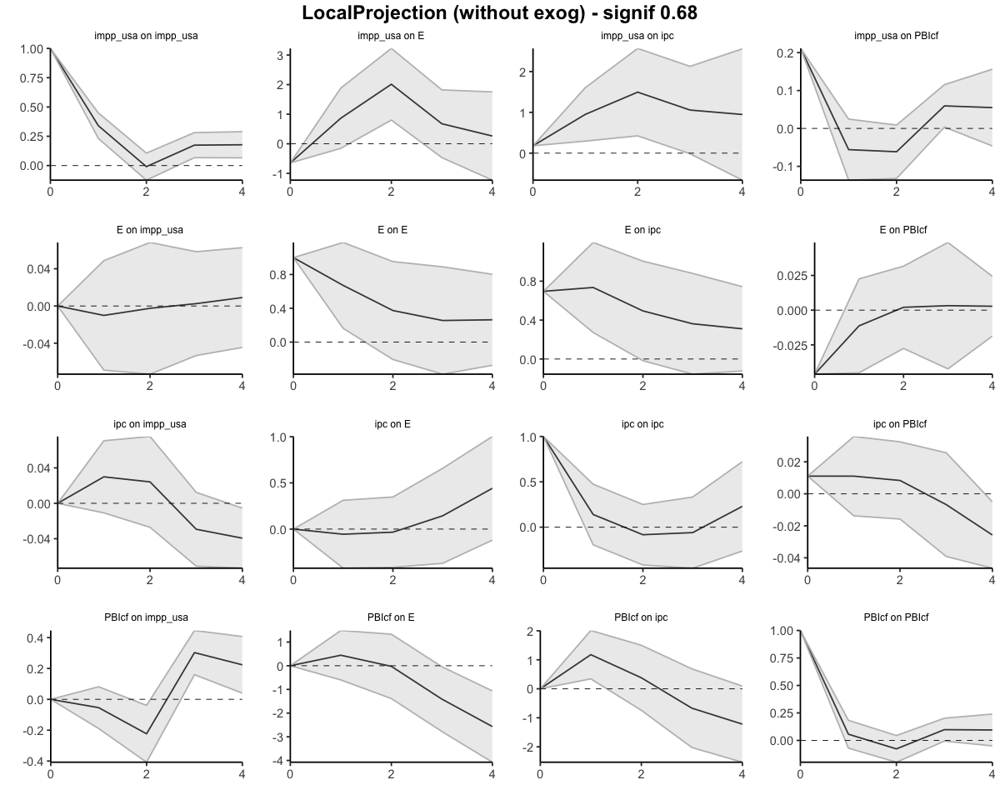

In [51]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("impp_usa", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,NA,FALSE,FALSE,0,1,88,"impp_usa, E, ipc, PBIcf",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-0.6472419,-0.6472419223,-0.6472419
2,impp_usa,E,1,0.2180097,-0.8019031654,1.2379225
3,impp_usa,E,2,2.2300047,-0.0006239688,4.4606335
4,impp_usa,E,3,2.9072568,-0.4682862220,6.2827998
5,impp_usa,E,4,3.1691270,-1.6978240643,8.0360781


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.0000000
37,ipc,E,1,-0.05573264,-0.4233467,0.3118814
38,ipc,E,2,-0.08923589,-0.8375190,0.6590473
39,ipc,E,3,0.05428976,-1.2080729,1.3166524
40,ipc,E,4,0.49573690,-1.3277679,2.3192417


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.0000000,0.000000
52,PBIcf,E,1,0.4439702,-0.5995791,1.487520
53,PBIcf,E,2,0.4178161,-1.9844084,2.820041
54,PBIcf,E,3,-0.9912372,-4.7601772,2.777703
55,PBIcf,E,4,-3.5594455,-8.8333186,1.714428


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
56,PBIcf,ipc,0,0.0000000,0.0000000,0.000000
57,PBIcf,ipc,1,1.1767083,0.3428466,2.010570
58,PBIcf,ipc,2,1.5567152,-0.3993607,3.512791
59,PBIcf,ipc,3,0.8890951,-2.4229191,4.201109
60,PBIcf,ipc,4,-0.3295784,-4.9545579,4.295401


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,E,PBIcf,0,-0.04611127,-0.04611127,-0.046111268
27,E,PBIcf,1,-0.05739562,-0.09122540,-0.023565845
28,E,PBIcf,2,-0.05532057,-0.11877446,0.008133333
29,E,PBIcf,3,-0.05208700,-0.16107832,0.056904327
30,E,PBIcf,4,-0.04926107,-0.17978741,0.081265276


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,impp_usa,PBIcf,0,0.21104669,0.21104669,0.2110467
12,impp_usa,PBIcf,1,0.15513374,0.07461446,0.2356530
13,impp_usa,PBIcf,2,0.09362824,-0.05735469,0.2446112
14,impp_usa,PBIcf,3,0.15311693,-0.05389370,0.3601276
15,impp_usa,PBIcf,4,0.20806891,-0.10025364,0.5163914


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
41,ipc,PBIcf,0,0.011059555,0.011059555,0.01105956
42,ipc,PBIcf,1,0.022097722,-0.002709939,0.04690538
43,ipc,PBIcf,2,0.030445262,-0.018492059,0.07938258
44,ipc,PBIcf,3,0.023708845,-0.057646014,0.10506370
45,ipc,PBIcf,4,-0.002042436,-0.104146314,0.10006144


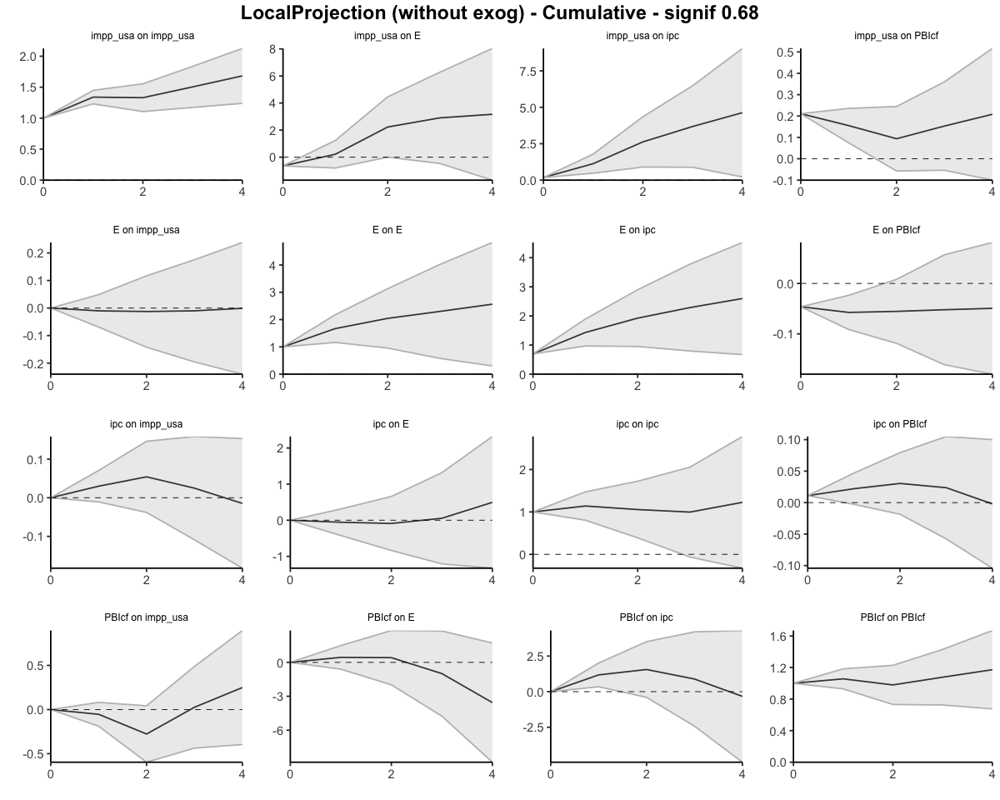

In [52]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("impp_usa", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, cumulative=TRUE)

#### Todas endógenas - 1 lag

Bootstrap por bloques circular: 500 réplicas, bloques de 10 años...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 1 rezagos )

Lineal
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.6957         0.6957       1.0000
         1              1.4309         0.8563       1.6710
         2              1.9252         0.9416       2.0446
         3              2.2872         0.9944       2.3001
         4              2.5977         1.0131       2.5641
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.6957             0.6957
                  0.7352             0.1606
                  0.4943             0.0853
                  0.3620             0.0528
                  0.3105             0.0187


Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'ERPT: shock en E sobre ipc (LP anual 1935–2023, fuentes combinadas, 1 rezago)' in 'mbcsToSbcs': - substituted for – (U+2013)”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'ERPT: shock en E sobre ipc (LP anual 1935–2023, fuentes combinadas, 1 rezago)' in 'mbcsToSbcs': - substituted for – (U+2013)”


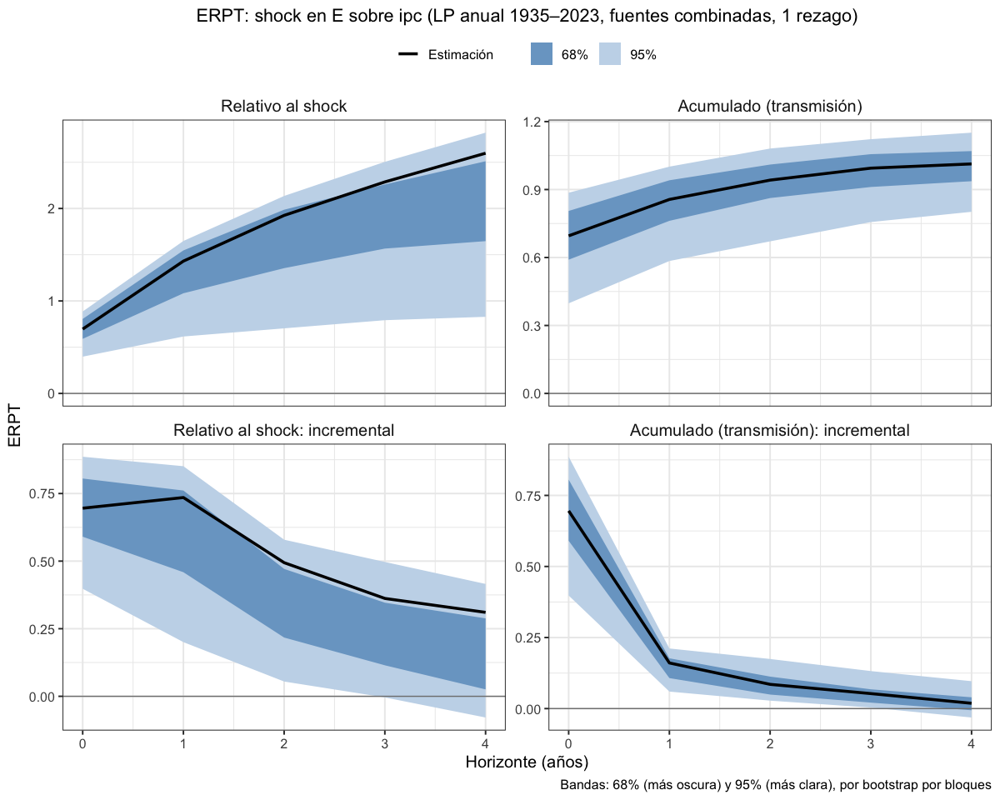

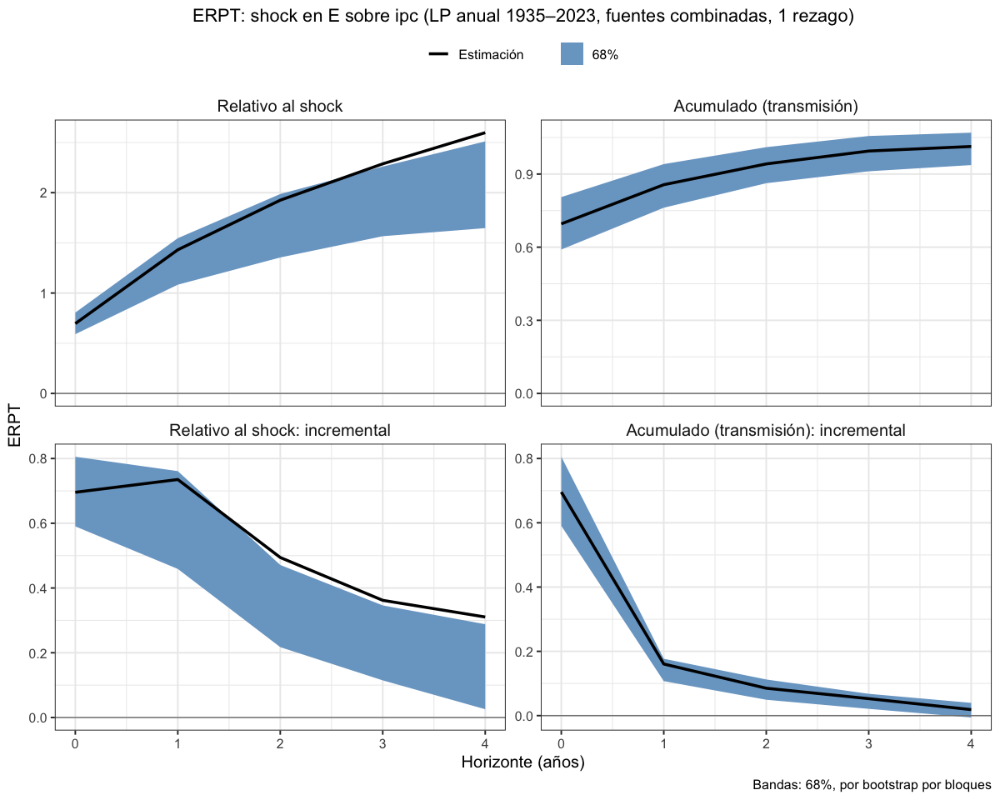

In [ ]:
# Anual 1935–2023, fuentes combinadas. Todas endógenas, 1 rezago
lp_erpt_anual_comb_endog_p1 <- erpt_lp(df_ERPT_Arg_1935_2023, endog = c("impp_usa", "E", "ipc", "PBIcf"),
                                       fixed_lags = 1, horizons = 4, reps = 500, unidad = "años")
saveRDS(lp_erpt_anual_comb_endog_p1, "lp_erpt_anual_comb_endog_p1.rds")
titulo_comb <- "ERPT: shock en E sobre ipc (LP anual 1935-2023, fuentes combinadas, 1 rezago)"
graficar_erpt_lp(lp_erpt_anual_comb_endog_p1, titulo = titulo_comb,
                 archivo = "lp_erpt_anual_comb_endog_p1")
graficar_erpt_lp(lp_erpt_anual_comb_endog_p1, titulo = titulo_comb, niveles = 0.68,
                 archivo = "lp_erpt_anual_comb_endog_p1_68")

Bootstrap por bloques: 300 réplicas, bloques de 15 años...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 1 rezagos )

Lineal
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.6957         0.6957       1.0000
         1              1.4309         0.8563       1.6710
         2              1.9252         0.9416       2.0446
         3              2.2872         0.9944       2.3001
         4              2.5977         1.0131       2.5641
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.6957             0.6957
                  0.7352             0.1606
                  0.4943             0.0853
                  0.3620             0.0528
                  0.3105             0.0187


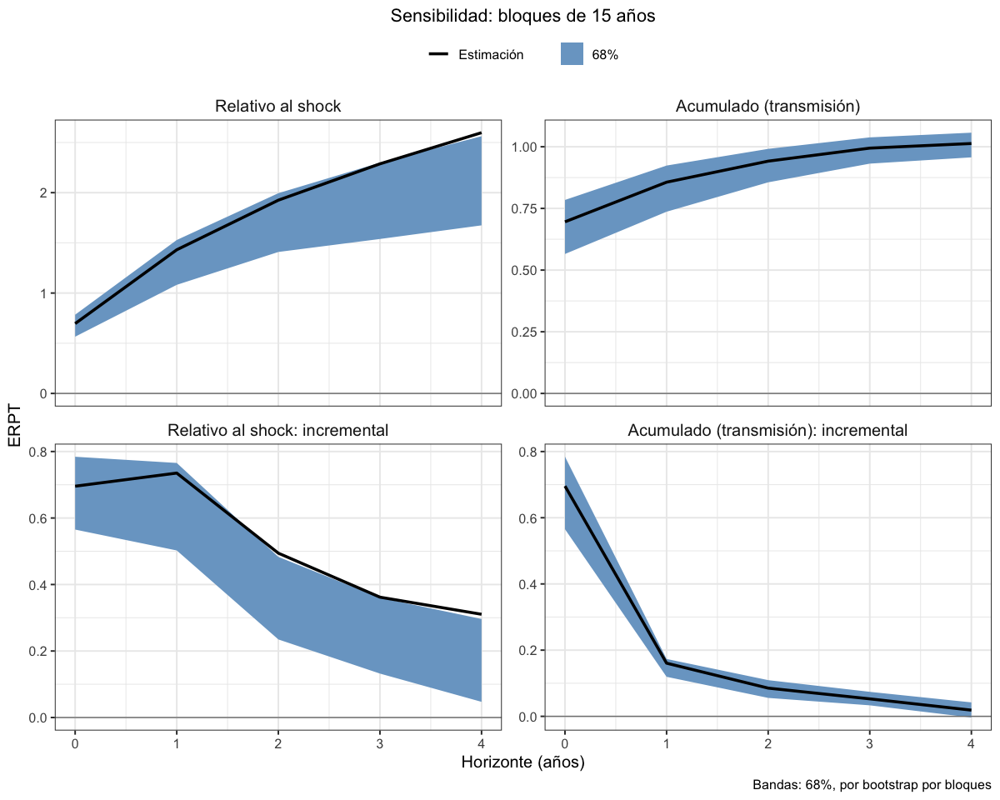

In [33]:
lp_sens_b15 <- erpt_lp(df_ERPT_Arg_1935_2023, endog = c("impp_usa", "E", "ipc", "PBIcf"),
                       fixed_lags = 1, horizons = 4, reps = 300, bloque = 15, unidad = "años")
graficar_erpt_lp(lp_sens_b15, niveles = 0.68, titulo = "Sensibilidad: bloques de 15 años")

### 1935-2023. 1 exógena y el resto endógenas - Selected orders: 1 lag

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,88,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.0000000
12,ipc,E,1,-0.04535342,-0.4373638,0.3466569
13,ipc,E,2,-0.03411468,-0.4465471,0.3783178
14,ipc,E,3,0.11058454,-0.4354463,0.6566153
15,ipc,E,4,0.38140711,-0.2149177,0.9777319


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.00000000,0.0000000,0.00000000
22,PBIcf,E,1,0.44397022,-0.5995791,1.48751957
23,PBIcf,E,2,-0.02615411,-1.3848293,1.33252105
24,PBIcf,E,3,-1.40905328,-2.7757688,-0.04233775
25,PBIcf,E,4,-2.56820828,-4.0731414,-1.06327521


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6863754,0.6863754,0.6863754
2,E,ipc,1,0.7308438,0.2734393,1.1882483
3,E,ipc,2,0.4941058,-0.0112457,0.9994573
4,E,ipc,3,0.3642984,-0.1463764,0.8749733
5,E,ipc,4,0.3114746,-0.1139119,0.7368611


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.0000000,0.0000000,0.00000000
27,PBIcf,ipc,1,1.1767083,0.3428466,2.01056999
28,PBIcf,ipc,2,0.3800069,-0.7422073,1.50222121
29,PBIcf,ipc,3,-0.6676201,-2.0235584,0.68831814
30,PBIcf,ipc,4,-1.2186735,-2.5316387,0.09429172


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.048790987,-0.04879099,-0.04879099
7,E,PBIcf,1,-0.011532969,-0.04480493,0.02173899
8,E,PBIcf,2,0.002195604,-0.02689078,0.03128199
9,E,PBIcf,3,0.003044293,-0.04192231,0.04801090
10,E,PBIcf,4,0.002821360,-0.01814759,0.02379031


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,0.034437736,0.03443774,0.0344377356
17,ipc,PBIcf,1,0.012359801,-0.01540978,0.0401293878
18,ipc,PBIcf,2,0.006547362,-0.02041938,0.0335141003
19,ipc,PBIcf,3,-0.004448947,-0.03930235,0.0304044523
20,ipc,PBIcf,4,-0.023530594,-0.04765983,0.0005986448


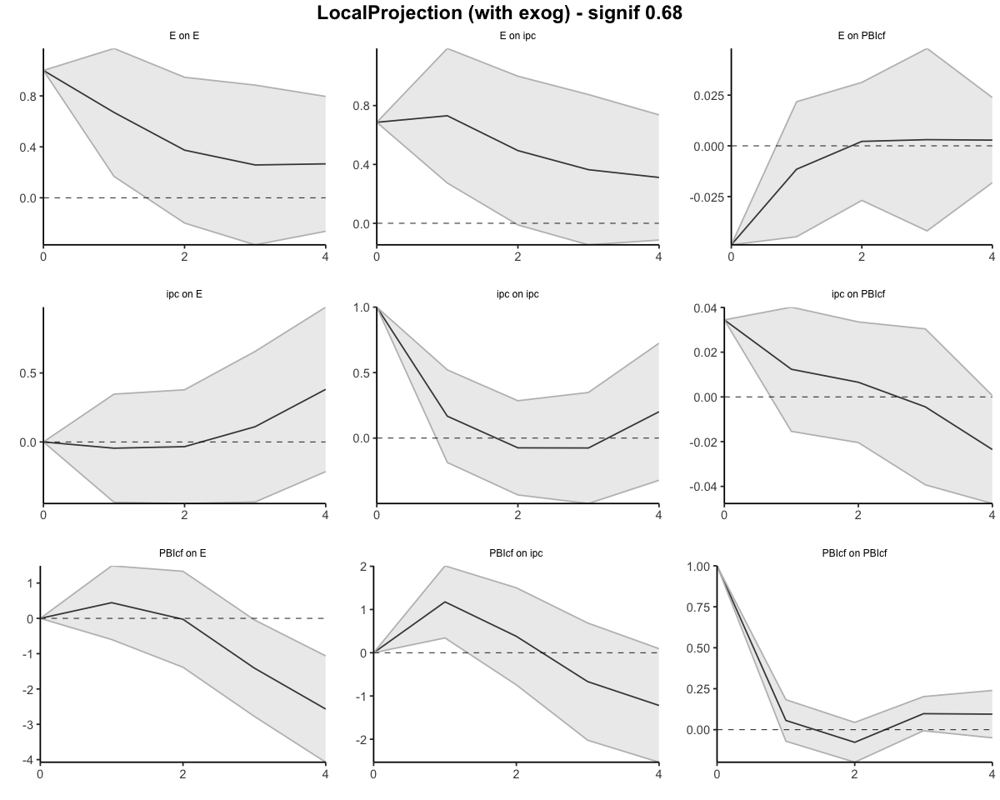

In [54]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("E", "ipc", "PBIcf"), exog=c("impp_usa"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,88,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.0000000
12,ipc,E,1,-0.04535342,-0.4373638,0.3466569
13,ipc,E,2,-0.07946811,-0.8839109,0.7249747
14,ipc,E,3,0.03111643,-1.3193571,1.3815900
15,ipc,E,4,0.41252355,-1.5342748,2.3593219


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.0000000,0.000000
22,PBIcf,E,1,0.4439702,-0.5995791,1.487520
23,PBIcf,E,2,0.4178161,-1.9844084,2.820041
24,PBIcf,E,3,-0.9912372,-4.7601772,2.777703
25,PBIcf,E,4,-3.5594455,-8.8333186,1.714428


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6863754,0.6863754,0.6863754
2,E,ipc,1,1.4172192,0.9598147,1.8746237
3,E,ipc,2,1.9113250,0.9485690,2.8740810
4,E,ipc,3,2.2756235,0.8021926,3.7490543
5,E,ipc,4,2.5870981,0.6882807,4.4859154


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.0000000,0.0000000,0.000000
27,PBIcf,ipc,1,1.1767083,0.3428466,2.010570
28,PBIcf,ipc,2,1.5567152,-0.3993607,3.512791
29,PBIcf,ipc,3,0.8890951,-2.4229191,4.201109
30,PBIcf,ipc,4,-0.3295784,-4.9545579,4.295401


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.04879099,-0.04879099,-0.048790987
7,E,PBIcf,1,-0.06032396,-0.09359592,-0.027051995
8,E,PBIcf,2,-0.05812835,-0.12048669,0.004229993
9,E,PBIcf,3,-0.05508406,-0.16240901,0.052240893
10,E,PBIcf,4,-0.05226270,-0.18055660,0.076031207


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,0.03443774,0.034437736,0.03443774
17,ipc,PBIcf,1,0.04679754,0.019027951,0.07456712
18,ipc,PBIcf,2,0.05334490,-0.001391425,0.10808122
19,ipc,PBIcf,3,0.04889595,-0.040693772,0.13848568
20,ipc,PBIcf,4,0.02536536,-0.088353605,0.13908432


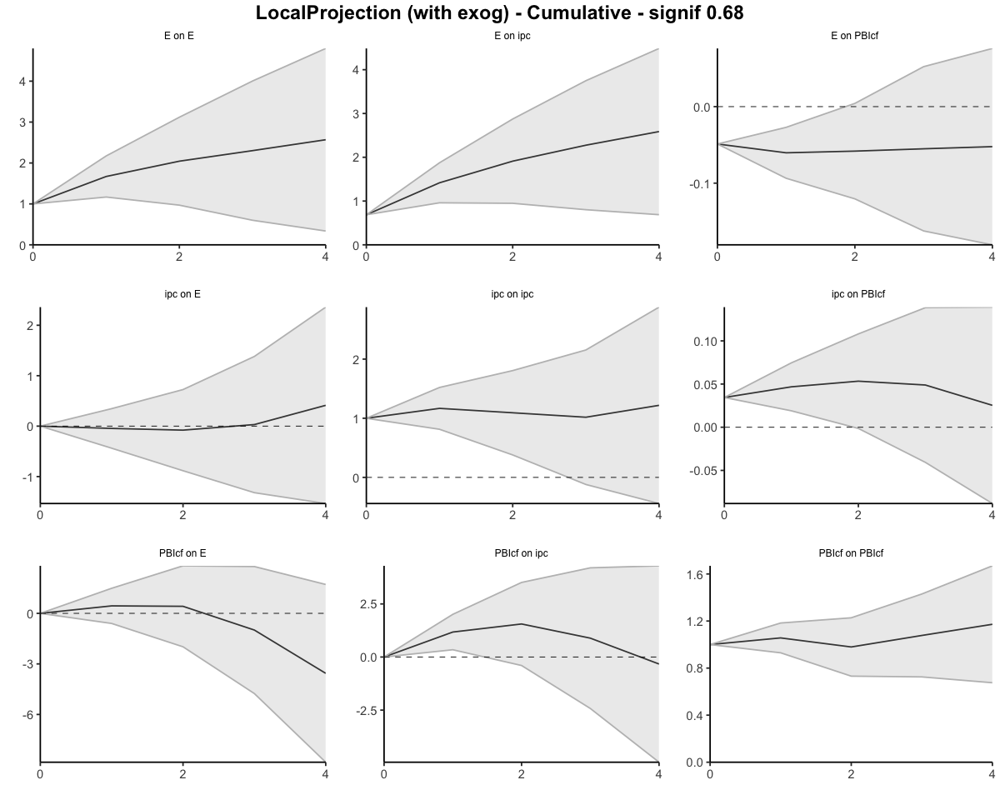

In [55]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("E", "ipc", "PBIcf"), exog=c("impp_usa"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

#### impp_usa exógena y el resto endógenas - Selected orders: 1 lag

Bootstrap por bloques circular: 500 réplicas, bloques de 10 años...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 1 rezagos, exógenas: impp_usa )

Lineal
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.6864         0.6864       1.0000
         1              1.4172         0.8485       1.6703
         2              1.9113         0.9349       2.0443
         3              2.2756         0.9885       2.3021
         4              2.5871         1.0072       2.5686
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.6864             0.6864
                  0.7308             0.1621
                  0.4941             0.0865
                  0.3643             0.0536
                  0.3115             0.0187


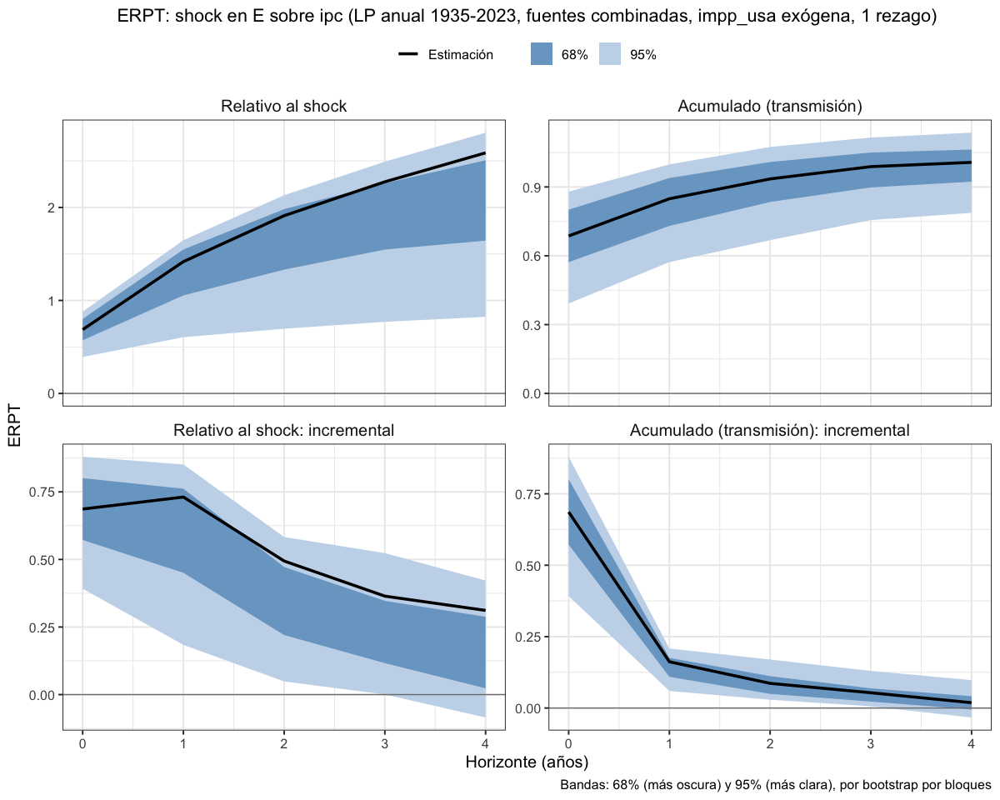

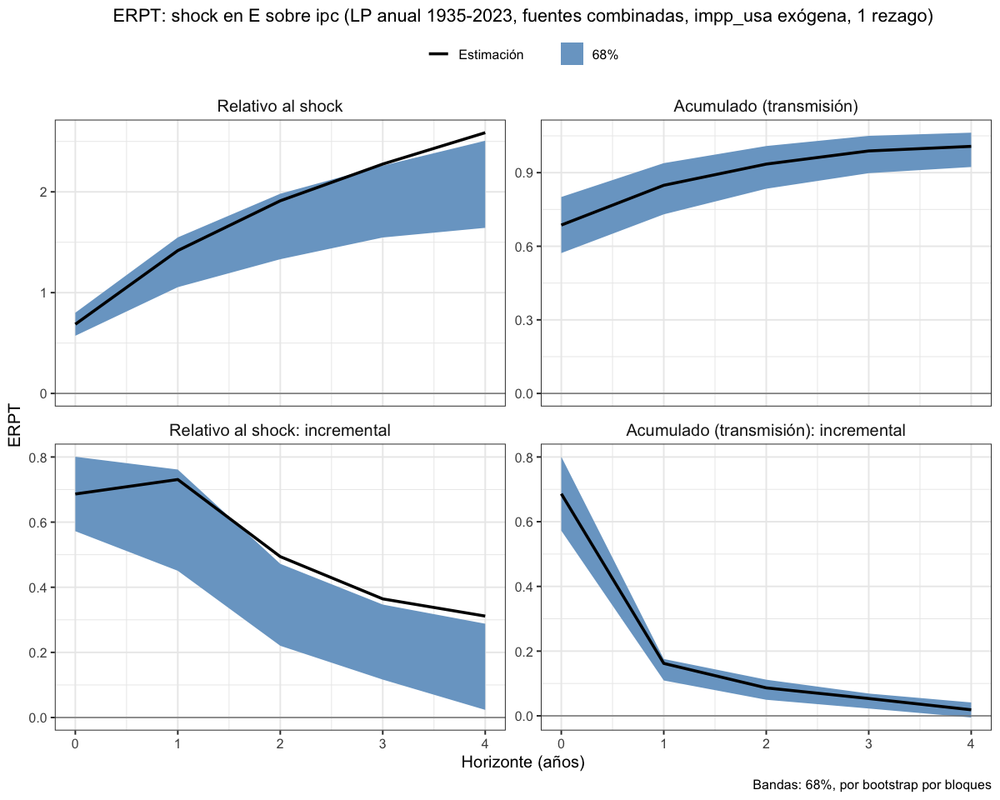

In [56]:
# Anual 1935–2023, fuentes combinadas. impp_usa exógena y el resto endógenas, 1 rezago
lp_erpt_anual_comb_exog_p1 <- erpt_lp(df_ERPT_Arg_1935_2023, endog = c("E", "ipc", "PBIcf"), exog = c("impp_usa"),
                                       fixed_lags = 1, horizons = 4, reps = 500, unidad = "años")
saveRDS(lp_erpt_anual_comb_exog_p1, "lp_erpt_anual_comb_exog_p1.rds")
titulo_comb_exog <- "ERPT: shock en E sobre ipc (LP anual 1935-2023, fuentes combinadas, impp_usa exógena, 1 rezago)"
graficar_erpt_lp(lp_erpt_anual_comb_exog_p1, titulo = titulo_comb_exog,
                 archivo = "lp_erpt_anual_comb_exog_p1")
graficar_erpt_lp(lp_erpt_anual_comb_exog_p1, titulo = titulo_comb_exog, niveles = 0.68,
                 archivo = "lp_erpt_anual_comb_exog_p1_68")

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,88,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.0000000
12,ipc,E,1,0.3551017,-0.05238012,0.7625836
13,ipc,E,2,-0.2344802,-0.72887585,0.2599154
14,ipc,E,3,-0.7980241,-1.48626183,-0.1097864
15,ipc,E,4,-0.4021283,-0.89844768,0.0941910


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.00000000,0.0000000
22,PBIcf,E,1,1.1504325,0.04113788,2.2597271
23,PBIcf,E,2,-0.3176517,-1.38616756,0.7508641
24,PBIcf,E,3,-2.1750884,-3.28050608,-1.0696707
25,PBIcf,E,4,-3.2167581,-4.82015319,-1.6133629


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6824676,0.6824676,0.6824676
2,E,ipc,1,0.7925409,0.4427649,1.1423169
3,E,ipc,2,0.4398866,-0.1949440,1.0747172
4,E,ipc,3,0.1910713,-0.6184510,1.0005936
5,E,ipc,4,0.1603969,-0.5358632,0.8566570


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.0000000,0.0000000,0.0000000
27,PBIcf,ipc,1,1.7372740,0.8310644,2.6434837
28,PBIcf,ipc,2,0.1958858,-0.6394053,1.0311770
29,PBIcf,ipc,3,-1.4870231,-2.5810180,-0.3930281
30,PBIcf,ipc,4,-1.9762582,-3.2554017,-0.6971147


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.0487827437,-0.04878274,-0.04878274
7,E,PBIcf,1,-0.0161404831,-0.05080993,0.01852897
8,E,PBIcf,2,-0.0003337623,-0.03433347,0.03366594
9,E,PBIcf,3,0.0054750056,-0.05136805,0.06231806
10,E,PBIcf,4,0.0017075483,-0.02671956,0.03013466


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,0.044659226,0.04465923,0.04465923
17,ipc,PBIcf,1,-0.015863746,-0.04868934,0.01696185
18,ipc,PBIcf,2,-0.001330197,-0.03470748,0.03204708
19,ipc,PBIcf,3,0.021064277,-0.02669387,0.06882242
20,ipc,PBIcf,4,-0.000124976,-0.03366331,0.03341336


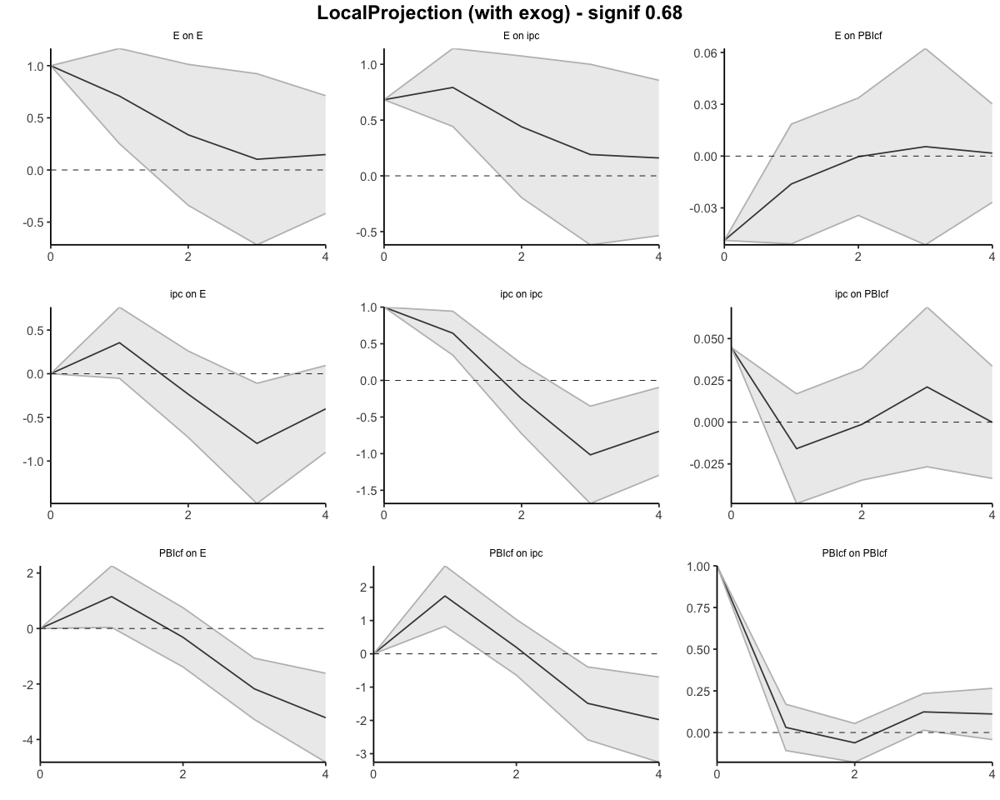

In [57]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("E", "ipc", "PBIcf"), exog=c("impp_usa"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,88,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.0000000
12,ipc,E,1,0.3551017,-0.05238012,0.7625836
13,ipc,E,2,0.1206215,-0.78125597,1.0224990
14,ipc,E,3,-0.6774026,-2.26751780,0.9127126
15,ipc,E,4,-1.0795309,-3.16596548,1.0069036


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.00000000,0.0000000
22,PBIcf,E,1,1.1504325,0.04113788,2.2597271
23,PBIcf,E,2,0.8327808,-1.34502967,3.0105912
24,PBIcf,E,3,-1.3423076,-4.62553575,1.9409205
25,PBIcf,E,4,-4.5590657,-9.44568894,0.3275576


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6824676,0.6824676,0.6824676
2,E,ipc,1,1.4750085,1.1252325,1.8247845
3,E,ipc,2,1.9148951,0.9302885,2.8995017
4,E,ipc,3,2.1059664,0.3118375,3.9000953
5,E,ipc,4,2.2663633,-0.2240257,4.7567523


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.0000000,0.0000000,0.000000
27,PBIcf,ipc,1,1.7372740,0.8310644,2.643484
28,PBIcf,ipc,2,1.9331598,0.1916590,3.674661
29,PBIcf,ipc,3,0.4461368,-2.3893589,3.281632
30,PBIcf,ipc,4,-1.5301215,-5.6447607,2.584518


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.04878274,-0.04878274,-0.048782744
7,E,PBIcf,1,-0.06492323,-0.09959268,-0.030253777
8,E,PBIcf,2,-0.06525699,-0.13392614,0.003412167
9,E,PBIcf,3,-0.05978198,-0.18529419,0.065730226
10,E,PBIcf,4,-0.05807444,-0.21201375,0.095864882


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,0.04465923,0.044659226,0.04465923
17,ipc,PBIcf,1,0.02879548,-0.004030119,0.06162108
18,ipc,PBIcf,2,0.02746528,-0.038737594,0.09366816
19,ipc,PBIcf,3,0.04852956,-0.065431462,0.16249058
20,ipc,PBIcf,4,0.04840458,-0.099094770,0.19590394


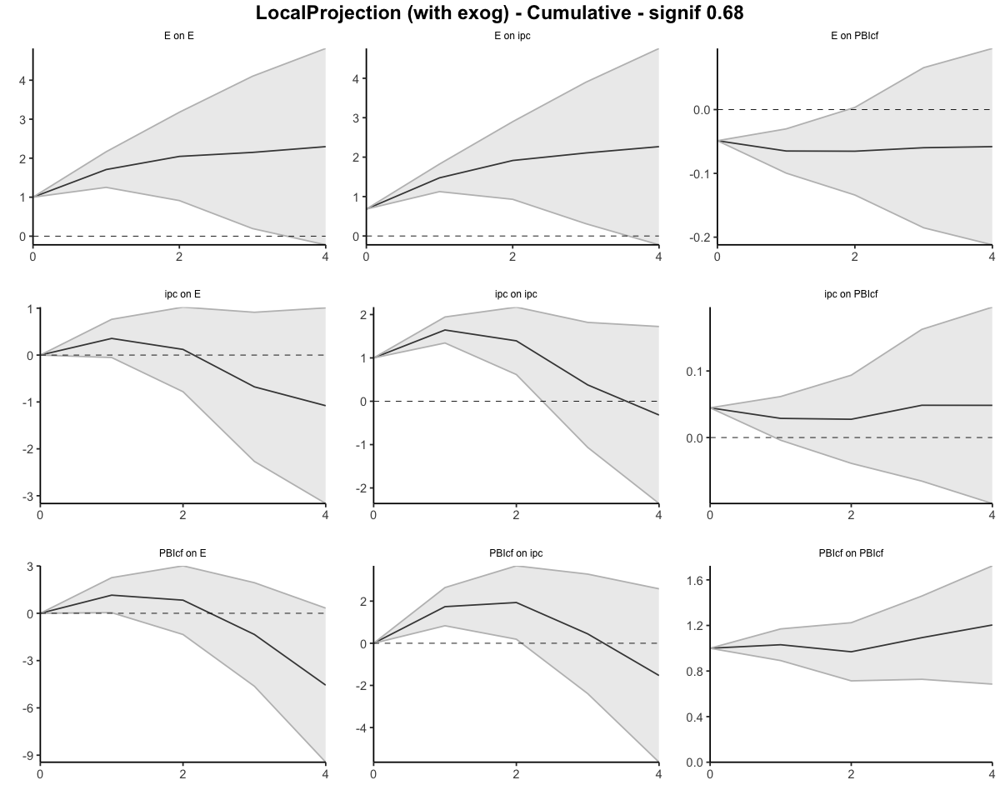

In [58]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("E", "ipc", "PBIcf"), exog=c("impp_usa"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4, cumulative = TRUE)

#### impp_usa exógena y el resto endógenas - 2 lags (subo 1 lag porque en VAR 1 lag no es RB)

Bootstrap por bloques circular: 500 réplicas, bloques de 12 años...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 2 rezagos, exógenas: impp_usa )

Lineal
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.6825         0.6825       1.0000
         1              1.4750         0.8632       1.7087
         2              1.9149         0.9360       2.0458
         3              2.1060         0.9802       2.1486
         4              2.2664         0.9869       2.2964
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.6825             0.6825
                  0.7925             0.1808
                  0.4399             0.0728
                  0.1911             0.0442
                  0.1604             0.0067


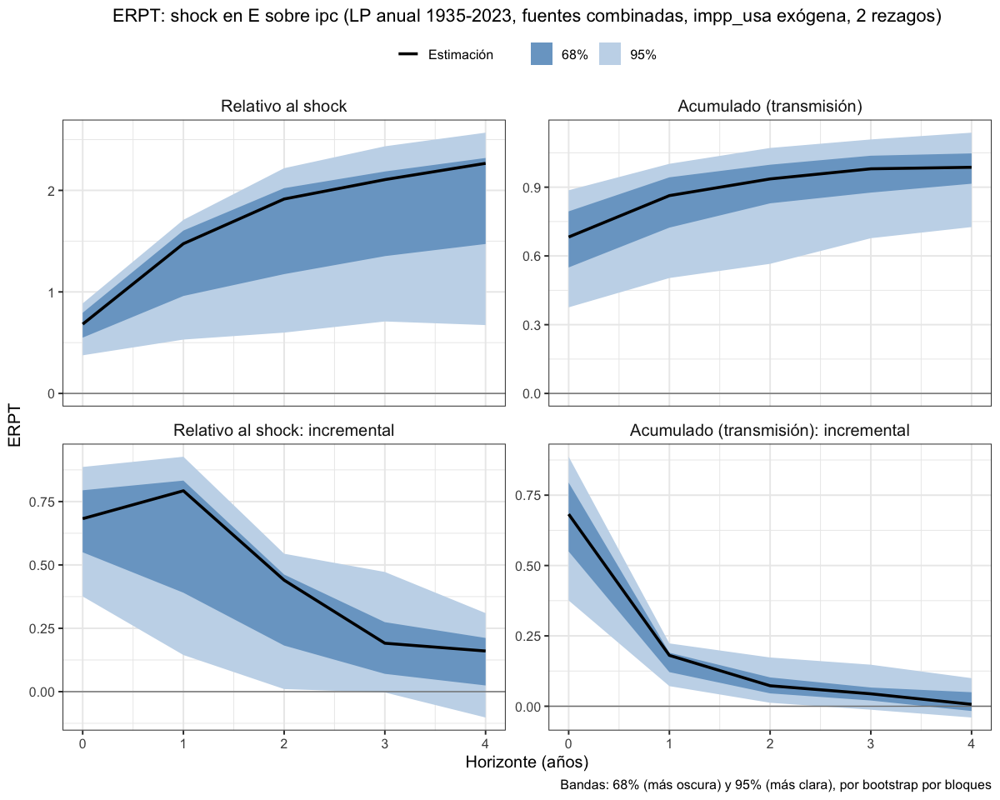

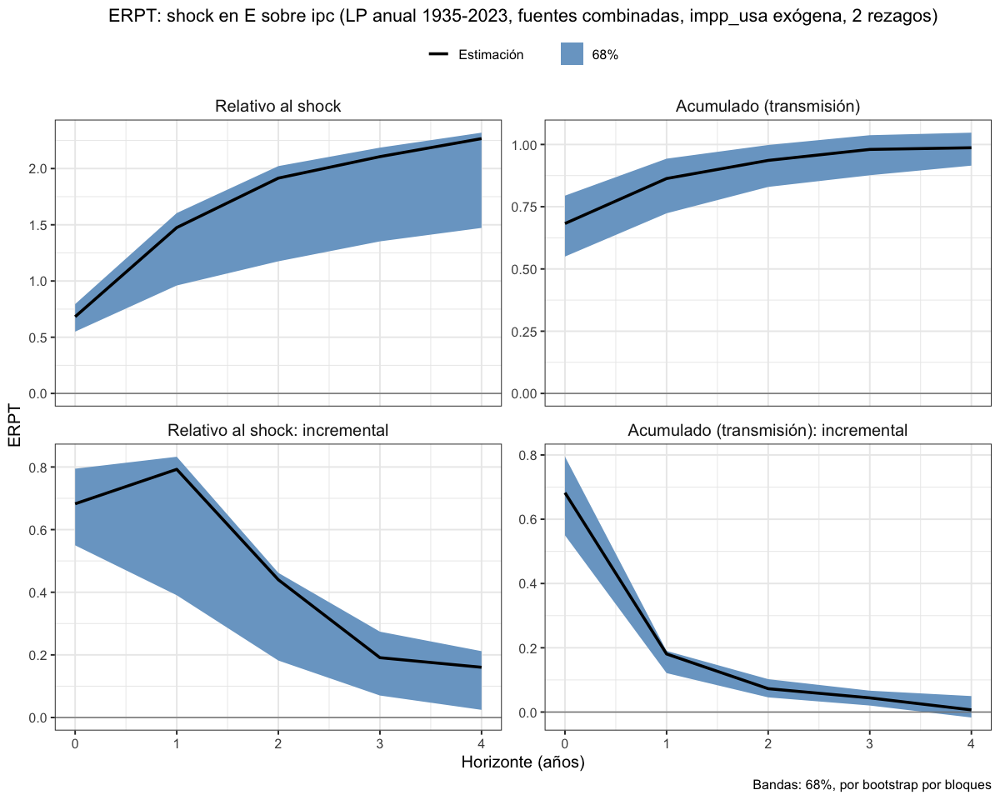

In [59]:
# Anual 1935–2023, fuentes combinadas. impp_usa exógena y el resto endógenas, 2 rezagos
lp_erpt_anual_comb_exog_p2 <- erpt_lp(df_ERPT_Arg_1935_2023, endog = c("E", "ipc", "PBIcf"), exog = c("impp_usa"),
                                       fixed_lags = 2, horizons = 4, reps = 500, unidad = "años")
saveRDS(lp_erpt_anual_comb_exog_p2, "lp_erpt_anual_comb_exog_p2.rds")
titulo_comb_exog <- "ERPT: shock en E sobre ipc (LP anual 1935-2023, fuentes combinadas, impp_usa exógena, 2 rezagos)"
graficar_erpt_lp(lp_erpt_anual_comb_exog_p2, titulo = titulo_comb_exog,
                 archivo = "lp_erpt_anual_comb_exog_p2")
graficar_erpt_lp(lp_erpt_anual_comb_exog_p2, titulo = titulo_comb_exog, niveles = 0.68,
                 archivo = "lp_erpt_anual_comb_exog_p2_68")

### 1935-1974. Todas endógenas

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"impp_usa, E, ipc, PBIcf",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-0.2558538,-0.2558538,-0.2558538
2,impp_usa,E,1,-0.8232977,-1.1432779,-0.5033174
3,impp_usa,E,2,-0.1437166,-0.4545429,0.1671098
4,impp_usa,E,3,-0.1197030,-0.8022069,0.5628009
5,impp_usa,E,4,-0.3203454,-0.7597167,0.1190258


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.00000000
37,ipc,E,1,-0.1518549,-0.2205507,-0.08315915
38,ipc,E,2,-0.1646625,-0.2815512,-0.04777372
39,ipc,E,3,0.0277881,-0.1300131,0.18558932
40,ipc,E,4,0.5917967,0.3964386,0.78715479


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.000000,0.0000000,0.000000
52,PBIcf,E,1,2.075581,1.4200630,2.731099
53,PBIcf,E,2,2.413567,1.8145911,3.012544
54,PBIcf,E,3,1.792472,0.8533999,2.731545
55,PBIcf,E,4,-0.286740,-1.6307629,1.057283


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
56,PBIcf,ipc,0,0.000000,0.0000000,0.000000
57,PBIcf,ipc,1,2.026976,1.3784018,2.675551
58,PBIcf,ipc,2,2.047176,1.5650737,2.529279
59,PBIcf,ipc,3,1.308457,0.7554885,1.861426
60,PBIcf,ipc,4,1.401331,0.3680302,2.434633


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,E,PBIcf,0,-0.057433856,-0.05743386,-0.057433856
27,E,PBIcf,1,-0.025542650,-0.04663826,-0.004447045
28,E,PBIcf,2,0.017425594,-0.02725974,0.062110926
29,E,PBIcf,3,-0.058895187,-0.11461133,-0.003179042
30,E,PBIcf,4,-0.007160191,-0.02595010,0.011629716


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,impp_usa,PBIcf,0,0.124698657,0.12469866,0.12469866
12,impp_usa,PBIcf,1,-0.001264169,-0.11808855,0.11556022
13,impp_usa,PBIcf,2,-0.047335998,-0.11374291,0.01907091
14,impp_usa,PBIcf,3,-0.060584474,-0.13832860,0.01715965
15,impp_usa,PBIcf,4,0.088003771,-0.01652991,0.19253745


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
41,ipc,PBIcf,0,-0.142310277,-0.14231028,-0.14231028
42,ipc,PBIcf,1,0.040055159,0.03613206,0.04397825
43,ipc,PBIcf,2,0.042986043,0.02527204,0.06070004
44,ipc,PBIcf,3,-0.009834256,-0.05174175,0.03207323
45,ipc,PBIcf,4,-0.055500209,-0.05714231,-0.05385811


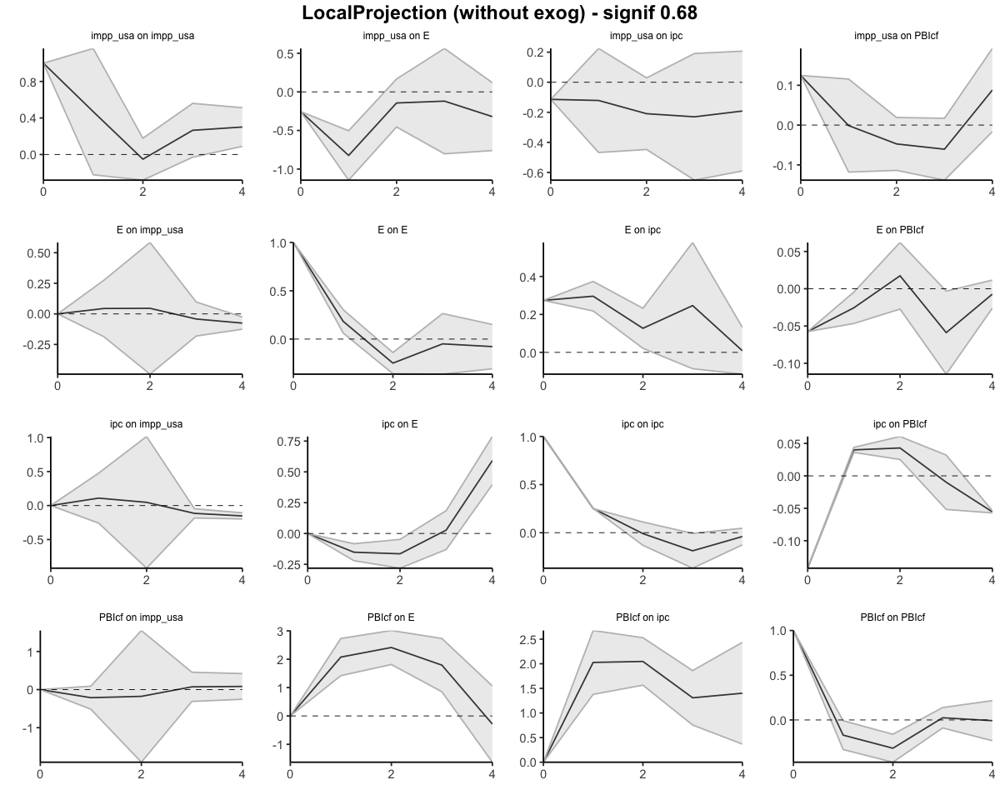

In [60]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("impp_usa", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"impp_usa, E, ipc, PBIcf",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-0.2558538,-0.2558538,-0.25585382
2,impp_usa,E,1,-1.0791515,-1.3991317,-0.75917125
3,impp_usa,E,2,-1.2228681,-1.8536746,-0.59206150
4,impp_usa,E,3,-1.3425710,-2.6558815,-0.02926056
5,impp_usa,E,4,-1.6629165,-3.4155982,0.08976526


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.00000000
37,ipc,E,1,-0.1518549,-0.2205507,-0.08315915
38,ipc,E,2,-0.3165174,-0.5021019,-0.13093286
39,ipc,E,3,-0.2887293,-0.6321151,0.05465646
40,ipc,E,4,0.3030674,-0.2356765,0.84181125


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.000000,0.000000,0.000000
52,PBIcf,E,1,2.075581,1.420063,2.731099
53,PBIcf,E,2,4.489148,3.234654,5.743643
54,PBIcf,E,3,6.281621,4.088054,8.475188
55,PBIcf,E,4,5.994881,2.457291,9.532471


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
56,PBIcf,ipc,0,0.000000,0.000000,0.000000
57,PBIcf,ipc,1,2.026976,1.378402,2.675551
58,PBIcf,ipc,2,4.074153,2.943476,5.204830
59,PBIcf,ipc,3,5.382610,3.698964,7.066256
60,PBIcf,ipc,4,6.783941,4.066994,9.500889


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,E,PBIcf,0,-0.05743386,-0.05743386,-0.0574338562
27,E,PBIcf,1,-0.08297651,-0.10407211,-0.0618809011
28,E,PBIcf,2,-0.06555091,-0.13133185,0.0002300245
29,E,PBIcf,3,-0.12444610,-0.24594318,-0.0029490176
30,E,PBIcf,4,-0.13160629,-0.27189328,0.0086806983


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,impp_usa,PBIcf,0,0.12469866,0.124698657,0.1246987
12,impp_usa,PBIcf,1,0.12343449,0.006610102,0.2402589
13,impp_usa,PBIcf,2,0.07609849,-0.107132804,0.2593298
14,impp_usa,PBIcf,3,0.01551402,-0.245461406,0.2764894
15,impp_usa,PBIcf,4,0.10351779,-0.261991313,0.4690269


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
41,ipc,PBIcf,0,-0.14231028,-0.14231028,-0.142310277
42,ipc,PBIcf,1,-0.10225512,-0.10617821,-0.098332023
43,ipc,PBIcf,2,-0.05926908,-0.08090617,-0.037631981
44,ipc,PBIcf,3,-0.06910333,-0.13264792,-0.005558746
45,ipc,PBIcf,4,-0.12460354,-0.18979023,-0.059416853


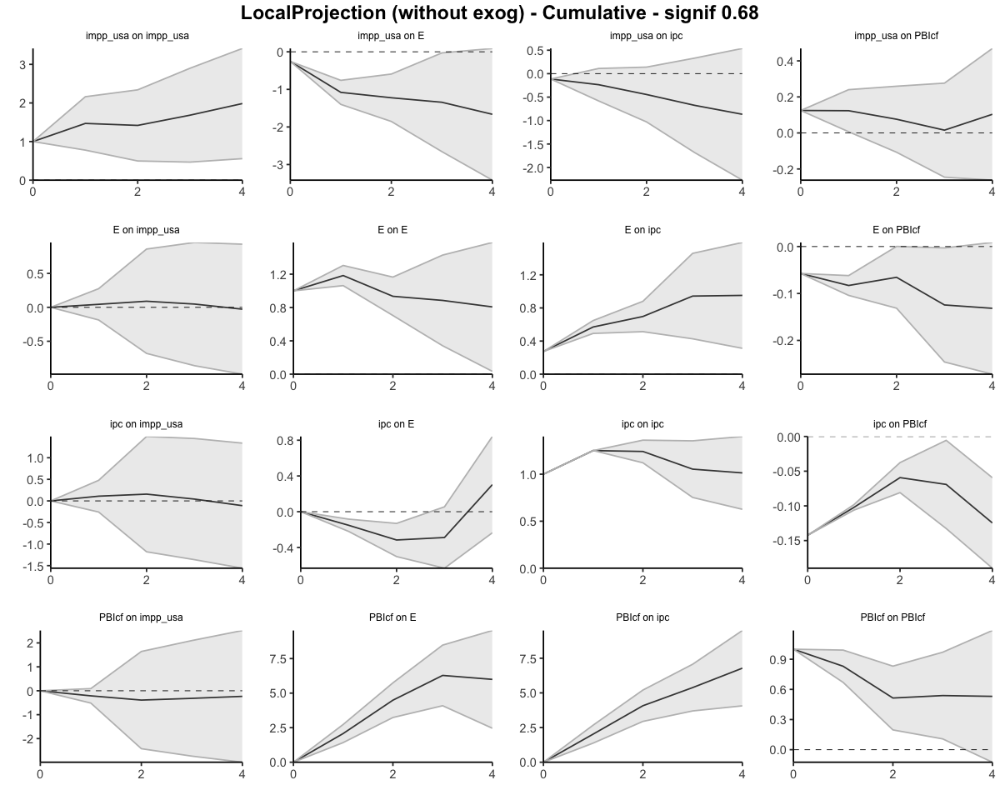

In [61]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("impp_usa", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

#### Todas endógenas - 1 lag

Bootstrap por bloques circular: 500 réplicas, bloques de 10 años...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 1 rezagos )

Lineal
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.2740         0.2740       1.0000
         1              0.5699         0.4815       1.1837
         2              0.6967         0.7454       0.9346
         3              0.9433         1.0656       0.8852
         4              0.9516         1.1788       0.8073
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.2740             0.2740
                  0.2960             0.2075
                  0.1268             0.2639
                  0.2465             0.3202
                  0.0083             0.1132


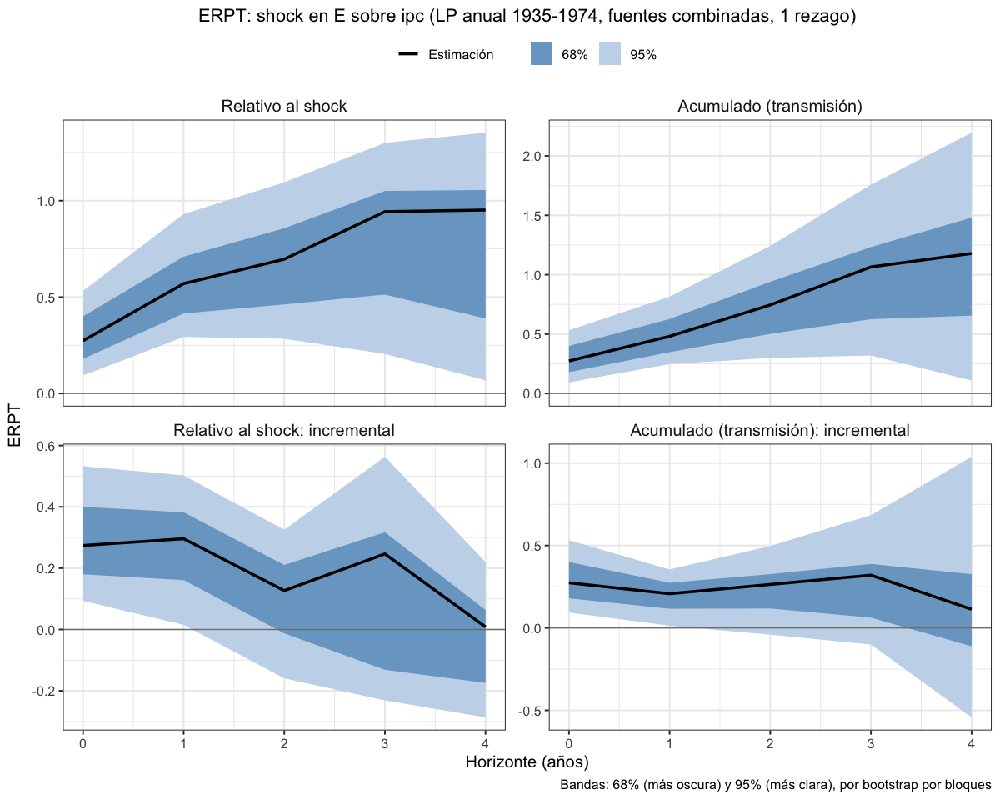

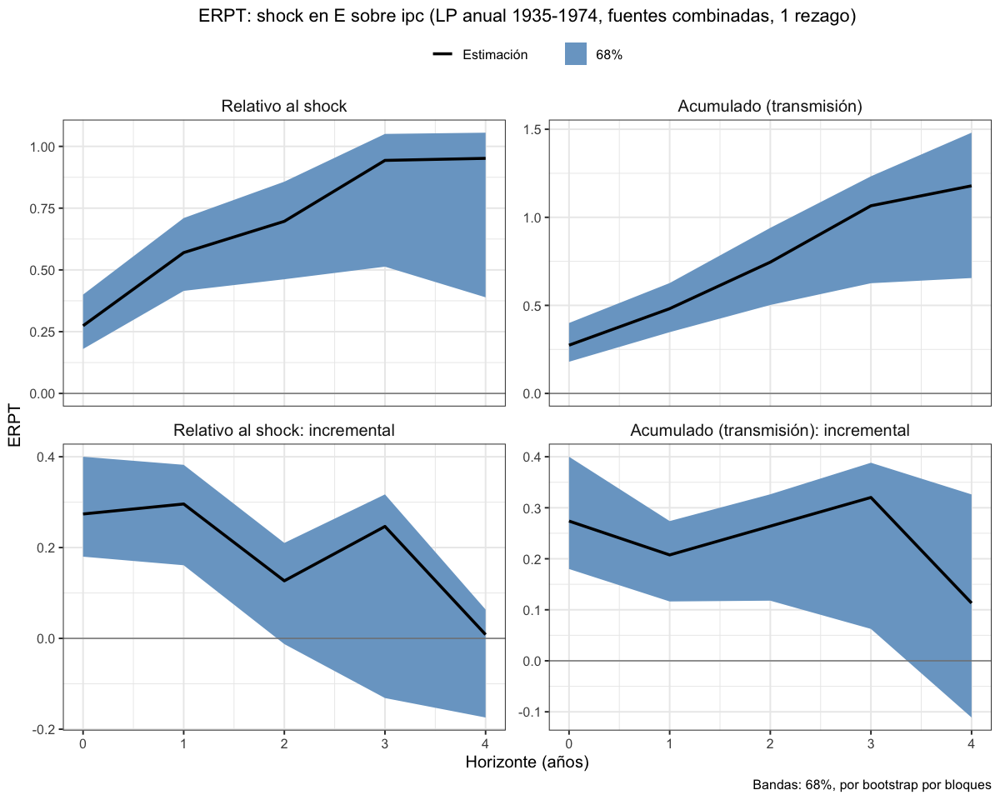

In [62]:
# Anual 1935–1974, fuentes combinadas. Todas endógenas, 1 rezago
lp_erpt_anual_comb_35_74_endog_p1 <- erpt_lp(df_ERPT_Arg_1935_1974, endog = c("impp_usa", "E", "ipc", "PBIcf"),
                                             fixed_lags = 1, horizons = 4, reps = 500, unidad = "años")
saveRDS(lp_erpt_anual_comb_35_74_endog_p1, "lp_erpt_anual_comb_35_74_endog_p1.rds")
titulo_comb_35_74 <- "ERPT: shock en E sobre ipc (LP anual 1935-1974, fuentes combinadas, 1 rezago)"
graficar_erpt_lp(lp_erpt_anual_comb_35_74_endog_p1, titulo = titulo_comb_35_74,
                 archivo = "lp_erpt_anual_comb_35_74_endog_p1")
graficar_erpt_lp(lp_erpt_anual_comb_35_74_endog_p1, titulo = titulo_comb_35_74, niveles = 0.68,
                 archivo = "lp_erpt_anual_comb_35_74_endog_p1_68")

#### Para diagnosticar por qué 1935-74 anual es tanto mayor que 1950-74 trimestral

In [47]:
diag_35_74_orden <- erpt_lp(df_ERPT_Arg_1935_1974, endog = c("impp_usa", "ipc", "E", "PBIcf"),
                            fixed_lags = 1, horizons = 4, reps = 0, unidad = "años")

Warning message in erpt_lp(df_ERPT_Arg_1935_1974, endog = c("impp_usa", "ipc", "E", :
“Con Cholesky, E va después de ipc: el ipc no responde en el impacto. Revisá el orden.”


ERPT de un shock unitario en E sobre ipc ( LP, 1 rezagos )

Lineal
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.0000         0.0000       1.0000
         1              0.2271         0.1854       1.2253
         2              0.3565         0.3491       1.0213
         3              0.6546         0.6788       0.9643
         4              0.6739         0.9304       0.7242
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.0000             0.0000
                  0.2271             0.1854
                  0.1294             0.1637
                  0.2980             0.3298
                  0.0193             0.2516


Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
6,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"impp_usa, E, ipc, PBIcf",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-0.211598145,-0.2115981,-0.2115981
2,impp_usa,E,1,0.065885124,-0.3229879,0.4547581
3,impp_usa,E,2,-1.389707920,-1.9652296,-0.8141863
4,impp_usa,E,3,-0.448997317,-3.0886361,2.1906415
5,impp_usa,E,4,-0.005166115,-0.2579314,0.2475992


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.00000000,0.00000000
37,ipc,E,1,-0.1862383,-0.30040158,-0.07207506
38,ipc,E,2,-1.2613595,-1.36594513,-1.15677393
39,ipc,E,3,-0.2162873,0.05239428,-0.48496891
40,ipc,E,4,0.9031270,0.74702501,1.05922892


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.000000,0.0000000
52,PBIcf,E,1,-0.3975937,-1.102240,0.3070528
53,PBIcf,E,2,5.1123152,3.354714,6.8699159
54,PBIcf,E,3,5.1934352,2.649774,7.7370960
55,PBIcf,E,4,-0.6618869,-0.878602,-0.4451719


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
56,PBIcf,ipc,0,0.000000,0.0000000,0.000000
57,PBIcf,ipc,1,1.401379,0.7730582,2.029699
58,PBIcf,ipc,2,3.083732,1.6274681,4.539996
59,PBIcf,ipc,3,3.927510,3.0809180,4.774102
60,PBIcf,ipc,4,2.764630,2.5444723,2.984788


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,E,PBIcf,0,-0.05302022,-0.05302022,-0.05302022
27,E,PBIcf,1,-0.14111386,-0.14261046,-0.13961727
28,E,PBIcf,2,-0.02252025,-0.03425927,-0.01078123
29,E,PBIcf,3,0.07639397,0.06367248,0.08911545
30,E,PBIcf,4,0.03408728,0.03466585,0.03350871


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,impp_usa,PBIcf,0,0.13852983,0.138529830,0.13852983
12,impp_usa,PBIcf,1,-0.27499124,-0.336769469,-0.21321301
13,impp_usa,PBIcf,2,0.07519462,-0.006182833,0.15657207
14,impp_usa,PBIcf,3,0.31113184,0.204178860,0.41808482
15,impp_usa,PBIcf,4,0.05547203,0.024860456,0.08608361


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
41,ipc,PBIcf,0,-0.17285717,-0.172857168,-0.17285717
42,ipc,PBIcf,1,0.04685846,0.064036127,0.02968080
43,ipc,PBIcf,2,0.19559139,0.177870021,0.21331276
44,ipc,PBIcf,3,-0.01210840,-0.005331016,-0.01888578
45,ipc,PBIcf,4,-0.09421868,-0.079766332,-0.10867103


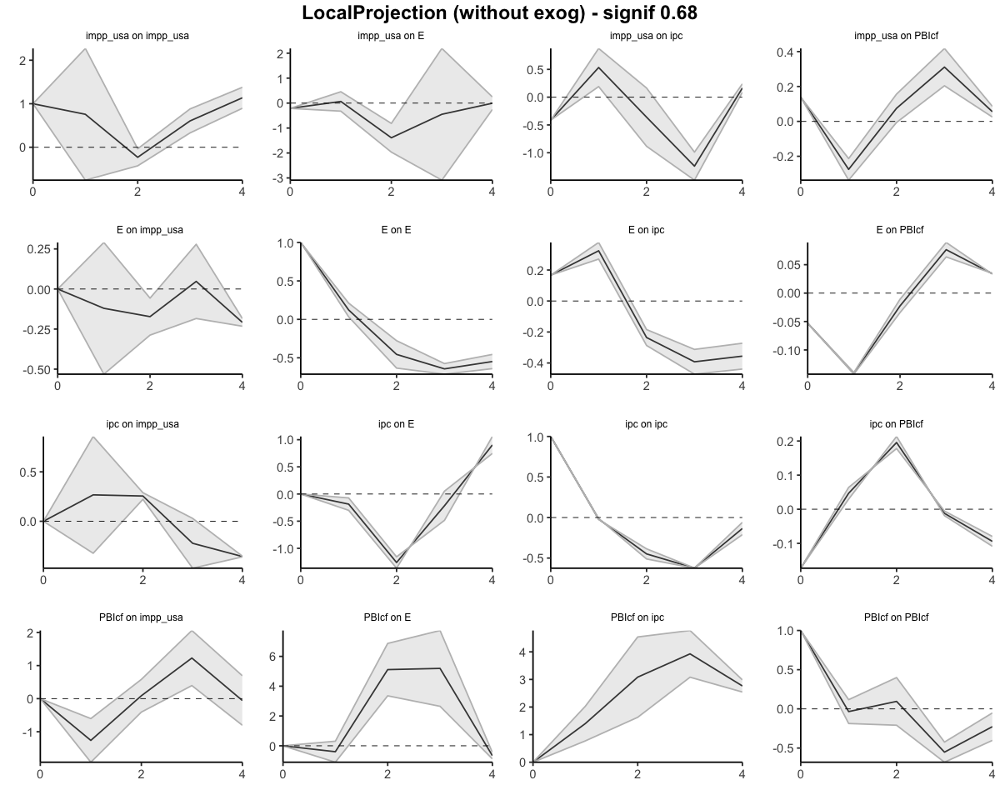

In [63]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("impp_usa", "E", "ipc", "PBIcf"), fixed_lags = 6, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
6,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"impp_usa, E, ipc, PBIcf",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-0.2115981,-0.2115981,-0.2115981
2,impp_usa,E,1,-0.1457130,-0.5345860,0.2431600
3,impp_usa,E,2,-1.5354209,-2.4998156,-0.5710263
4,impp_usa,E,3,-1.9844183,-5.5884517,1.6196152
5,impp_usa,E,4,-1.9895844,-5.8463831,1.8672144


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.00000000
37,ipc,E,1,-0.1862383,-0.3004016,-0.07207506
38,ipc,E,2,-1.4475978,-1.6663467,-1.22884899
39,ipc,E,3,-1.6638852,-1.6139524,-1.71381791
40,ipc,E,4,-0.7607582,-0.8669274,-0.65458899


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.000000,0.0000000
52,PBIcf,E,1,-0.3975937,-1.102240,0.3070528
53,PBIcf,E,2,4.7147215,2.252474,7.1769687
54,PBIcf,E,3,9.9081567,4.902249,14.9140648
55,PBIcf,E,4,9.2462697,4.023647,14.4688929


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
56,PBIcf,ipc,0,0.000000,0.0000000,0.000000
57,PBIcf,ipc,1,1.401379,0.7730582,2.029699
58,PBIcf,ipc,2,4.485110,2.4005263,6.569694
59,PBIcf,ipc,3,8.412620,5.4814443,11.343796
60,PBIcf,ipc,4,11.177250,8.0259165,14.328584


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,E,PBIcf,0,-0.05302022,-0.05302022,-0.05302022
27,E,PBIcf,1,-0.19413409,-0.19563068,-0.19263749
28,E,PBIcf,2,-0.21665434,-0.22988996,-0.20341872
29,E,PBIcf,3,-0.14026037,-0.16621748,-0.11430327
30,E,PBIcf,4,-0.10617310,-0.13155163,-0.08079456


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,impp_usa,PBIcf,0,0.13852983,0.1385298295,0.13852983
12,impp_usa,PBIcf,1,-0.13646141,-0.1982396394,-0.07468318
13,impp_usa,PBIcf,2,-0.06126679,-0.2044224724,0.08188889
14,impp_usa,PBIcf,3,0.24986505,-0.0002436123,0.49997371
15,impp_usa,PBIcf,4,0.30533708,0.0246168440,0.58605732


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
41,ipc,PBIcf,0,-0.17285717,-0.17285717,-0.17285717
42,ipc,PBIcf,1,-0.12599871,-0.10882104,-0.14317637
43,ipc,PBIcf,2,0.06959268,0.06904898,0.07013639
44,ipc,PBIcf,3,0.05748429,0.06371796,0.05125061
45,ipc,PBIcf,4,-0.03673440,-0.01604837,-0.05742042


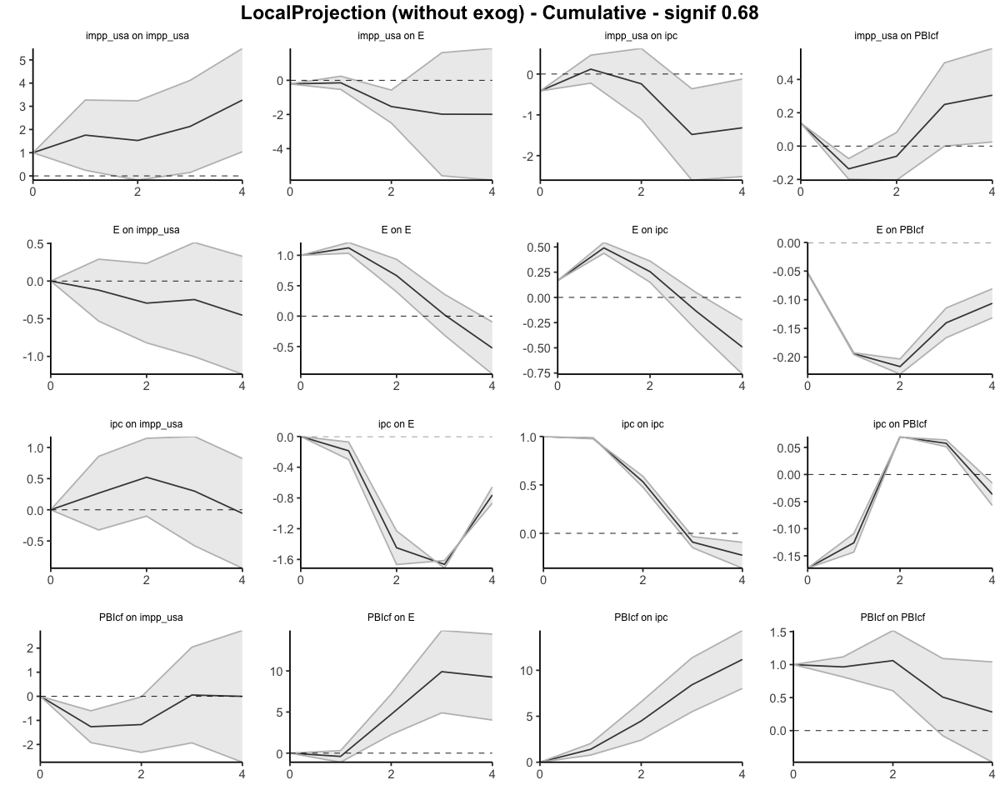

In [64]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("impp_usa", "E", "ipc", "PBIcf"), fixed_lags = 6, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

#### Todas endógenas - 6 lags

6 lags se descarta porque con 40 observaciones deja muy pocos grados de libertad: el 64% de las réplicas del bootstrap no pudo estimarse y las respuestas carecen de sentido económico. 

Bootstrap por bloques circular: 500 réplicas, bloques de 20 años...



  |======================================================================| 100%


212 réplicas fallaron y se descartaron.

Aviso (Lineal): en más del 5% de las réplicas la depreciación acumulada es casi cero en h = 3, 4; las bandas del ERPT acumulado en esos horizontes son poco confiables.



ERPT de un shock unitario en E sobre ipc ( LP, 6 rezagos )

Lineal
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.1668         0.1668       1.0000
         1              0.4910         0.4375       1.1222
         2              0.2554         0.3830       0.6667
         3             -0.1369        -6.0334       0.0227
         4             -0.4927         0.9370      -0.5258
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.1668             0.1668
                  0.3241             0.2707
                 -0.2356            -0.0545
                 -0.3923            -6.4165
                 -0.3558             6.9705


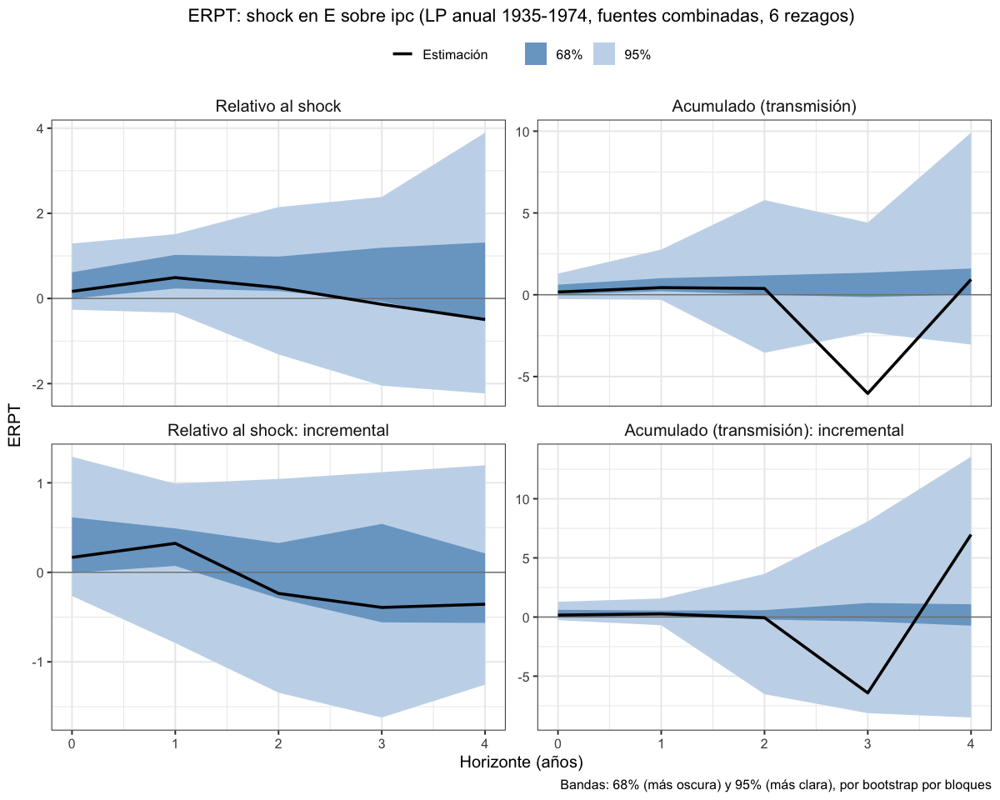

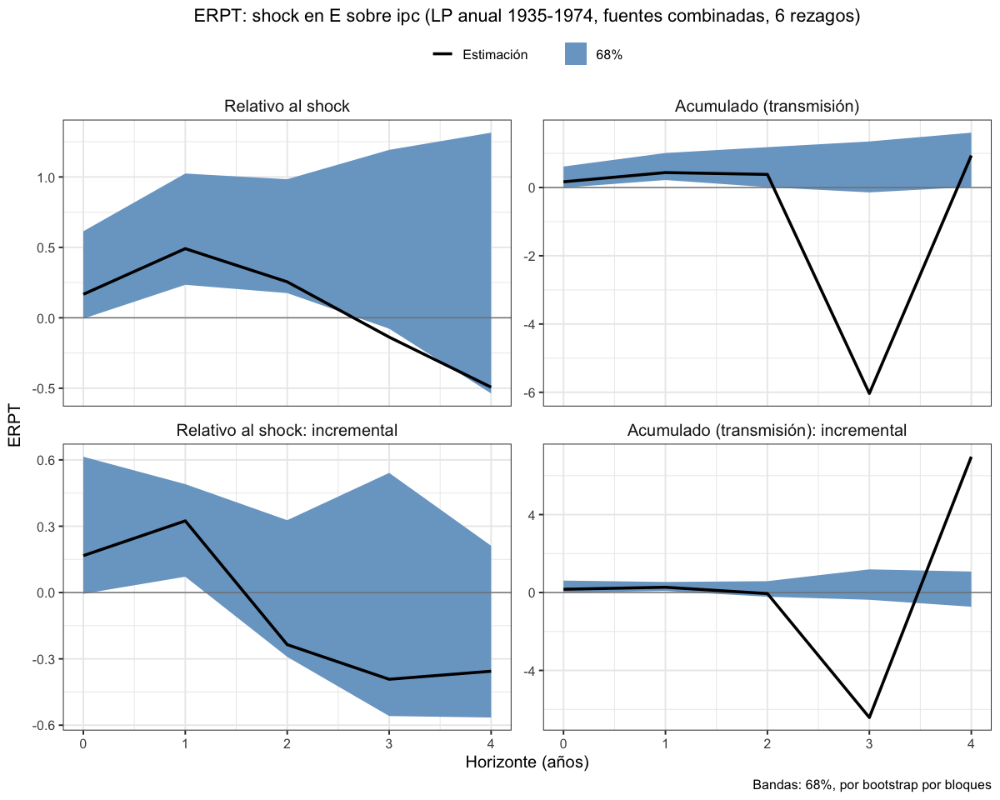

In [65]:
# Anual 1935–1974, fuentes combinadas. Todas endógenas, 6 rezagos
lp_erpt_anual_comb_35_74_endog_p6 <- erpt_lp(df_ERPT_Arg_1935_1974, endog = c("impp_usa", "E", "ipc", "PBIcf"),
                                             fixed_lags = 6, horizons = 4, reps = 500, unidad = "años")
saveRDS(lp_erpt_anual_comb_35_74_endog_p6, "lp_erpt_anual_comb_35_74_endog_p6.rds")
titulo_comb_35_74 <- "ERPT: shock en E sobre ipc (LP anual 1935-1974, fuentes combinadas, 6 rezagos)"
graficar_erpt_lp(lp_erpt_anual_comb_35_74_endog_p6, titulo = titulo_comb_35_74,
                 archivo = "lp_erpt_anual_comb_35_74_endog_p6")
graficar_erpt_lp(lp_erpt_anual_comb_35_74_endog_p6, titulo = titulo_comb_35_74, niveles = 0.68,
                 archivo = "lp_erpt_anual_comb_35_74_endog_p6_68")

### 1935-1974. 1 exógena y el resto endógenas - Selected orders: 0 y 1 lag (0 lag no tiene sentido en modelos autorregresivos)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.00000000
12,ipc,E,1,-0.15831330,-0.2249694,-0.09165722
13,ipc,E,2,-0.17217252,-0.2871975,-0.05714754
14,ipc,E,3,0.02221065,-0.1326686,0.17708986
15,ipc,E,4,0.59268890,0.4015128,0.78386496


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.000000,0.0000000,0.000000
22,PBIcf,E,1,2.075581,1.4200630,2.731099
23,PBIcf,E,2,2.413567,1.8145911,3.012544
24,PBIcf,E,3,1.792472,0.8533999,2.731545
25,PBIcf,E,4,-0.286740,-1.6307629,1.057283


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.2762750648,0.27627506,0.2762751
2,E,ipc,1,0.2854315826,0.21119723,0.3596659
3,E,ipc,2,0.1154858385,0.01234771,0.2186240
4,E,ipc,3,0.2389128523,-0.09114706,0.5689728
5,E,ipc,4,0.0005448144,-0.11728964,0.1183793


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.0000000,0.000000
27,PBIcf,ipc,1,2.026976,1.3784018,2.675551
28,PBIcf,ipc,2,2.047176,1.5650737,2.529279
29,PBIcf,ipc,3,1.308457,0.7554885,1.861426
30,PBIcf,ipc,4,1.401331,0.3680302,2.434633


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.063263992,-0.06326399,-0.063263992
7,E,PBIcf,1,-0.024515884,-0.04473560,-0.004296169
8,E,PBIcf,2,0.019264071,-0.02460280,0.063130945
9,E,PBIcf,3,-0.059052794,-0.11423986,-0.003865732
10,E,PBIcf,4,-0.007245643,-0.02480574,0.010314454


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.14542187,-0.14542187,-0.14542187
17,ipc,PBIcf,1,0.04058344,0.03716108,0.04400580
18,ipc,PBIcf,2,0.04396974,0.02674211,0.06119736
19,ipc,PBIcf,3,-0.00991050,-0.05146354,0.03164254
20,ipc,PBIcf,4,-0.05547559,-0.05641970,-0.05453147


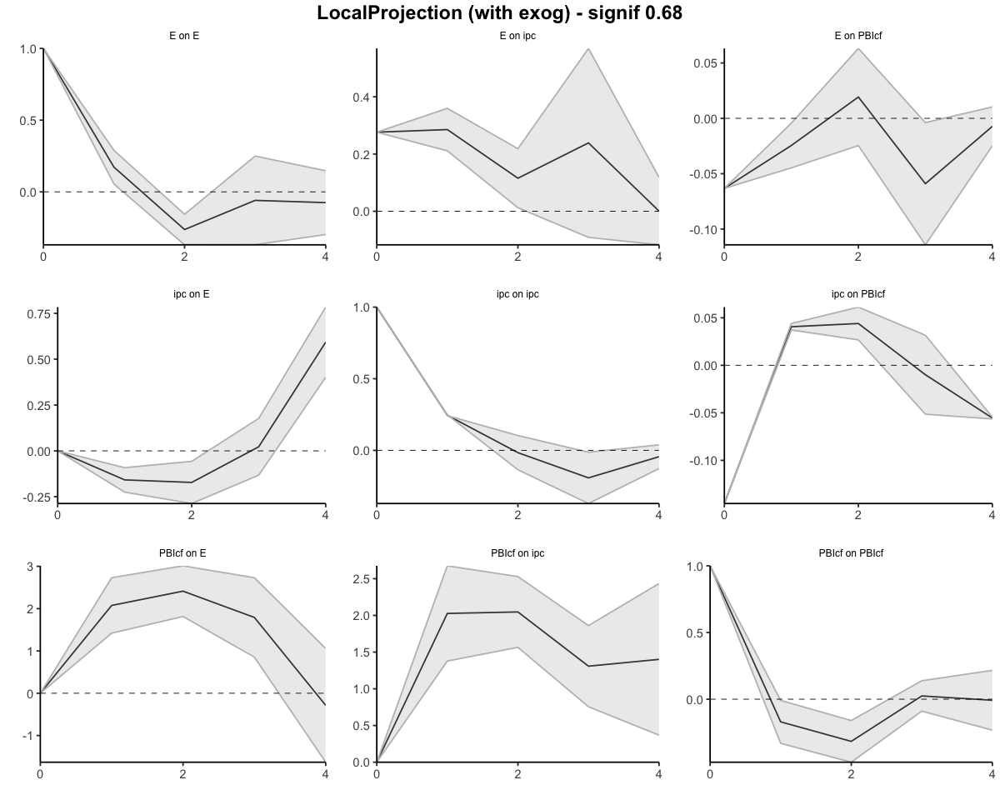

In [66]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("E", "ipc", "PBIcf"), exog=c("impp_usa"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.00000000
12,ipc,E,1,-0.1583133,-0.2249694,-0.09165722
13,ipc,E,2,-0.3304858,-0.5121669,-0.14880475
14,ipc,E,3,-0.3082752,-0.6448354,0.02828511
15,ipc,E,4,0.2844137,-0.2433226,0.81215007


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.000000,0.000000,0.000000
22,PBIcf,E,1,2.075581,1.420063,2.731099
23,PBIcf,E,2,4.489148,3.234654,5.743643
24,PBIcf,E,3,6.281621,4.088054,8.475188
25,PBIcf,E,4,5.994881,2.457291,9.532471


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.2762751,0.2762751,0.2762751
2,E,ipc,1,0.5617066,0.4874723,0.6359410
3,E,ipc,2,0.6771925,0.4998200,0.8545650
4,E,ipc,3,0.9161053,0.4086730,1.4235377
5,E,ipc,4,0.9166502,0.2913833,1.5419170


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.000000,0.000000
27,PBIcf,ipc,1,2.026976,1.378402,2.675551
28,PBIcf,ipc,2,4.074153,2.943476,5.204830
29,PBIcf,ipc,3,5.382610,3.698964,7.066256
30,PBIcf,ipc,4,6.783941,4.066994,9.500889


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.06326399,-0.06326399,-0.063263992
7,E,PBIcf,1,-0.08777988,-0.10799959,-0.067560162
8,E,PBIcf,2,-0.06851581,-0.13260239,-0.004429217
9,E,PBIcf,3,-0.12756860,-0.24684225,-0.008294950
10,E,PBIcf,4,-0.13481424,-0.27164799,0.002019505


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.14542187,-0.14542187,-0.14542187
17,ipc,PBIcf,1,-0.10483843,-0.10826079,-0.10141607
18,ipc,PBIcf,2,-0.06086869,-0.08151867,-0.04021871
19,ipc,PBIcf,3,-0.07077919,-0.13298221,-0.00857617
20,ipc,PBIcf,4,-0.12625478,-0.18940192,-0.06310764


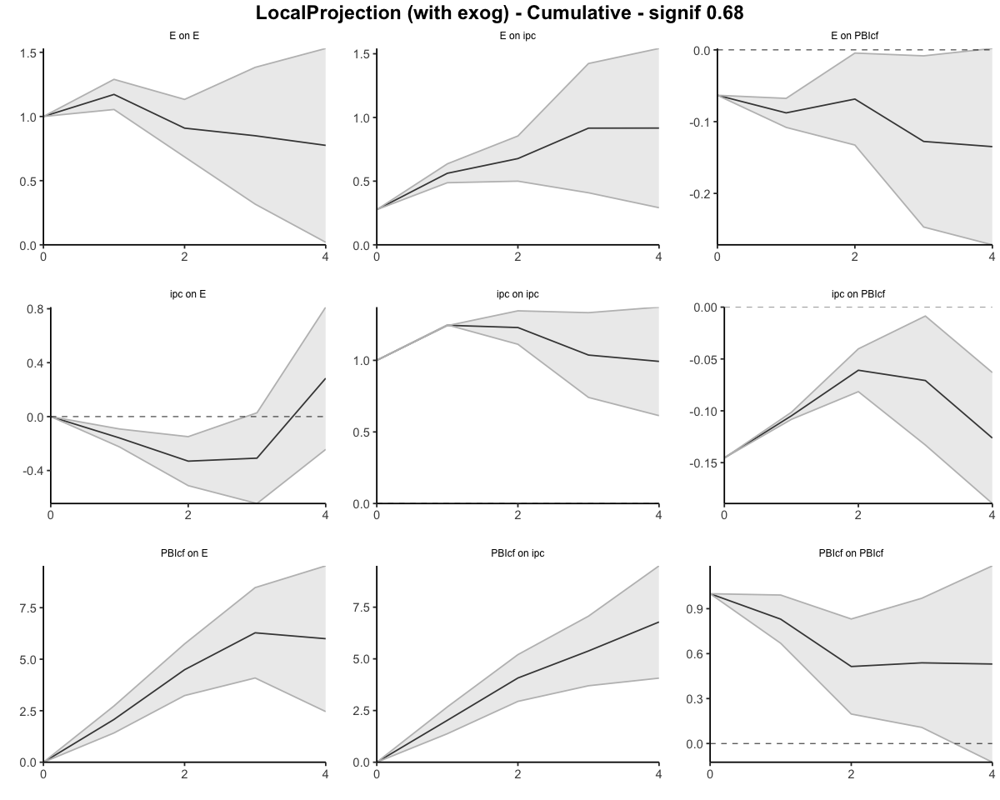

In [67]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("E", "ipc", "PBIcf"), exog=c("impp_usa"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

#### impp_usa exógena y el resto endógenas - 1 lag

Bootstrap por bloques circular: 500 réplicas, bloques de 10 años...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 1 rezagos, exógenas: impp_usa )

Lineal
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.2763         0.2763       1.0000
         1              0.5617         0.4793       1.1719
         2              0.6772         0.7448       0.9092
         3              0.9161         1.0778       0.8499
         4              0.9167         1.1828       0.7750
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.2763             0.2763
                  0.2854             0.2030
                  0.1155             0.2655
                  0.2389             0.3330
                  0.0005             0.1049


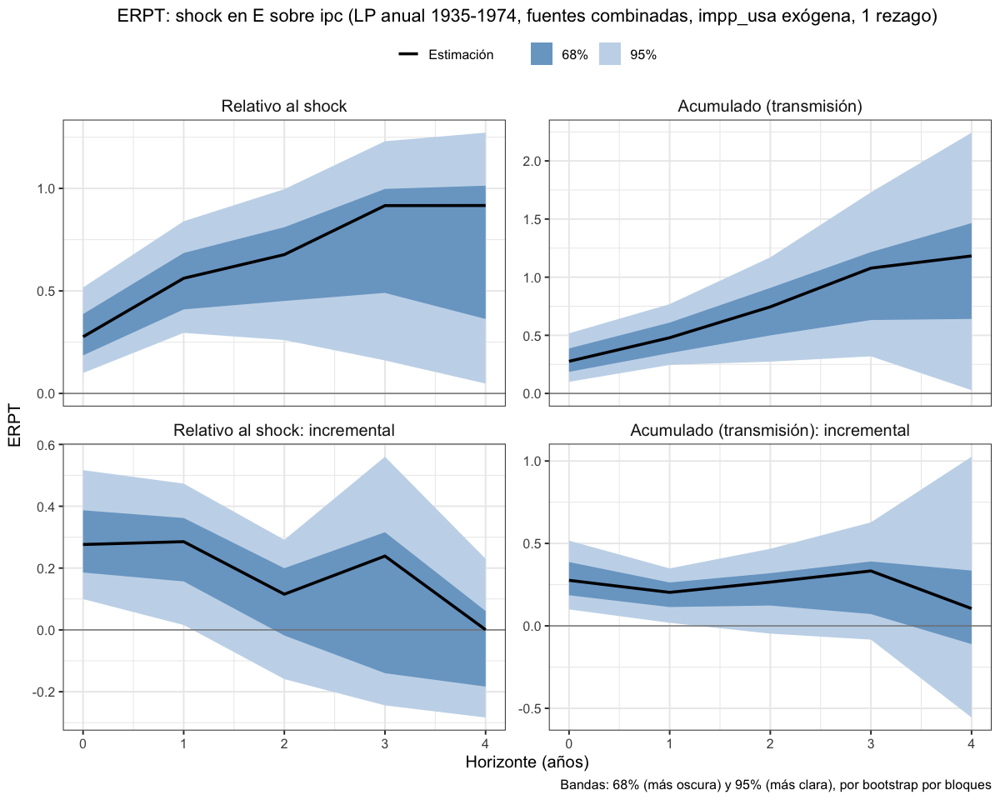

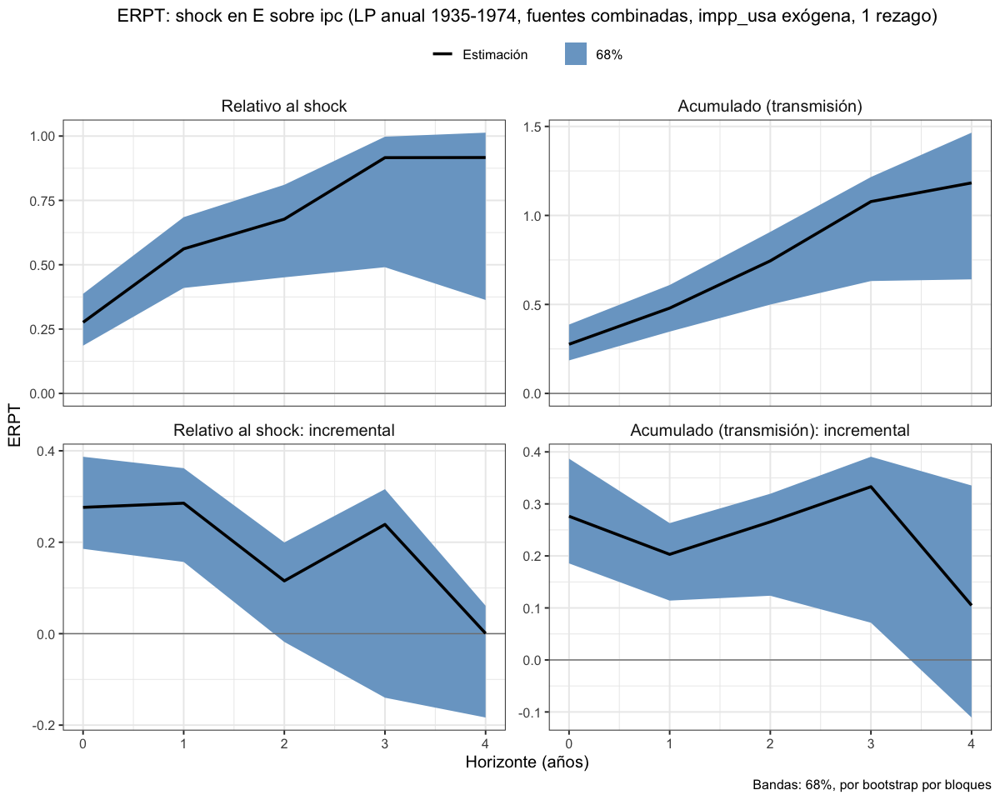

In [68]:
# Anual 1935–1974, fuentes combinadas. impp_usa exógena y el resto endógenas, 1 rezago
lp_erpt_anual_comb_35_74_exog_p1 <- erpt_lp(df_ERPT_Arg_1935_1974, endog = c("E", "ipc", "PBIcf"), exog = c("impp_usa"),
                                            fixed_lags = 1, horizons = 4, reps = 500, unidad = "años")
saveRDS(lp_erpt_anual_comb_35_74_exog_p1, "lp_erpt_anual_comb_35_74_exog_p1.rds")
titulo_comb_35_74_exog <- "ERPT: shock en E sobre ipc (LP anual 1935-1974, fuentes combinadas, impp_usa exógena, 1 rezago)"
graficar_erpt_lp(lp_erpt_anual_comb_35_74_exog_p1, titulo = titulo_comb_35_74_exog,
                 archivo = "lp_erpt_anual_comb_35_74_exog_p1")
graficar_erpt_lp(lp_erpt_anual_comb_35_74_exog_p1, titulo = titulo_comb_35_74_exog, niveles = 0.68,
                 archivo = "lp_erpt_anual_comb_35_74_exog_p1_68")

### 1935-1975. Todas endógenas - Selected orders: 0 lag (subo a 1 lag porque no tiene sentido 0 en modelos autorregresivos)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"impp_usa, E, ipc, PBIcf",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-0.74139316,-0.7413932,-0.7413932
2,impp_usa,E,1,0.84420389,0.2464174,1.4419904
3,impp_usa,E,2,0.67008423,0.3248062,1.0153622
4,impp_usa,E,3,-0.07957141,-0.8007135,0.6415707
5,impp_usa,E,4,-0.33232846,-0.5283034,-0.1363535


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.0000000
37,ipc,E,1,0.01239307,-0.1833032,0.2080894
38,ipc,E,2,0.56719952,0.2338193,0.9005797
39,ipc,E,3,0.32247322,0.1510483,0.4938981
40,ipc,E,4,0.69368581,0.3433913,1.0439803


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.00000000,0.000000
52,PBIcf,E,1,1.0534085,-0.09348469,2.200302
53,PBIcf,E,2,2.4451134,1.48854429,3.401683
54,PBIcf,E,3,2.3982739,1.53638602,3.260162
55,PBIcf,E,4,0.3730438,-1.24334187,1.989429


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
56,PBIcf,ipc,0,0.000000,0.0000000,0.000000
57,PBIcf,ipc,1,1.438936,0.5130505,2.364822
58,PBIcf,ipc,2,2.068543,1.2323223,2.904764
59,PBIcf,ipc,3,1.667210,1.0558688,2.278551
60,PBIcf,ipc,4,1.831351,0.4465634,3.216139


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,E,PBIcf,0,-0.03456694,-0.03456694,-0.034566936
27,E,PBIcf,1,-0.02665769,-0.05587043,0.002555053
28,E,PBIcf,2,0.01088496,-0.03726152,0.059031444
29,E,PBIcf,3,-0.05986810,-0.12480904,0.005072836
30,E,PBIcf,4,-0.02192737,-0.05321323,0.009358486


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,impp_usa,PBIcf,0,0.13183399,0.13183399,0.131833988
12,impp_usa,PBIcf,1,-0.03352771,-0.08660326,0.019547833
13,impp_usa,PBIcf,2,-0.06829880,-0.10782925,-0.028768359
14,impp_usa,PBIcf,3,-0.03168110,-0.07056929,0.007207085
15,impp_usa,PBIcf,4,0.09944029,0.01367510,0.185205484


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
41,ipc,PBIcf,0,-0.102516256,-0.10251626,-0.10251626
42,ipc,PBIcf,1,0.031243480,0.01965956,0.04282740
43,ipc,PBIcf,2,0.014407869,-0.00376934,0.03258508
44,ipc,PBIcf,3,-0.009145274,-0.05470171,0.03641116
45,ipc,PBIcf,4,-0.058334002,-0.06895094,-0.04771706


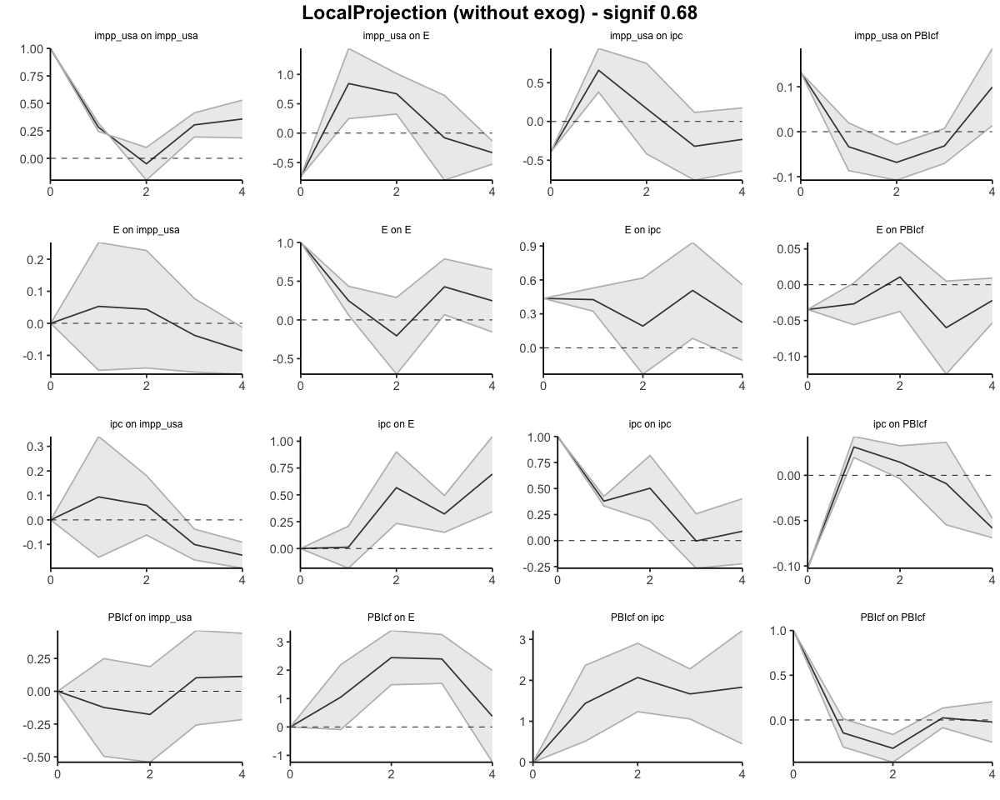

In [44]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("impp_usa", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"impp_usa, E, ipc, PBIcf",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-0.7413932,-0.7413932,-0.7413932
2,impp_usa,E,1,0.1028107,-0.4949757,0.7005972
3,impp_usa,E,2,0.7728950,-0.1701695,1.7159594
4,impp_usa,E,3,0.6933236,-0.9708830,2.3575301
5,impp_usa,E,4,0.3609951,-1.4991864,2.2211766


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.00000000,0.0000000
37,ipc,E,1,0.01239307,-0.18330322,0.2080894
38,ipc,E,2,0.57959259,0.05051607,1.1086691
39,ipc,E,3,0.90206581,0.20156440,1.6025672
40,ipc,E,4,1.59575162,0.54495572,2.6465475


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.000000,0.00000000,0.000000
52,PBIcf,E,1,1.053408,-0.09348469,2.200302
53,PBIcf,E,2,3.498522,1.39505960,5.601984
54,PBIcf,E,3,5.896796,2.93144561,8.862146
55,PBIcf,E,4,6.269840,1.68810375,10.851576


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
56,PBIcf,ipc,0,0.000000,0.0000000,0.000000
57,PBIcf,ipc,1,1.438936,0.5130505,2.364822
58,PBIcf,ipc,2,3.507479,1.7453728,5.269586
59,PBIcf,ipc,3,5.174689,2.8012416,7.548137
60,PBIcf,ipc,4,7.006040,3.2478050,10.764276


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,E,PBIcf,0,-0.03456694,-0.03456694,-0.03456694
27,E,PBIcf,1,-0.06122463,-0.09043737,-0.03201188
28,E,PBIcf,2,-0.05033966,-0.12769888,0.02701956
29,E,PBIcf,3,-0.11020776,-0.25250793,0.03209240
30,E,PBIcf,4,-0.13213513,-0.30572115,0.04145088


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,impp_usa,PBIcf,0,0.13183399,0.13183399,0.1318340
12,impp_usa,PBIcf,1,0.09830627,0.04523073,0.1513818
13,impp_usa,PBIcf,2,0.03000747,-0.06259852,0.1226135
14,impp_usa,PBIcf,3,-0.00167363,-0.13316781,0.1298205
15,impp_usa,PBIcf,4,0.09776666,-0.11949270,0.3150260


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
41,ipc,PBIcf,0,-0.10251626,-0.10251626,-0.102516256
42,ipc,PBIcf,1,-0.07127278,-0.08285670,-0.059688852
43,ipc,PBIcf,2,-0.05686491,-0.08662604,-0.027103774
44,ipc,PBIcf,3,-0.06601018,-0.14132775,0.009307387
45,ipc,PBIcf,4,-0.12434418,-0.21027869,-0.038409676


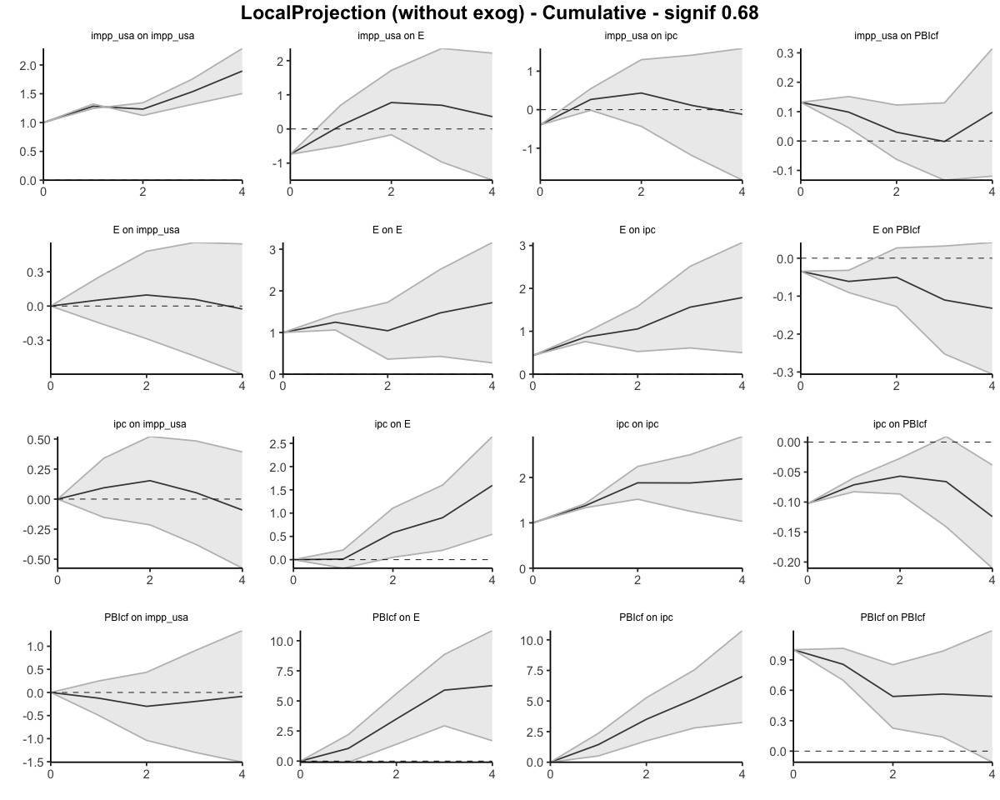

In [45]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("impp_usa", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

#### Todas endógenas - 1 lag

Bootstrap por bloques circular: 500 réplicas, bloques de 10 años...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 1 rezagos )

Lineal
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4368         0.4368       1.0000
         1              0.8629         0.6917       1.2474
         2              1.0550         1.0122       1.0423
         3              1.5623         1.0627       1.4701
         4              1.7860         1.0403       1.7168
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4368             0.4368
                  0.4261             0.2550
                  0.1921             0.3204
                  0.5073             0.0505
                  0.2237            -0.0224


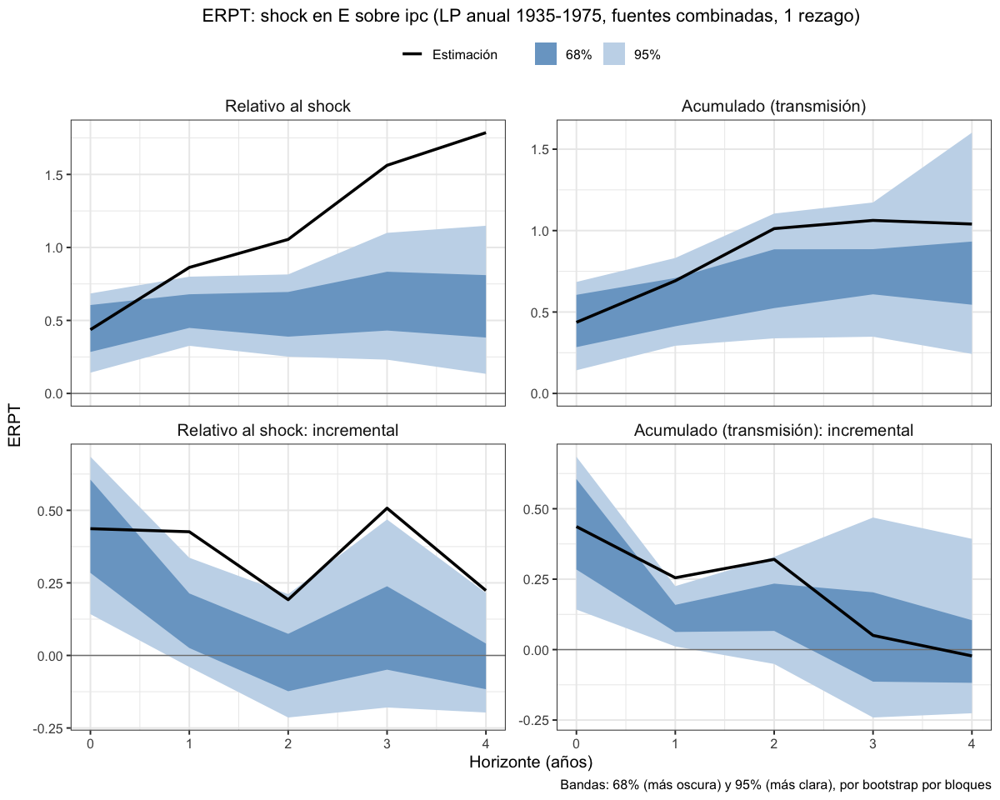

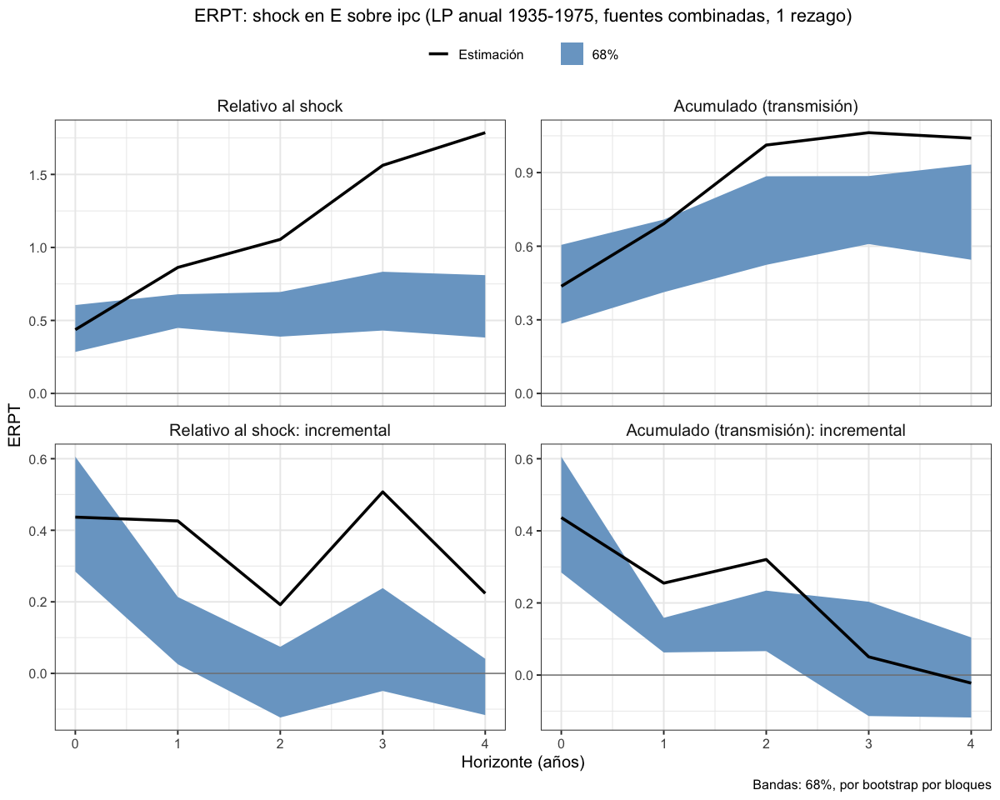

In [50]:
# Anual 1935–1975, fuentes combinadas. Todas endógenas, 1 rezago
lp_erpt_anual_comb_35_75_endog_p1 <- erpt_lp(df_ERPT_Arg_1935_1975, endog = c("impp_usa", "E", "ipc", "PBIcf"),
                                             fixed_lags = 1, horizons = 4, reps = 500, unidad = "años")
saveRDS(lp_erpt_anual_comb_35_75_endog_p1, "lp_erpt_anual_comb_35_75_endog_p1.rds")
titulo_comb_35_75 <- "ERPT: shock en E sobre ipc (LP anual 1935-1975, fuentes combinadas, 1 rezago)"
graficar_erpt_lp(lp_erpt_anual_comb_35_75_endog_p1, titulo = titulo_comb_35_75,
                 archivo = "lp_erpt_anual_comb_35_75_endog_p1")
graficar_erpt_lp(lp_erpt_anual_comb_35_75_endog_p1, titulo = titulo_comb_35_75, niveles = 0.68,
                 archivo = "lp_erpt_anual_comb_35_75_endog_p1_68")

### 1935-1975. 1 exógena y el resto endógenas - Selected orders: 0 lag (no tiene sentido para modelos autorregresivos, así que subo 1 lag)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.000000000,0.0000000,0.0000000
12,ipc,E,1,0.008045222,-0.1829174,0.1990078
13,ipc,E,2,0.557107538,0.2276755,0.8865396
14,ipc,E,3,0.312574570,0.1447070,0.4804421
15,ipc,E,4,0.692146108,0.3485231,1.0357691


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.00000000,0.000000
22,PBIcf,E,1,1.0534085,-0.09348469,2.200302
23,PBIcf,E,2,2.4451134,1.48854429,3.401683
24,PBIcf,E,3,2.3982739,1.53638602,3.260162
25,PBIcf,E,4,0.3730438,-1.24334187,1.989429


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4418323,0.44183229,0.4418323
2,E,ipc,1,0.4178438,0.32154605,0.5141415
3,E,ipc,2,0.1800318,-0.24044503,0.6005087
4,E,ipc,3,0.4954446,0.07468466,0.9162046
5,E,ipc,4,0.2111805,-0.11426631,0.5366273


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.0000000,0.000000
27,PBIcf,ipc,1,1.438936,0.5130505,2.364822
28,PBIcf,ipc,2,2.068543,1.2323223,2.904764
29,PBIcf,ipc,3,1.667210,1.0558688,2.278551
30,PBIcf,ipc,4,1.831351,0.4465634,3.216139


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.04217399,-0.04217399,-0.042173985
7,E,PBIcf,1,-0.02547827,-0.05363160,0.002675062
8,E,PBIcf,2,0.01320408,-0.03393510,0.060343259
9,E,PBIcf,3,-0.06008268,-0.12447367,0.004308309
10,E,PBIcf,4,-0.02206351,-0.05179928,0.007672272


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.106643663,-0.106643663,-0.10664366
17,ipc,PBIcf,1,0.031838021,0.020905380,0.04277066
18,ipc,PBIcf,2,0.015715979,-0.001820803,0.03325276
19,ipc,PBIcf,3,-0.009243206,-0.054344628,0.03585822
20,ipc,PBIcf,4,-0.058240801,-0.067923542,-0.04855806


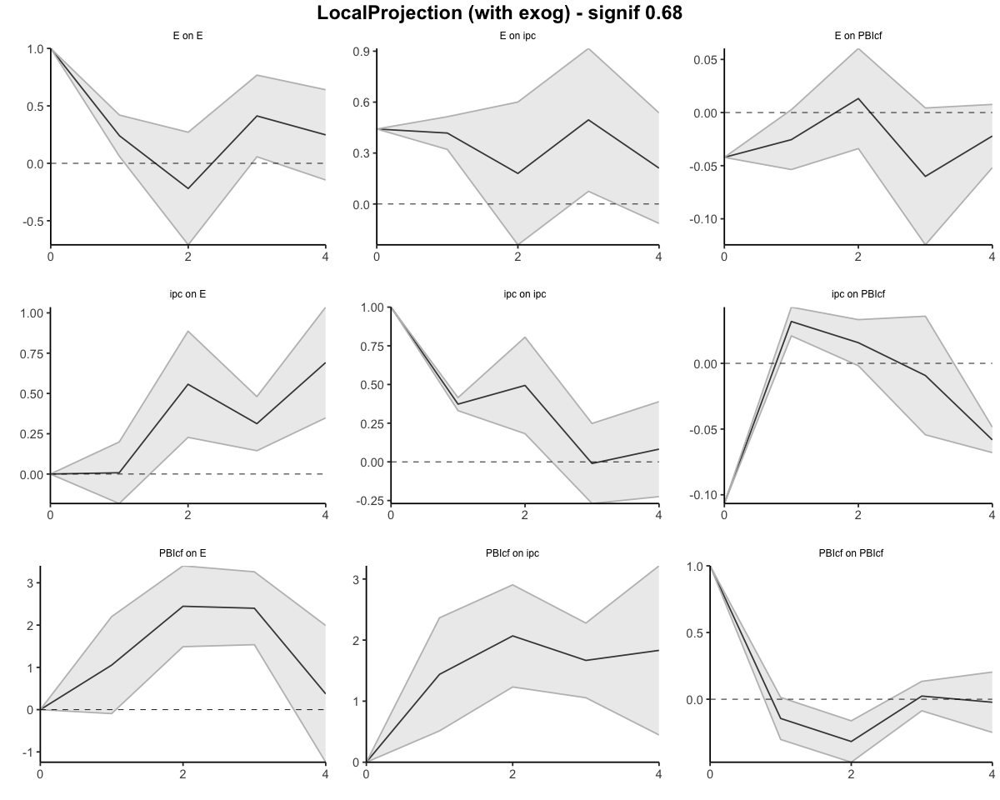

In [69]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("E", "ipc", "PBIcf"), exog=c("impp_usa"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.000000000,0.00000000,0.0000000
12,ipc,E,1,0.008045222,-0.18291737,0.1990078
13,ipc,E,2,0.565152760,0.04475809,1.0855474
14,ipc,E,3,0.877727330,0.18946513,1.5659895
15,ipc,E,4,1.569873437,0.53798823,2.6017586


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.000000,0.00000000,0.000000
22,PBIcf,E,1,1.053408,-0.09348469,2.200302
23,PBIcf,E,2,3.498522,1.39505960,5.601984
24,PBIcf,E,3,5.896796,2.93144561,8.862146
25,PBIcf,E,4,6.269840,1.68810375,10.851576


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4418323,0.4418323,0.4418323
2,E,ipc,1,0.8596761,0.7633783,0.9559738
3,E,ipc,2,1.0397079,0.5229333,1.5564825
4,E,ipc,3,1.5351525,0.5976180,2.4726871
5,E,ipc,4,1.7463330,0.4833517,3.0093144


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.0000000,0.000000
27,PBIcf,ipc,1,1.438936,0.5130505,2.364822
28,PBIcf,ipc,2,3.507479,1.7453728,5.269586
29,PBIcf,ipc,3,5.174689,2.8012416,7.548137
30,PBIcf,ipc,4,7.006040,3.2478050,10.764276


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.04217399,-0.04217399,-0.04217399
7,E,PBIcf,1,-0.06765225,-0.09580558,-0.03949892
8,E,PBIcf,2,-0.05444817,-0.12974068,0.02084434
9,E,PBIcf,3,-0.11453085,-0.25421435,0.02515265
10,E,PBIcf,4,-0.13659436,-0.30601363,0.03282492


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.10664366,-0.10664366,-0.106643663
17,ipc,PBIcf,1,-0.07480564,-0.08573828,-0.063873000
18,ipc,PBIcf,2,-0.05908966,-0.08755909,-0.030620239
19,ipc,PBIcf,3,-0.06833287,-0.14190371,0.005237976
20,ipc,PBIcf,4,-0.12657367,-0.20982726,-0.043320084


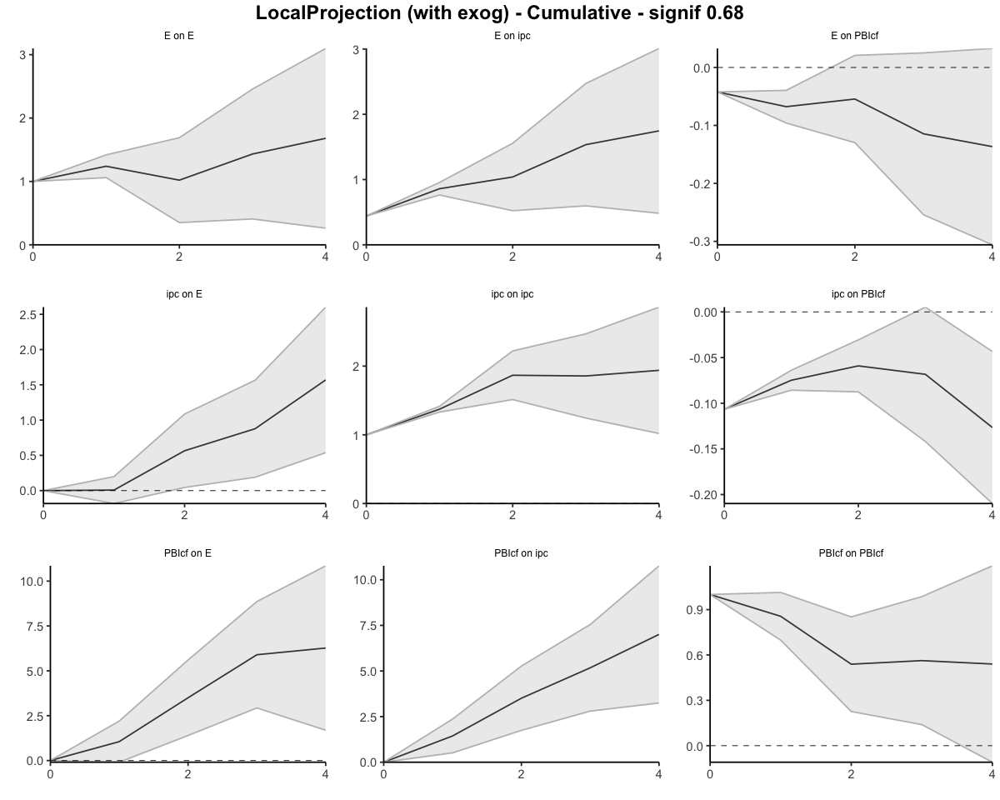

In [70]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("E", "ipc", "PBIcf"), exog=c("impp_usa"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

#### impp_usa exógena y el resto endógenas - 1 lag

Bootstrap por bloques circular: 500 réplicas, bloques de 10 años...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 1 rezagos, exógenas: impp_usa )

Lineal
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4418         0.4418       1.0000
         1              0.8597         0.6933       1.2400
         2              1.0397         1.0189       1.0204
         3              1.5352         1.0714       1.4329
         4              1.7463         1.0392       1.6804
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4418             0.4418
                  0.4178             0.2515
                  0.1800             0.3256
                  0.4954             0.0525
                  0.2112            -0.0321


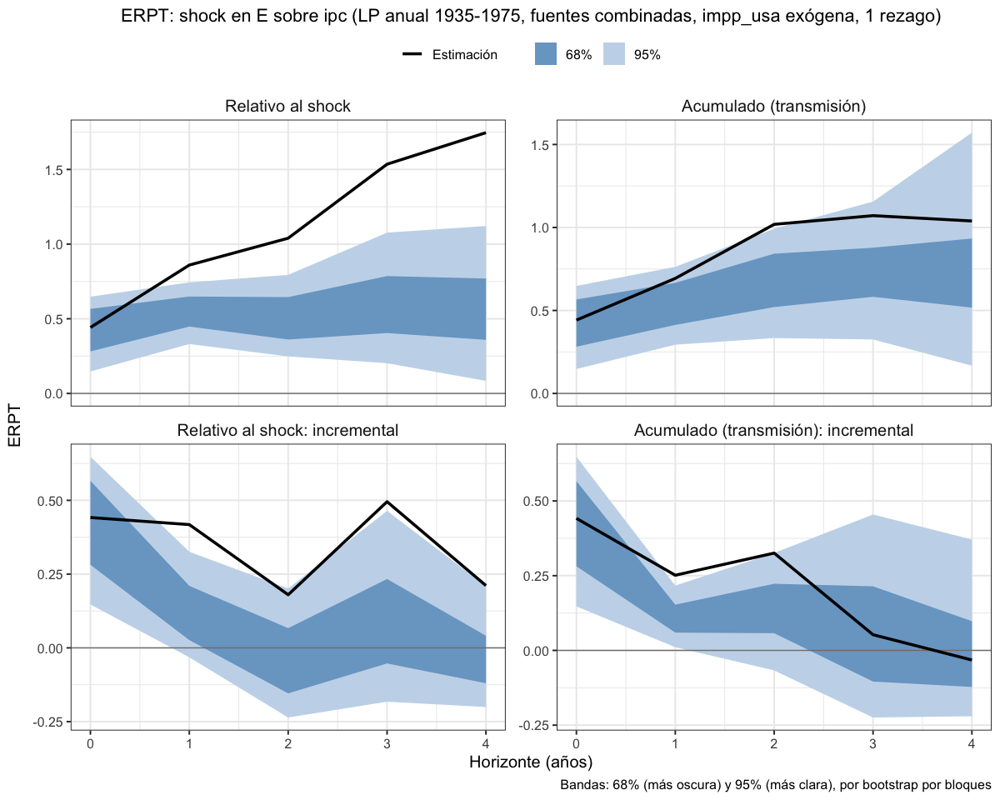

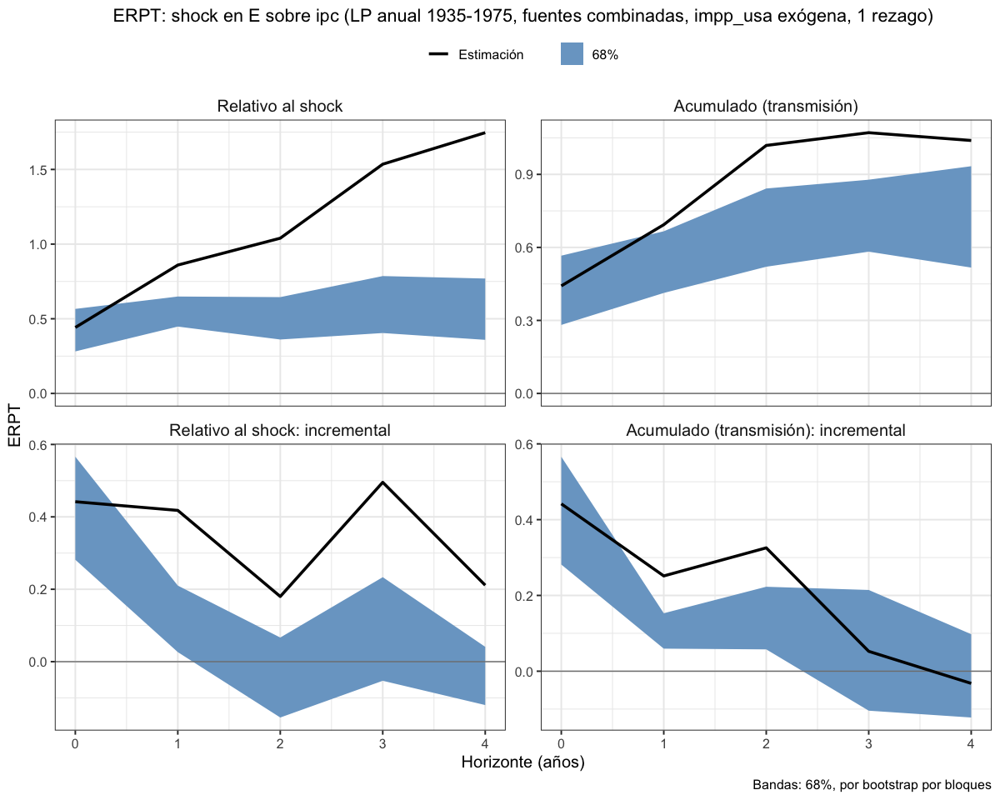

In [71]:
# Anual 1935–1975, fuentes combinadas. impp_usa exógena y el resto endógenas, 1 rezago
lp_erpt_anual_comb_35_75_exog_p1 <- erpt_lp(df_ERPT_Arg_1935_1975, endog = c("E", "ipc", "PBIcf"), exog = c("impp_usa"),
                                            fixed_lags = 1, horizons = 4, reps = 500, unidad = "años")
saveRDS(lp_erpt_anual_comb_35_75_exog_p1, "lp_erpt_anual_comb_35_75_exog_p1.rds")
titulo_comb_35_75_exog <- "ERPT: shock en E sobre ipc (LP anual 1935-1975, fuentes combinadas, impp_usa exógena, 1 rezago)"
graficar_erpt_lp(lp_erpt_anual_comb_35_75_exog_p1, titulo = titulo_comb_35_75_exog,
                 archivo = "lp_erpt_anual_comb_35_75_exog_p1")
graficar_erpt_lp(lp_erpt_anual_comb_35_75_exog_p1, titulo = titulo_comb_35_75_exog, niveles = 0.68,
                 archivo = "lp_erpt_anual_comb_35_75_exog_p1_68")

### 1935-1982. Todas endógenas - Selected orders: 1 lag

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"impp_usa, E, ipc, PBIcf",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-1.3070370,-1.3070370,-1.3070369525
2,impp_usa,E,1,0.8130602,-0.3079714,1.9340917850
3,impp_usa,E,2,2.6998412,1.8324807,3.5672017443
4,impp_usa,E,3,1.1816884,0.8623876,1.5009891902
5,impp_usa,E,4,0.4888265,0.9781549,-0.0005017537


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.0000000
37,ipc,E,1,-0.04668986,-0.2547952,0.1614155
38,ipc,E,2,0.70200985,0.5235616,0.8804581
39,ipc,E,3,0.85983248,0.5786668,1.1409981
40,ipc,E,4,0.88968536,0.4225348,1.3568359


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.0000000,0.0000000
52,PBIcf,E,1,-0.4103721,-2.3648135,1.5440693
53,PBIcf,E,2,1.5791669,0.3959598,2.7623741
54,PBIcf,E,3,0.7428472,-0.5768177,2.0625121
55,PBIcf,E,4,-0.9728362,-2.3315152,0.3858427


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
56,PBIcf,ipc,0,0.0000000,0.00000000,0.000000
57,PBIcf,ipc,1,0.7937237,-0.07193596,1.659383
58,PBIcf,ipc,2,1.0114507,0.02112728,2.001774
59,PBIcf,ipc,3,0.7091983,-0.21715962,1.635556
60,PBIcf,ipc,4,0.6246288,-0.43803684,1.687294


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,E,PBIcf,0,-0.0406727299,-0.04067273,-0.040672730
27,E,PBIcf,1,-0.0185888168,-0.03316086,-0.004016777
28,E,PBIcf,2,0.0007923497,-0.04084040,0.042425103
29,E,PBIcf,3,-0.0269965471,-0.07855327,0.024560180
30,E,PBIcf,4,0.0050825490,-0.02136800,0.031533098


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,impp_usa,PBIcf,0,0.15423855,0.15423855,0.15423855
12,impp_usa,PBIcf,1,-0.07167194,-0.13207371,-0.01127017
13,impp_usa,PBIcf,2,-0.10989247,-0.11478786,-0.10499708
14,impp_usa,PBIcf,3,-0.02191861,-0.01913371,-0.02470350
15,impp_usa,PBIcf,4,-0.02148037,-0.07075508,0.02779434


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
41,ipc,PBIcf,0,-0.049427516,-0.049427516,-0.04942752
42,ipc,PBIcf,1,0.007874282,0.003600521,0.01214804
43,ipc,PBIcf,2,-0.026032524,-0.054857129,0.00279208
44,ipc,PBIcf,3,-0.020503434,-0.056393681,0.01538681
45,ipc,PBIcf,4,-0.068312896,-0.080685138,-0.05594065


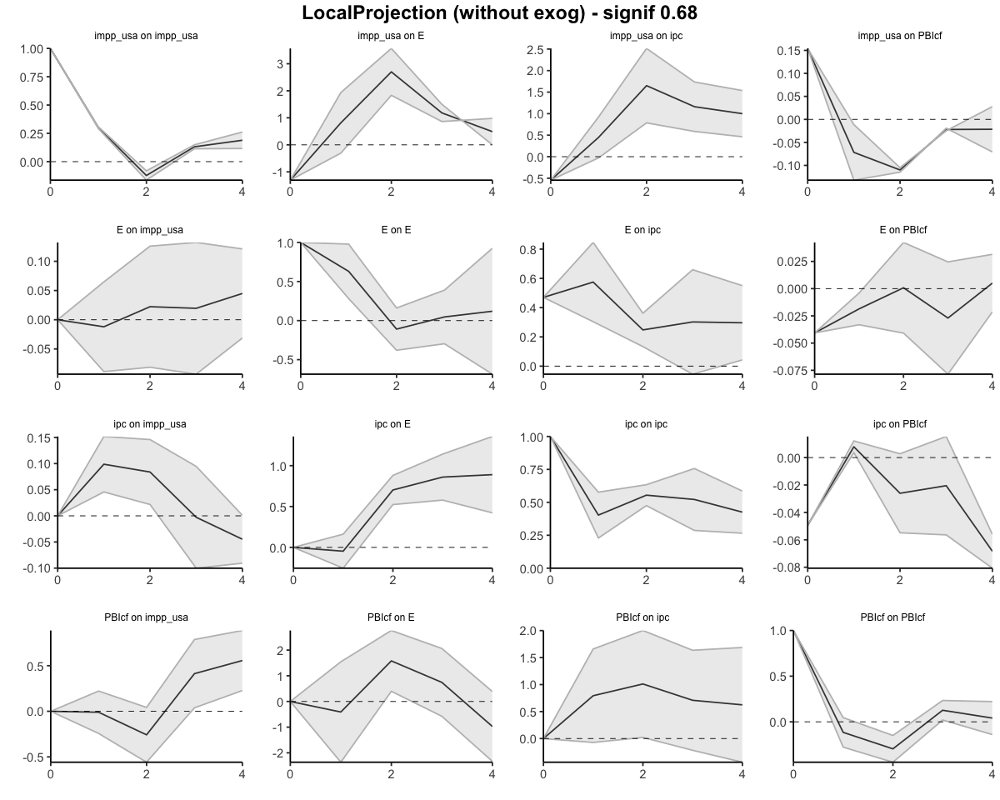

In [72]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("impp_usa", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"impp_usa, E, ipc, PBIcf",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-1.3070370,-1.3070370,-1.3070370
2,impp_usa,E,1,-0.4939768,-1.6150083,0.6270548
3,impp_usa,E,2,2.2058645,0.2174724,4.1942566
4,impp_usa,E,3,3.3875529,1.0798600,5.6952458
5,impp_usa,E,4,3.8763794,2.0580148,5.6947440


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.0000000
37,ipc,E,1,-0.04668986,-0.2547952,0.1614155
38,ipc,E,2,0.65531998,0.2687663,1.0418736
39,ipc,E,3,1.51515246,0.8474332,2.1828717
40,ipc,E,4,2.40483782,1.2699680,3.5397076


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.000000,0.000000
52,PBIcf,E,1,-0.4103721,-2.364813,1.544069
53,PBIcf,E,2,1.1687948,-1.968854,4.306443
54,PBIcf,E,3,1.9116420,-2.545671,6.368955
55,PBIcf,E,4,0.9388058,-4.877187,6.754798


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
56,PBIcf,ipc,0,0.0000000,0.00000000,0.000000
57,PBIcf,ipc,1,0.7937237,-0.07193596,1.659383
58,PBIcf,ipc,2,1.8051744,-0.05080868,3.661157
59,PBIcf,ipc,3,2.5143726,-0.26796830,5.296714
60,PBIcf,ipc,4,3.1390014,-0.70600514,6.984008


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,E,PBIcf,0,-0.04067273,-0.04067273,-0.040672730
27,E,PBIcf,1,-0.05926155,-0.07383359,-0.044689507
28,E,PBIcf,2,-0.05846920,-0.11467399,-0.002264404
29,E,PBIcf,3,-0.08546574,-0.19322726,0.022295777
30,E,PBIcf,4,-0.08038320,-0.21459526,0.053828874


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,impp_usa,PBIcf,0,0.15423855,0.15423855,0.15423855
12,impp_usa,PBIcf,1,0.08256661,0.02216485,0.14296838
13,impp_usa,PBIcf,2,-0.02732585,-0.09262301,0.03797130
14,impp_usa,PBIcf,3,-0.04924446,-0.11175672,0.01326780
15,impp_usa,PBIcf,4,-0.07072483,-0.18251179,0.04106214


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
41,ipc,PBIcf,0,-0.04942752,-0.04942752,-0.04942752
42,ipc,PBIcf,1,-0.04155323,-0.04582700,-0.03727947
43,ipc,PBIcf,2,-0.06758576,-0.10068412,-0.03448739
44,ipc,PBIcf,3,-0.08808919,-0.15707781,-0.01910058
45,ipc,PBIcf,4,-0.15640209,-0.23776294,-0.07504124


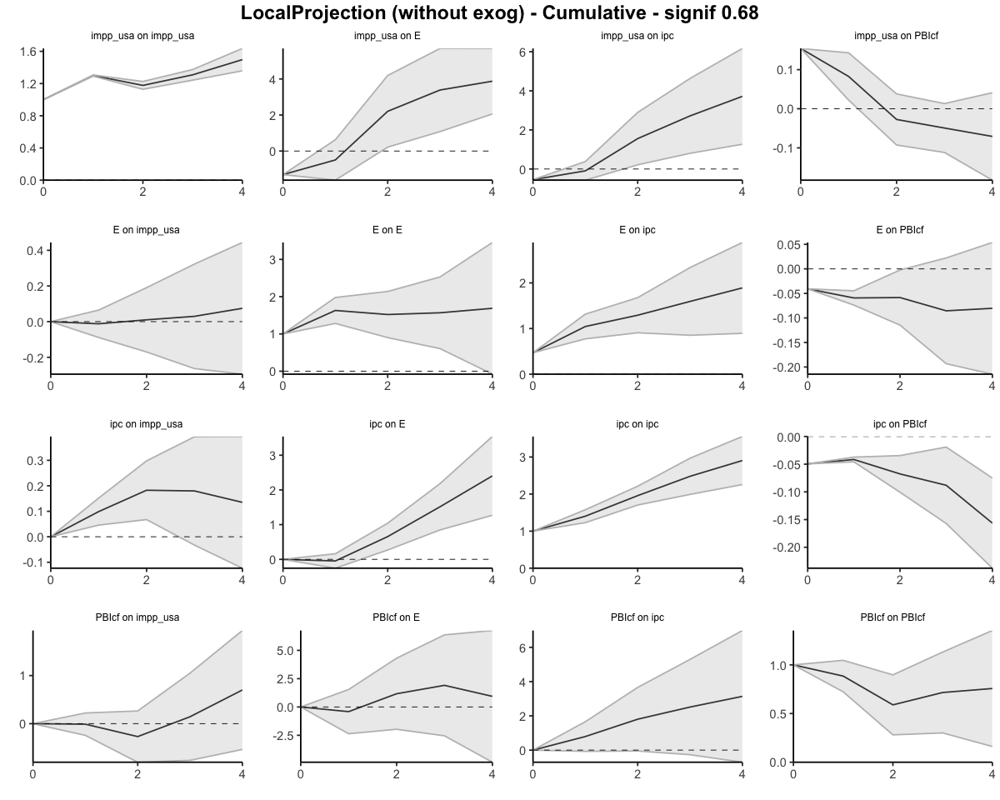

In [73]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("impp_usa", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

#### Todas endógenas - 1 lag

Bootstrap por bloques circular: 500 réplicas, bloques de 10 años...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 1 rezagos )

Lineal
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4700         0.4700       1.0000
         1              1.0446         0.6408       1.6303
         2              1.2923         0.8496       1.5211
         3              1.5944         1.0169       1.5679
         4              1.8909         1.1204       1.6877
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4700             0.4700
                  0.5746             0.1707
                  0.2476             0.2088
                  0.3021             0.1674
                  0.2964             0.1034


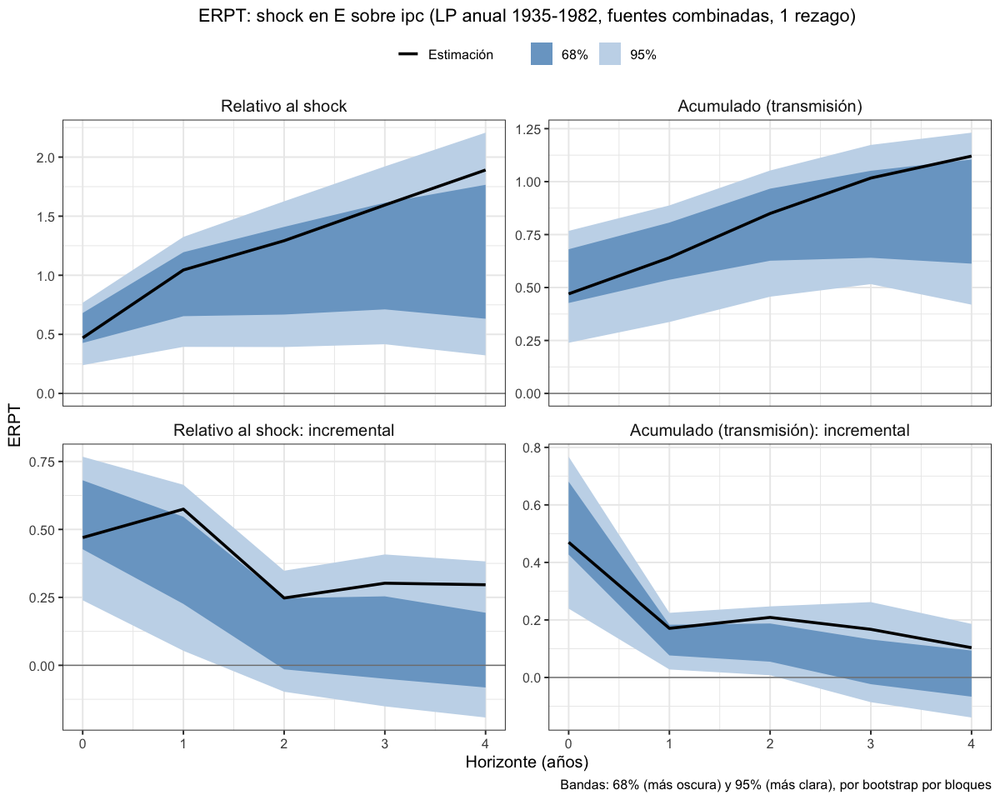

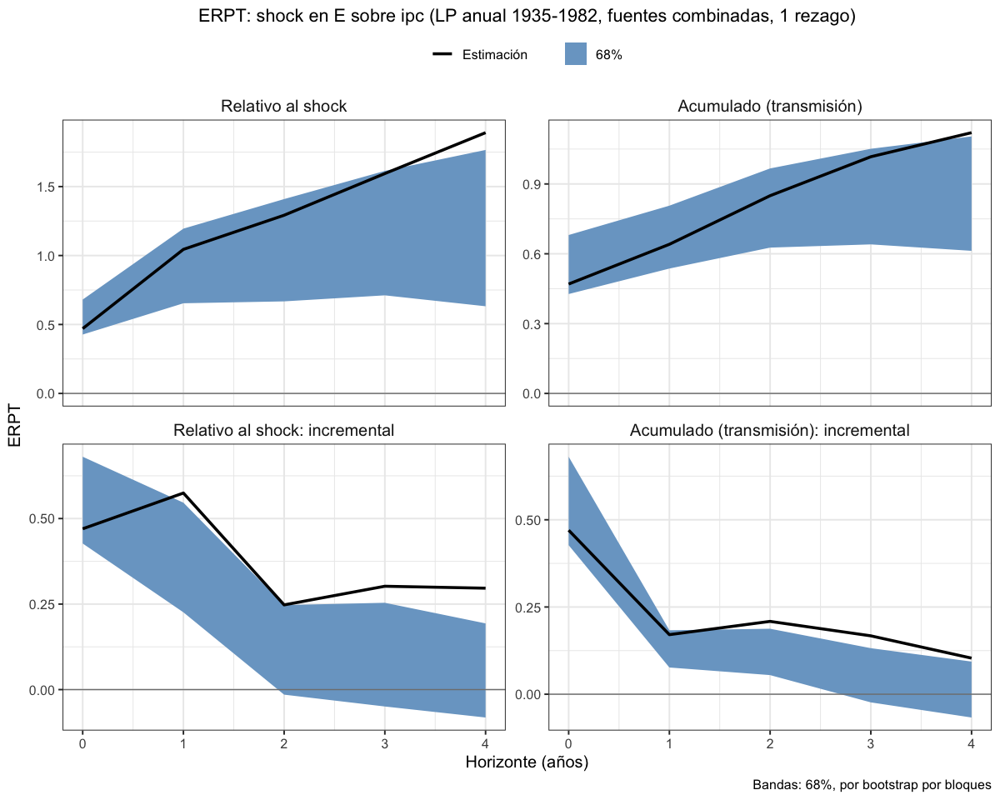

In [74]:
# Anual 1935–1982, fuentes combinadas. Todas endógenas, 1 rezago
lp_erpt_anual_comb_35_82_endog_p1 <- erpt_lp(df_ERPT_Arg_1935_1982, endog = c("impp_usa", "E", "ipc", "PBIcf"),
                                             fixed_lags = 1, horizons = 4, reps = 500, unidad = "años")
saveRDS(lp_erpt_anual_comb_35_82_endog_p1, "lp_erpt_anual_comb_35_82_endog_p1.rds")
titulo_comb_35_82 <- "ERPT: shock en E sobre ipc (LP anual 1935-1982, fuentes combinadas, 1 rezago)"
graficar_erpt_lp(lp_erpt_anual_comb_35_82_endog_p1, titulo = titulo_comb_35_82,
                 archivo = "lp_erpt_anual_comb_35_82_endog_p1")
graficar_erpt_lp(lp_erpt_anual_comb_35_82_endog_p1, titulo = titulo_comb_35_82, niveles = 0.68,
                 archivo = "lp_erpt_anual_comb_35_82_endog_p1_68")

### 1943-1982. 1 exógena y el resto endógenas - Selected orders: 1 y 2 lags

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.0000000
12,ipc,E,1,-0.04792176,-0.2618942,0.1660507
13,ipc,E,2,0.70675035,0.5247502,0.8887505
14,ipc,E,3,0.86206243,0.5769353,1.1471896
15,ipc,E,4,0.88676500,0.4155359,1.3579942


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.0000000,0.0000000
22,PBIcf,E,1,-0.4103721,-2.3648135,1.5440693
23,PBIcf,E,2,1.5791669,0.3959598,2.7623741
24,PBIcf,E,3,0.7428472,-0.5768177,2.0625121
25,PBIcf,E,4,-0.9728362,-2.3315152,0.3858427


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4645089,0.46450887,0.4645089
2,E,ipc,1,0.5657858,0.30307713,0.8284945
3,E,ipc,2,0.2361895,0.13085160,0.3415274
4,E,ipc,3,0.2933723,-0.05469934,0.6414440
5,E,ipc,4,0.2888954,0.04474547,0.5330454


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.0000000,0.00000000,0.000000
27,PBIcf,ipc,1,0.7937237,-0.07193596,1.659383
28,PBIcf,ipc,2,1.0114507,0.02112728,2.001774
29,PBIcf,ipc,3,0.7091983,-0.21715962,1.635556
30,PBIcf,ipc,4,0.6246288,-0.43803684,1.687294


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.048696807,-0.04869681,-0.048696807
7,E,PBIcf,1,-0.017676184,-0.03088251,-0.004469863
8,E,PBIcf,2,0.003389821,-0.03686884,0.043648479
9,E,PBIcf,3,-0.027935930,-0.07840639,0.022534528
10,E,PBIcf,4,0.005119123,-0.01976410,0.030002345


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.046425617,-0.046425617,-0.046425617
17,ipc,PBIcf,1,0.007528347,0.002769048,0.012287645
18,ipc,PBIcf,2,-0.026920134,-0.056184164,0.002343897
19,ipc,PBIcf,3,-0.020122542,-0.056333943,0.016088858
20,ipc,PBIcf,4,-0.068189390,-0.081103897,-0.055274883


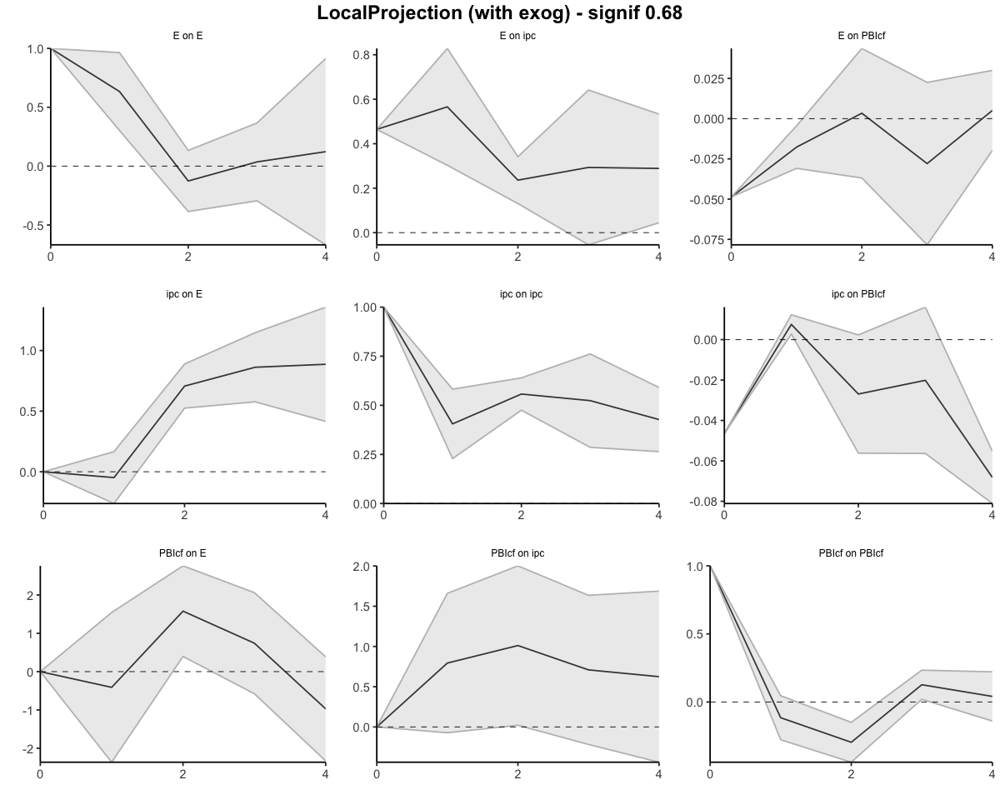

In [75]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("E", "ipc", "PBIcf"), exog=c("impp_usa"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.0000000
12,ipc,E,1,-0.04792176,-0.2618942,0.1660507
13,ipc,E,2,0.65882859,0.2628560,1.0548011
14,ipc,E,3,1.52089102,0.8397913,2.2019907
15,ipc,E,4,2.40765602,1.2553272,3.5599849


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.000000,0.000000
22,PBIcf,E,1,-0.4103721,-2.364813,1.544069
23,PBIcf,E,2,1.1687948,-1.968854,4.306443
24,PBIcf,E,3,1.9116420,-2.545671,6.368955
25,PBIcf,E,4,0.9388058,-4.877187,6.754798


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4645089,0.4645089,0.4645089
2,E,ipc,1,1.0302947,0.7675860,1.2930034
3,E,ipc,2,1.2664842,0.8984376,1.6345308
4,E,ipc,3,1.5598565,0.8437383,2.2759747
5,E,ipc,4,1.8487519,0.8884837,2.8090201


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.0000000,0.00000000,0.000000
27,PBIcf,ipc,1,0.7937237,-0.07193596,1.659383
28,PBIcf,ipc,2,1.8051744,-0.05080868,3.661157
29,PBIcf,ipc,3,2.5143726,-0.26796830,5.296714
30,PBIcf,ipc,4,3.1390014,-0.70600514,6.984008


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.04869681,-0.04869681,-0.048696807
7,E,PBIcf,1,-0.06637299,-0.07957931,-0.053166671
8,E,PBIcf,2,-0.06298317,-0.11644815,-0.009518192
9,E,PBIcf,3,-0.09091910,-0.19485454,0.013016336
10,E,PBIcf,4,-0.08579998,-0.21461864,0.043018681


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.04642562,-0.04642562,-0.04642562
17,ipc,PBIcf,1,-0.03889727,-0.04365657,-0.03413797
18,ipc,PBIcf,2,-0.06581740,-0.09984073,-0.03179408
19,ipc,PBIcf,3,-0.08593995,-0.15617468,-0.01570522
20,ipc,PBIcf,4,-0.15412934,-0.23727857,-0.07098010


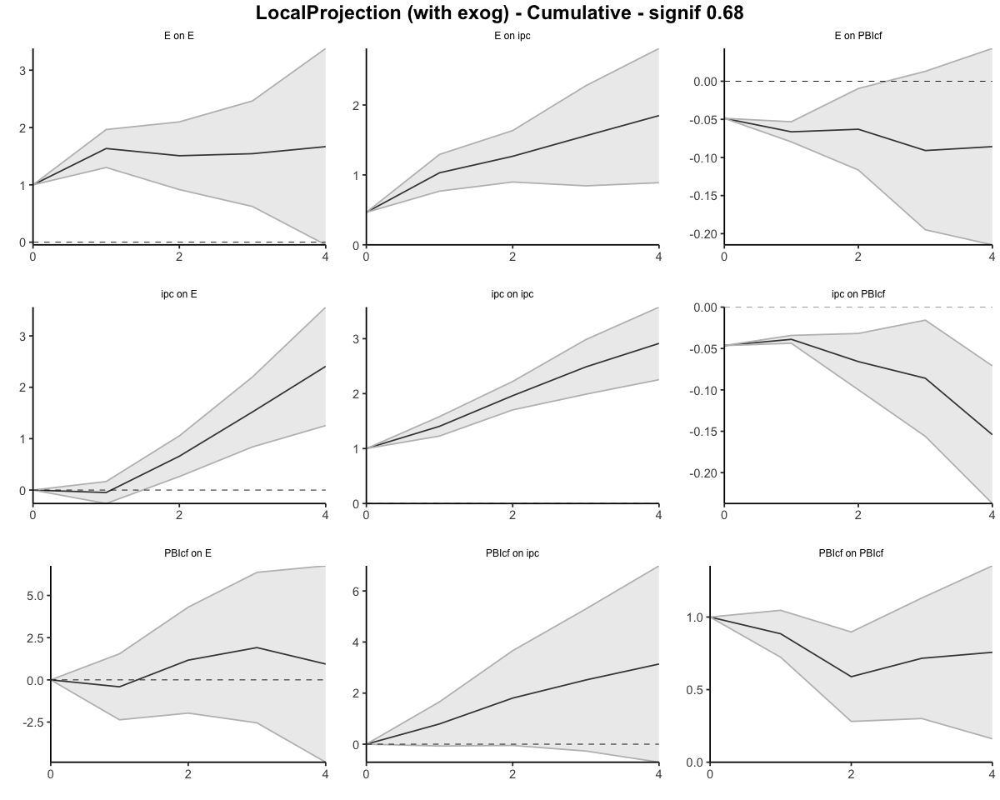

In [76]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("E", "ipc", "PBIcf"), exog=c("impp_usa"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

#### impp_usa más exógena y el resto endógenas - 1 lag

Bootstrap por bloques circular: 500 réplicas, bloques de 10 años...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 1 rezagos, exógenas: impp_usa )

Lineal
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4645         0.4645       1.0000
         1              1.0303         0.6306       1.6339
         2              1.2665         0.8400       1.5078
         3              1.5599         1.0105       1.5436
         4              1.8488         1.1093       1.6666
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4645             0.4645
                  0.5658             0.1661
                  0.2362             0.2094
                  0.2934             0.1705
                  0.2889             0.0988


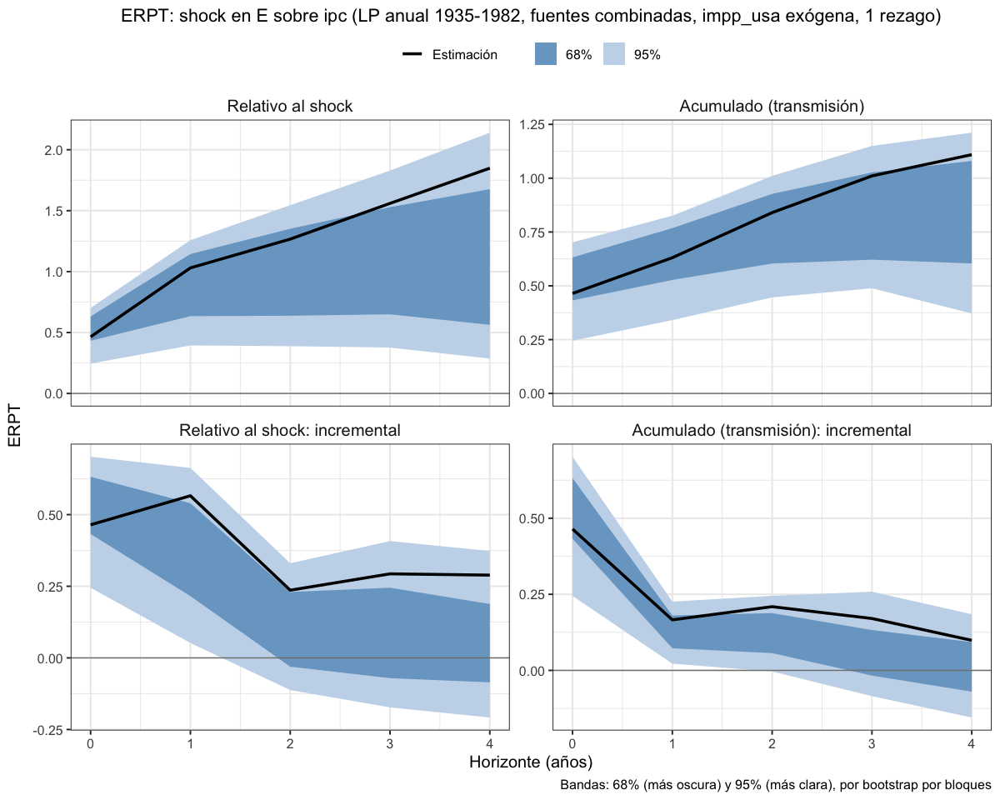

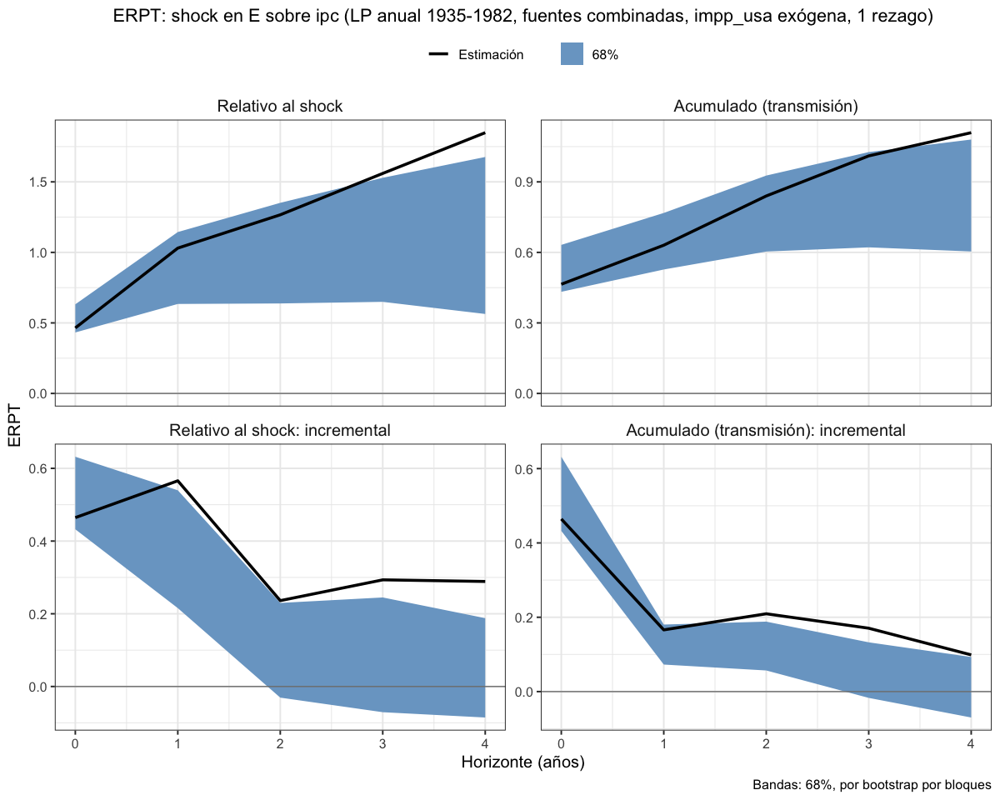

In [77]:
# Anual 1935–1982, fuentes combinadas. impp_usa exógena y el resto endógenas, 1 rezago
lp_erpt_anual_comb_35_82_exog_p1 <- erpt_lp(df_ERPT_Arg_1935_1982, endog = c("E", "ipc", "PBIcf"), exog = c("impp_usa"),
                                            fixed_lags = 1, horizons = 4, reps = 500, unidad = "años")
saveRDS(lp_erpt_anual_comb_35_82_exog_p1, "lp_erpt_anual_comb_35_82_exog_p1.rds")
titulo_comb_35_82_exog <- "ERPT: shock en E sobre ipc (LP anual 1935-1982, fuentes combinadas, impp_usa exógena, 1 rezago)"
graficar_erpt_lp(lp_erpt_anual_comb_35_82_exog_p1, titulo = titulo_comb_35_82_exog,
                 archivo = "lp_erpt_anual_comb_35_82_exog_p1")
graficar_erpt_lp(lp_erpt_anual_comb_35_82_exog_p1, titulo = titulo_comb_35_82_exog, niveles = 0.68,
                 archivo = "lp_erpt_anual_comb_35_82_exog_p1_68")

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.00000000
12,ipc,E,1,-0.4017803,-0.76255188,-0.04100866
13,ipc,E,2,0.4407750,0.18744835,0.69410165
14,ipc,E,3,0.9641627,0.44479993,1.48352539
15,ipc,E,4,0.2833472,-0.02630464,0.59299907


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.0000000,0.0000000
22,PBIcf,E,1,0.5182089,-0.7328220,1.7692399
23,PBIcf,E,2,1.5606748,0.2313635,2.8899861
24,PBIcf,E,3,0.5599585,-0.4424381,1.5623550
25,PBIcf,E,4,-1.8099974,-3.3341262,-0.2858687


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4546320,0.45463202,0.4546320
2,E,ipc,1,0.4921213,0.33830309,0.6459395
3,E,ipc,2,0.1897149,0.07783551,0.3015942
4,E,ipc,3,0.2645131,-0.26981148,0.7988377
5,E,ipc,4,0.2910642,0.04399271,0.5381357


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.0000000,0.0000000,0.000000
27,PBIcf,ipc,1,1.2424160,0.4999344,1.984898
28,PBIcf,ipc,2,0.7180243,-0.6065452,2.042594
29,PBIcf,ipc,3,0.6007412,-0.3177505,1.519233
30,PBIcf,ipc,4,0.6080301,-0.4770665,1.693127


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.0410714423,-0.04107144,-0.04107144
7,E,PBIcf,1,-0.0024203425,-0.02928290,0.02444222
8,E,PBIcf,2,0.0041606674,-0.05309551,0.06141685
9,E,PBIcf,3,-0.0370479122,-0.10368535,0.02958953
10,E,PBIcf,4,0.0008737689,-0.03571976,0.03746730


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.046178422,-0.04617842,-0.046178422
17,ipc,PBIcf,1,0.084744313,0.05906119,0.110427431
18,ipc,PBIcf,2,-0.009212969,-0.06696856,0.048542621
19,ipc,PBIcf,3,0.008852949,-0.04703618,0.064742077
20,ipc,PBIcf,4,-0.036225834,-0.08073310,0.008281427


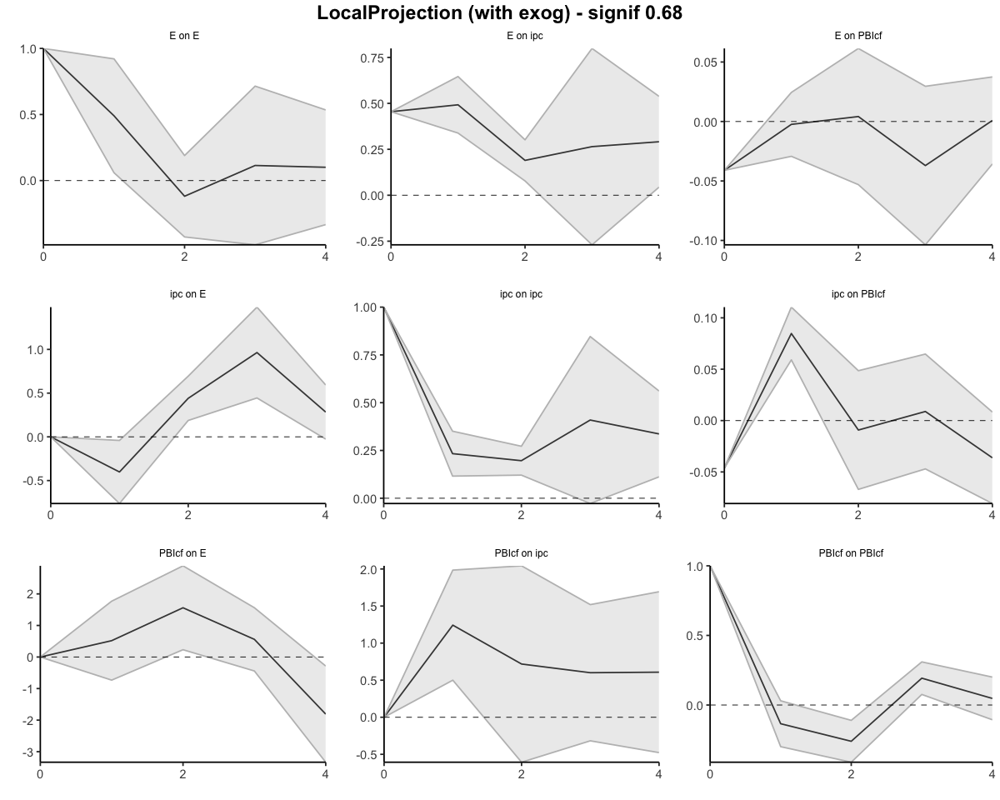

In [78]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("E", "ipc", "PBIcf"), exog=c("impp_usa"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.00000000
12,ipc,E,1,-0.40178027,-0.7625519,-0.04100866
13,ipc,E,2,0.03899473,-0.5751035,0.65309298
14,ipc,E,3,1.00315738,-0.1303036,2.13661837
15,ipc,E,4,1.28650460,-0.1566082,2.72961745


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.0000000,0.000000
22,PBIcf,E,1,0.5182089,-0.7328220,1.769240
23,PBIcf,E,2,2.0788837,-0.5014585,4.659226
24,PBIcf,E,3,2.6388422,-0.9438965,6.221581
25,PBIcf,E,4,0.8288448,-4.2780227,5.935712


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4546320,0.4546320,0.454632
2,E,ipc,1,0.9467533,0.7929351,1.100571
3,E,ipc,2,1.1364682,0.8707706,1.402166
4,E,ipc,3,1.4009813,0.6009591,2.201003
5,E,ipc,4,1.6920455,0.6449518,2.739139


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.0000000,0.000000
27,PBIcf,ipc,1,1.242416,0.4999344,1.984898
28,PBIcf,ipc,2,1.960440,-0.1066108,4.027491
29,PBIcf,ipc,3,2.561182,-0.4243613,5.546724
30,PBIcf,ipc,4,3.169212,-0.9014278,7.239851


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.04107144,-0.04107144,-0.04107144
7,E,PBIcf,1,-0.04349178,-0.07035435,-0.01662922
8,E,PBIcf,2,-0.03933112,-0.12344986,0.04478762
9,E,PBIcf,3,-0.07637903,-0.22713521,0.07437715
10,E,PBIcf,4,-0.07550526,-0.26285497,0.11184445


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.046178422,-0.04617842,-0.04617842
17,ipc,PBIcf,1,0.038565891,0.01288277,0.06424901
18,ipc,PBIcf,2,0.029352922,-0.05408579,0.11279163
19,ipc,PBIcf,3,0.038205872,-0.10112196,0.17753371
20,ipc,PBIcf,4,0.001980038,-0.18185506,0.18581513


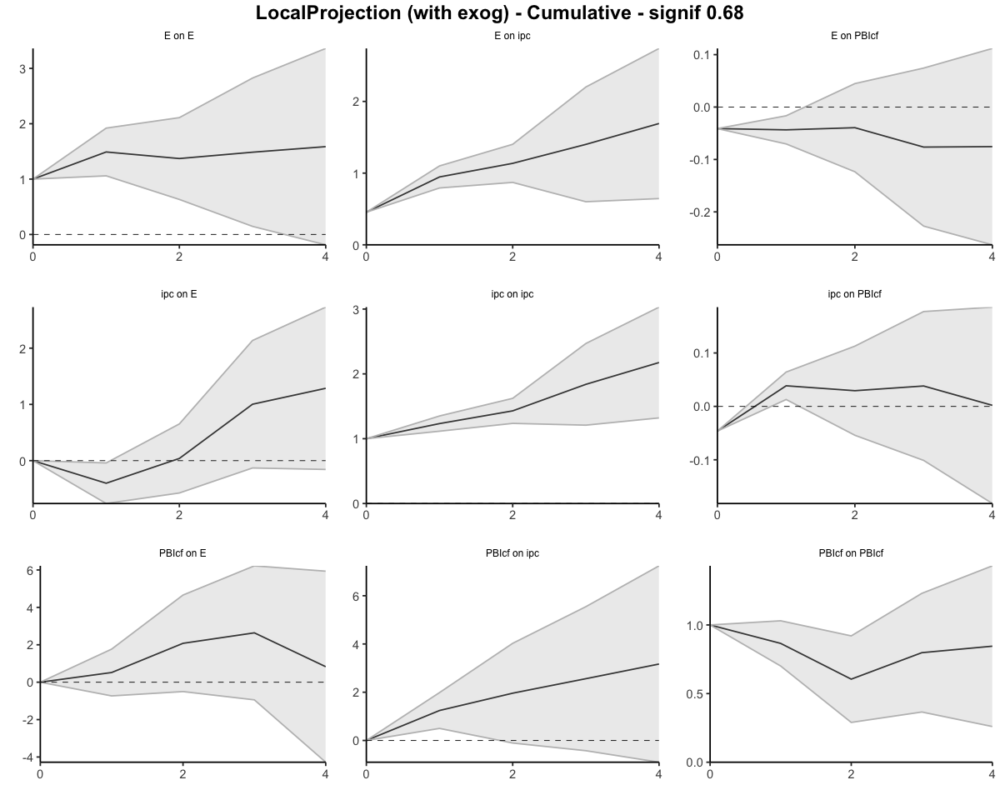

In [79]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("E", "ipc", "PBIcf"), exog=c("impp_usa"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

#### impp_usa más exógena y el resto endógenas - 2 lags

Bootstrap por bloques circular: 500 réplicas, bloques de 12 años...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 2 rezagos, exógenas: impp_usa )

Lineal
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4546         0.4546       1.0000
         1              0.9468         0.6353       1.4902
         2              1.1365         0.8286       1.3716
         3              1.4010         0.9428       1.4859
         4              1.6920         1.0665       1.5866
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4546             0.4546
                  0.4921             0.1807
                  0.1897             0.1933
                  0.2645             0.1143
                  0.2911             0.1236


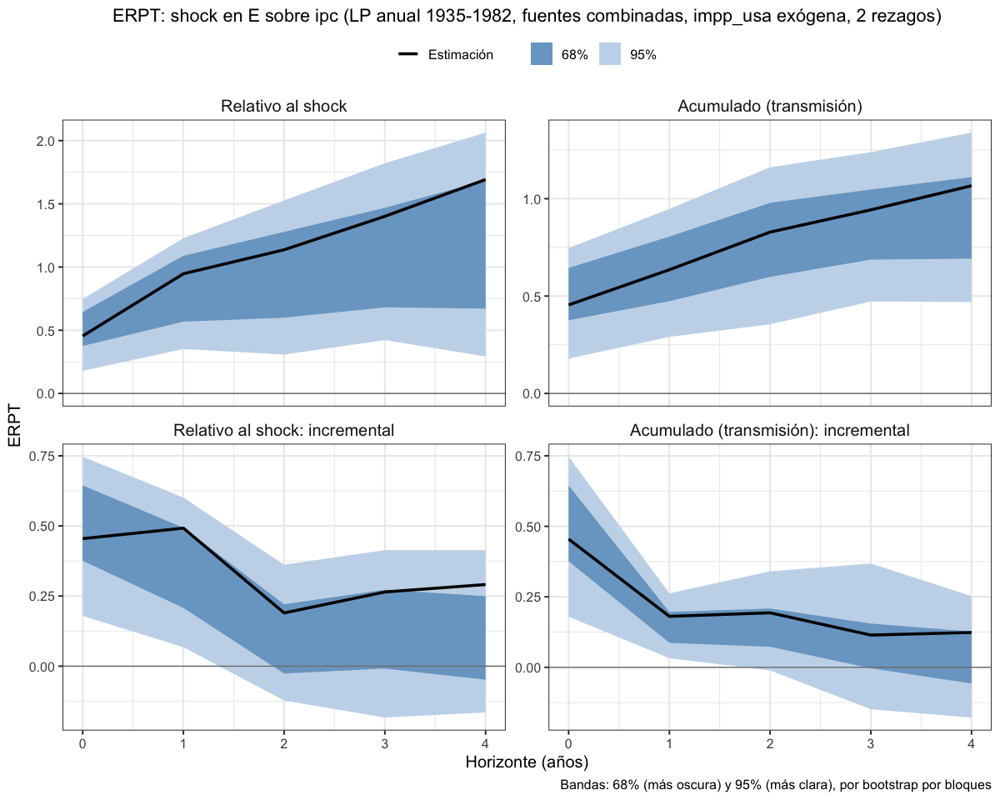

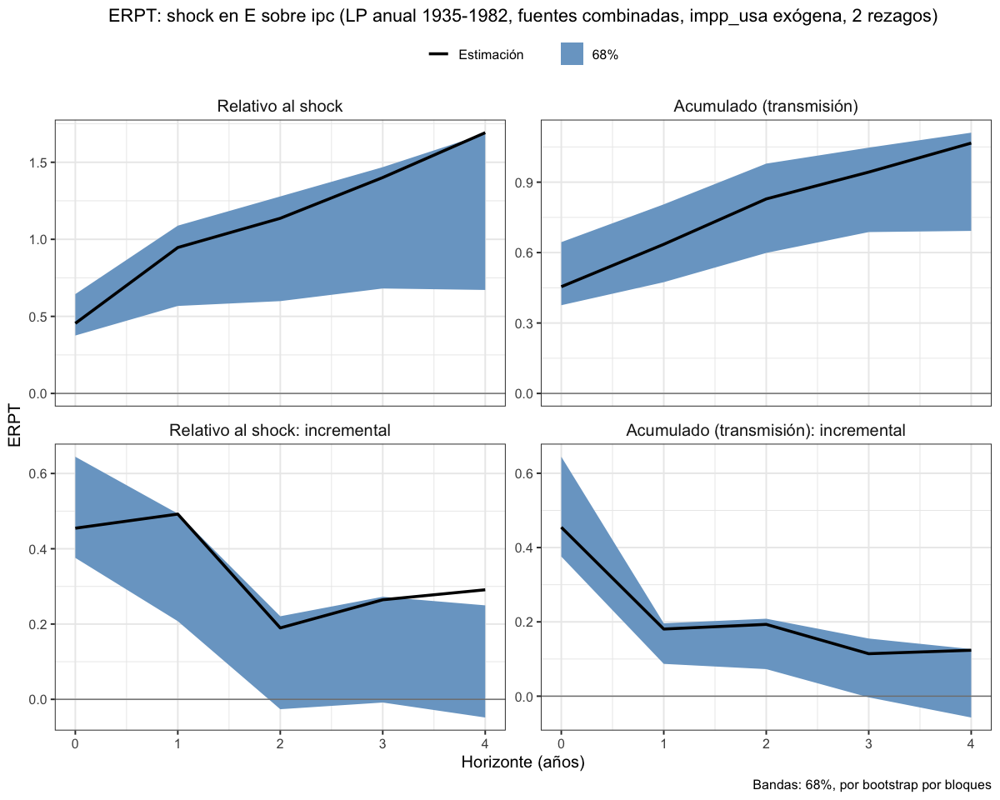

In [80]:
# Anual 1935–1982, fuentes combinadas. impp_usa exógena y el resto endógenas, 2 rezagos
lp_erpt_anual_comb_35_82_exog_p2 <- erpt_lp(df_ERPT_Arg_1935_1982, endog = c("E", "ipc", "PBIcf"), exog = c("impp_usa"),
                                            fixed_lags = 2, horizons = 4, reps = 500, unidad = "años")
saveRDS(lp_erpt_anual_comb_35_82_exog_p2, "lp_erpt_anual_comb_35_82_exog_p2.rds")
titulo_comb_35_82_exog_p2 <- "ERPT: shock en E sobre ipc (LP anual 1935-1982, fuentes combinadas, impp_usa exógena, 2 rezagos)"
graficar_erpt_lp(lp_erpt_anual_comb_35_82_exog_p2, titulo = titulo_comb_35_82_exog_p2,
                 archivo = "lp_erpt_anual_comb_35_82_exog_p2")
graficar_erpt_lp(lp_erpt_anual_comb_35_82_exog_p2, titulo = titulo_comb_35_82_exog_p2, niveles = 0.68,
                 archivo = "lp_erpt_anual_comb_35_82_exog_p2_68")

### 1935-1987. Todas endógenas - Selected orders: 1 lag

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,52,"impp_usa, E, ipc, PBIcf",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-1.2681274,-1.2681274,-1.268127
2,impp_usa,E,1,0.5421601,-0.5863951,1.670715
3,impp_usa,E,2,1.9271215,1.2745866,2.579656
4,impp_usa,E,3,1.1430519,0.7483578,1.537746
5,impp_usa,E,4,1.1362653,0.4179303,1.854600


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.00000000,0.0000000
37,ipc,E,1,0.05397651,-0.19650288,0.3044559
38,ipc,E,2,0.36230900,0.06441552,0.6602025
39,ipc,E,3,0.34904007,-0.23979085,0.9378710
40,ipc,E,4,0.88865373,0.61444922,1.1628582


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.0000000,0.0000000
52,PBIcf,E,1,2.2250828,-0.2006319,4.6507975
53,PBIcf,E,2,0.7933631,-0.3739553,1.9606815
54,PBIcf,E,3,-2.4542828,-5.0458747,0.1373091
55,PBIcf,E,4,-2.9920513,-5.0388851,-0.9452175


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
56,PBIcf,ipc,0,0.0000000,0.0000000,0.00000000
57,PBIcf,ipc,1,2.5978468,1.1176290,4.07806466
58,PBIcf,ipc,2,0.4676756,-0.4419116,1.37726276
59,PBIcf,ipc,3,-2.2525939,-4.5991213,0.09393354
60,PBIcf,ipc,4,-1.2903418,-3.0722603,0.49157673


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,E,PBIcf,0,-0.036684607,-0.03668461,-0.03668461
27,E,PBIcf,1,-0.015486255,-0.02931960,-0.00165291
28,E,PBIcf,2,-0.005059785,-0.04154646,0.03142688
29,E,PBIcf,3,-0.028611314,-0.07597759,0.01875496
30,E,PBIcf,4,-0.010581812,-0.04349859,0.02233496


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,impp_usa,PBIcf,0,0.14832479,0.14832479,0.148324790
12,impp_usa,PBIcf,1,-0.08409137,-0.14917225,-0.019010501
13,impp_usa,PBIcf,2,-0.10262711,-0.12261177,-0.082642455
14,impp_usa,PBIcf,3,-0.01525995,-0.02426718,-0.006252724
15,impp_usa,PBIcf,4,-0.01433634,-0.06000114,0.031328459


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
41,ipc,PBIcf,0,-0.019516492,-0.01951649,-0.0195164920
42,ipc,PBIcf,1,-0.002760117,-0.01166972,0.0061494893
43,ipc,PBIcf,2,-0.025777580,-0.05132374,-0.0002314209
44,ipc,PBIcf,3,0.007006706,-0.02626661,0.0402800224
45,ipc,PBIcf,4,-0.039961173,-0.06443759,-0.0154847613


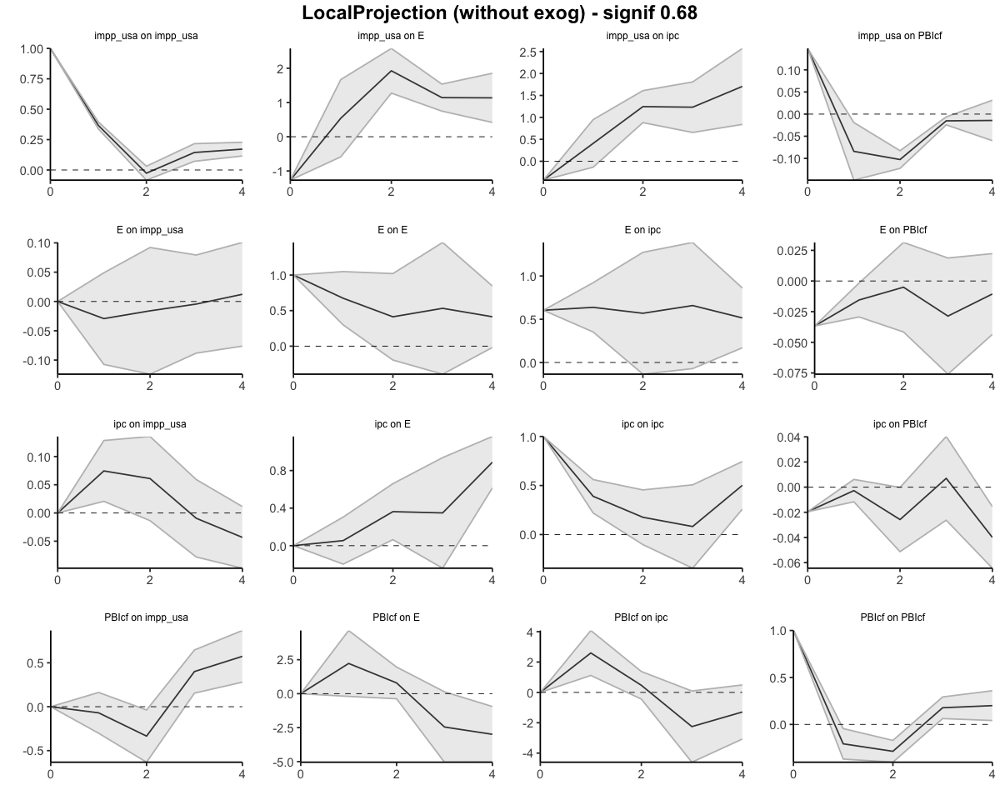

In [81]:
res <- run_lp_model(df_ERPT_Arg_1935_1987, endog=c("impp_usa", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,52,"impp_usa, E, ipc, PBIcf",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-1.2681274,-1.2681274,-1.2681274
2,impp_usa,E,1,-0.7259674,-1.8545225,0.4025878
3,impp_usa,E,2,1.2011542,-0.5799360,2.9822443
4,impp_usa,E,3,2.3442060,0.1684219,4.5199902
5,impp_usa,E,4,3.4804713,0.5863521,6.3745904


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.0000000
37,ipc,E,1,0.05397651,-0.1965029,0.3044559
38,ipc,E,2,0.41628550,-0.1320874,0.9646584
39,ipc,E,3,0.76532557,-0.3718782,1.9025294
40,ipc,E,4,1.65397930,0.2425710,3.0653876


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.0000000,0.000000
52,PBIcf,E,1,2.2250828,-0.2006319,4.650798
53,PBIcf,E,2,3.0184459,-0.5745872,6.611479
54,PBIcf,E,3,0.5641631,-5.6204619,6.748788
55,PBIcf,E,4,-2.4278881,-10.6593469,5.803571


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
56,PBIcf,ipc,0,0.0000000,0.0000000,0.000000
57,PBIcf,ipc,1,2.5978468,1.1176290,4.078065
58,PBIcf,ipc,2,3.0655224,0.6757174,5.455327
59,PBIcf,ipc,3,0.8129285,-3.9234039,5.549261
60,PBIcf,ipc,4,-0.4774132,-6.9956642,6.040838


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,E,PBIcf,0,-0.03668461,-0.03668461,-0.036684607
27,E,PBIcf,1,-0.05217086,-0.06600421,-0.038337517
28,E,PBIcf,2,-0.05723065,-0.10755066,-0.006910633
29,E,PBIcf,3,-0.08584196,-0.18352825,0.011844329
30,E,PBIcf,4,-0.09642377,-0.22702684,0.034179290


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,impp_usa,PBIcf,0,0.14832479,0.1483247900,0.14832479
12,impp_usa,PBIcf,1,0.06423342,-0.0008474584,0.12931429
13,impp_usa,PBIcf,2,-0.03839370,-0.1234592290,0.04667183
14,impp_usa,PBIcf,3,-0.05365365,-0.1477264093,0.04041911
15,impp_usa,PBIcf,4,-0.06798999,-0.2077275535,0.07174757


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
41,ipc,PBIcf,0,-0.01951649,-0.01951649,-0.01951649
42,ipc,PBIcf,1,-0.02227661,-0.03118621,-0.01336700
43,ipc,PBIcf,2,-0.04805419,-0.08250995,-0.01359842
44,ipc,PBIcf,3,-0.04104748,-0.10877657,0.02668160
45,ipc,PBIcf,4,-0.08100866,-0.17321415,0.01119684


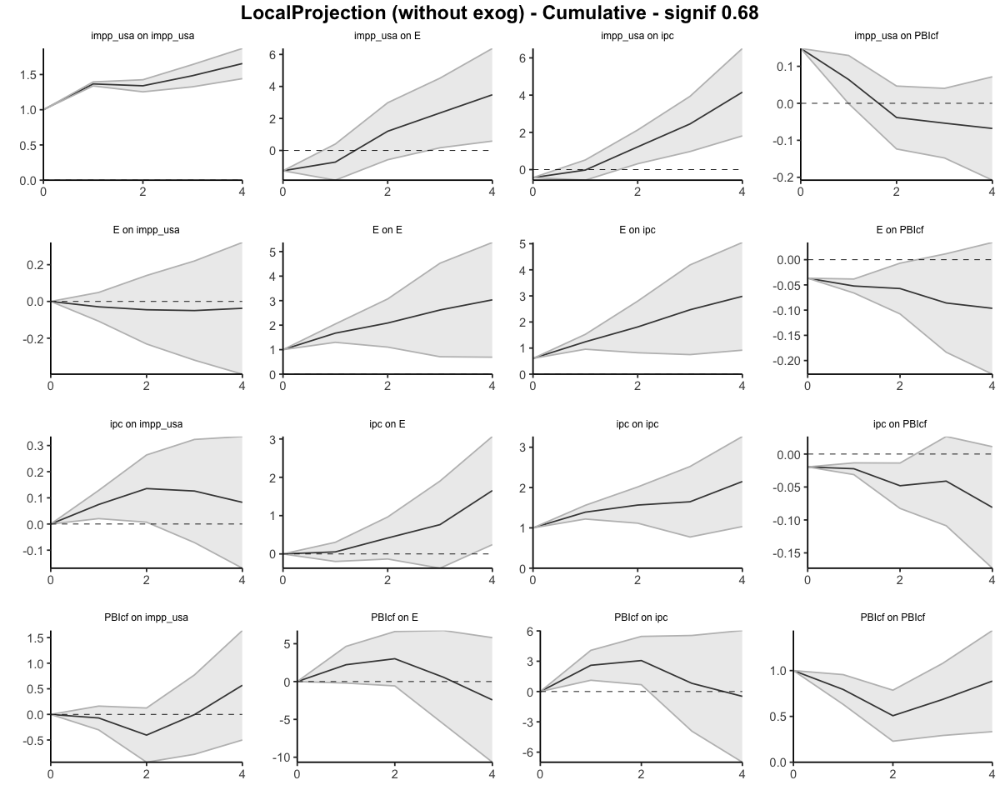

In [82]:
res <- run_lp_model(df_ERPT_Arg_1935_1987, endog=c("impp_usa", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

#### Todas endógenas - 1 lag

Bootstrap por bloques circular: 500 réplicas, bloques de 10 años...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 1 rezagos )

Lineal
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.6038         0.6038       1.0000
         1              1.2415         0.7417       1.6738
         2              1.8105         0.8676       2.0868
         3              2.4690         0.9427       2.6191
         4              2.9842         0.9840       3.0328
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.6038             0.6038
                  0.6376             0.1379
                  0.5690             0.1259
                  0.6585             0.0751
                  0.5152             0.0413


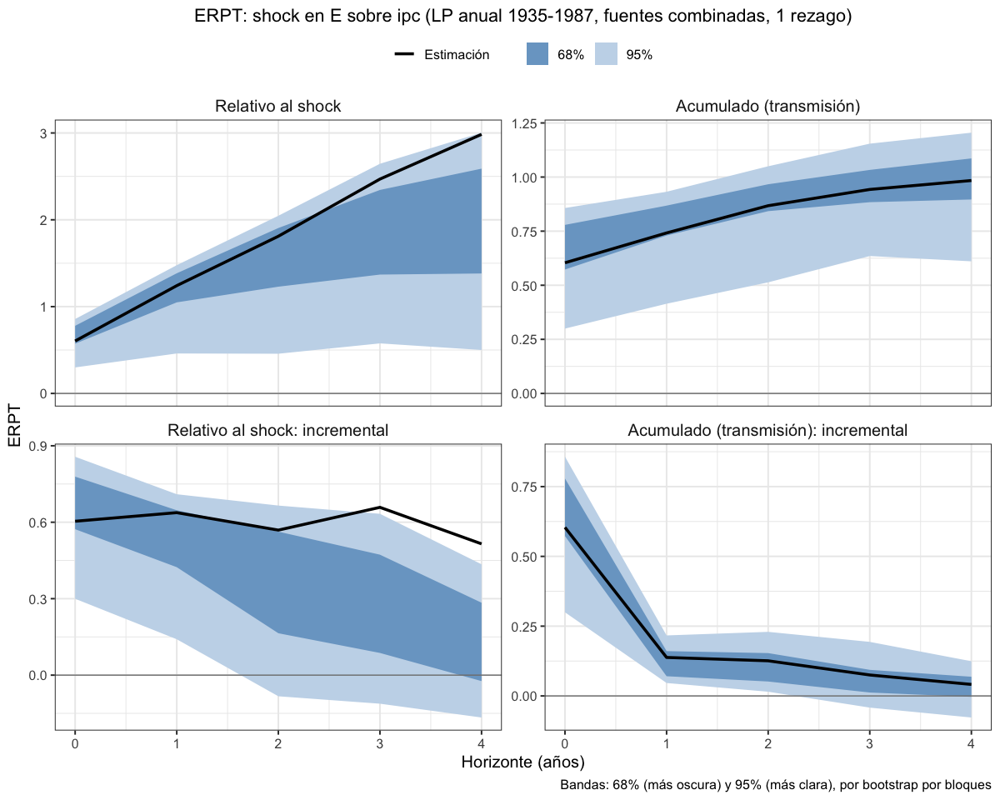

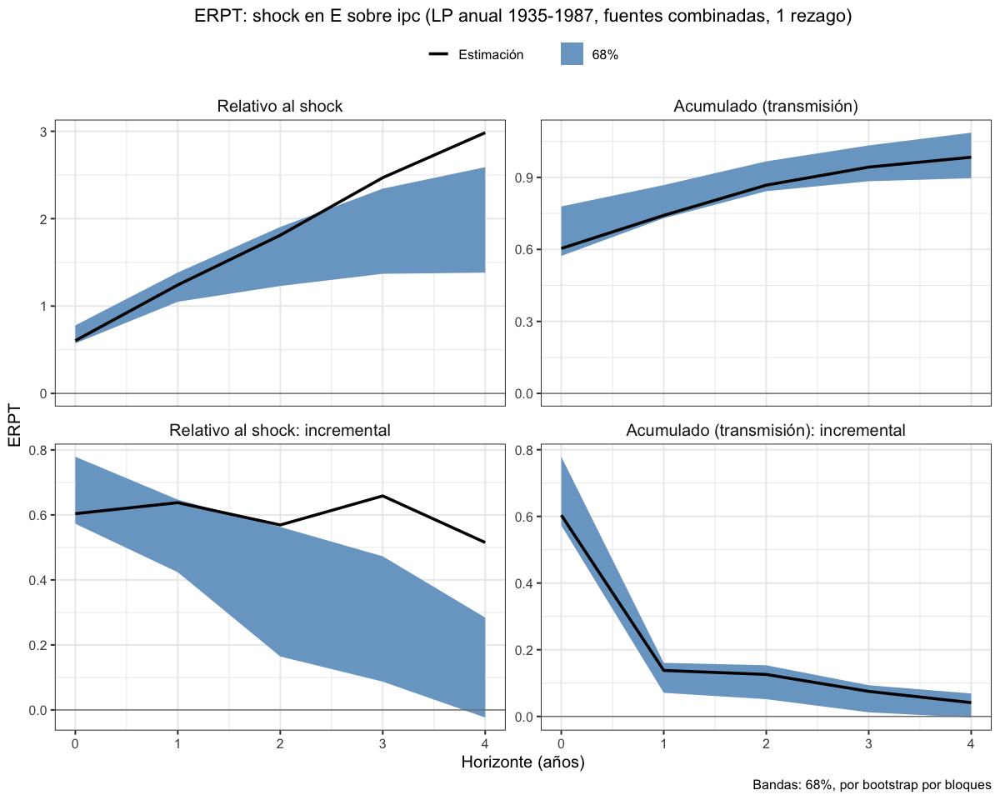

In [83]:
# Anual 1935–1987, fuentes combinadas. Todas endógenas, 1 rezago
lp_erpt_anual_comb_35_87_endog_p1 <- erpt_lp(df_ERPT_Arg_1935_1987, endog = c("impp_usa", "E", "ipc", "PBIcf"),
                                             fixed_lags = 1, horizons = 4, reps = 500, unidad = "años")
saveRDS(lp_erpt_anual_comb_35_87_endog_p1, "lp_erpt_anual_comb_35_87_endog_p1.rds")
titulo_comb_35_87 <- "ERPT: shock en E sobre ipc (LP anual 1935-1987, fuentes combinadas, 1 rezago)"
graficar_erpt_lp(lp_erpt_anual_comb_35_87_endog_p1, titulo = titulo_comb_35_87,
                 archivo = "lp_erpt_anual_comb_35_87_endog_p1")
graficar_erpt_lp(lp_erpt_anual_comb_35_87_endog_p1, titulo = titulo_comb_35_87, niveles = 0.68,
                 archivo = "lp_erpt_anual_comb_35_87_endog_p1_68")

### 1935-1987. 1 exógena y el resto endógenas - Selected orders: 1 lag

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,52,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.00000000,0.0000000
12,ipc,E,1,0.07731643,-0.19860741,0.3532403
13,ipc,E,2,0.37063095,0.06049293,0.6807690
14,ipc,E,3,0.32329597,-0.29271935,0.9393113
15,ipc,E,4,0.85726872,0.56159403,1.1529434


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.0000000,0.0000000
22,PBIcf,E,1,2.2250828,-0.2006319,4.6507975
23,PBIcf,E,2,0.7933631,-0.3739553,1.9606815
24,PBIcf,E,3,-2.4542828,-5.0458747,0.1373091
25,PBIcf,E,4,-2.9920513,-5.0388851,-0.9452175


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.5862467,0.58624666,0.5862467
2,E,ipc,1,0.6160394,0.34227764,0.8898012
3,E,ipc,2,0.5632984,-0.13100701,1.2576039
4,E,ipc,3,0.6698358,-0.03877143,1.3784430
5,E,ipc,4,0.5136778,0.18269810,0.8446576


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.0000000,0.0000000,0.00000000
27,PBIcf,ipc,1,2.5978468,1.1176290,4.07806466
28,PBIcf,ipc,2,0.4676756,-0.4419116,1.37726276
29,PBIcf,ipc,3,-2.2525939,-4.5991213,0.09393354
30,PBIcf,ipc,4,-1.2903418,-3.0722603,0.49157673


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.04202213,-0.04202213,-0.04202213
7,E,PBIcf,1,-0.01426584,-0.02702137,-0.00151031
8,E,PBIcf,2,-0.00298148,-0.03835989,0.03239693
9,E,PBIcf,3,-0.02974313,-0.07587102,0.01638475
10,E,PBIcf,4,-0.01101729,-0.04260334,0.02056877


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.009027031,-0.009027031,-0.009027031
17,ipc,PBIcf,1,-0.004924182,-0.015535011,0.005686648
18,ipc,PBIcf,2,-0.028779033,-0.055542868,-0.002015198
19,ipc,PBIcf,3,0.008869392,-0.025611193,0.043349977
20,ipc,PBIcf,4,-0.037860507,-0.064000093,-0.011720921


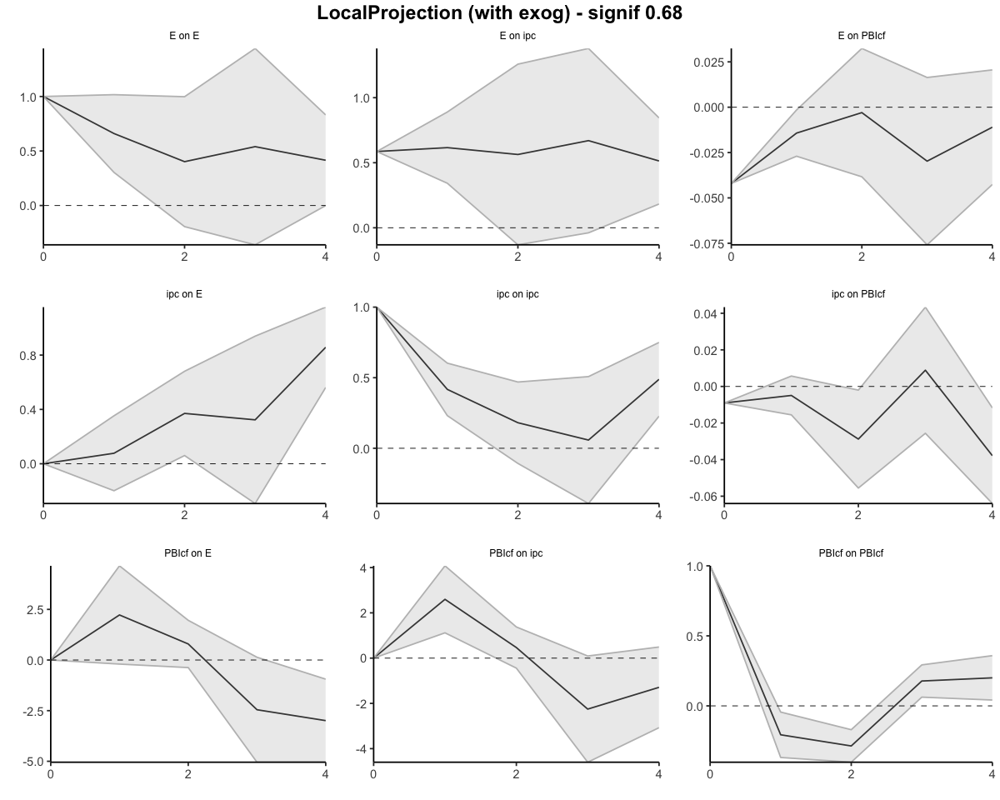

In [84]:
res <- run_lp_model(df_ERPT_Arg_1935_1987, endog=c("E", "ipc", "PBIcf"), exog=c("impp_usa"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,52,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.0000000
12,ipc,E,1,0.07731643,-0.1986074,0.3532403
13,ipc,E,2,0.44794737,-0.1381145,1.0340092
14,ipc,E,3,0.77124334,-0.4308338,1.9733205
15,ipc,E,4,1.62851206,0.1307602,3.1262639


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.0000000,0.000000
22,PBIcf,E,1,2.2250828,-0.2006319,4.650798
23,PBIcf,E,2,3.0184459,-0.5745872,6.611479
24,PBIcf,E,3,0.5641631,-5.6204619,6.748788
25,PBIcf,E,4,-2.4278881,-10.6593469,5.803571


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.5862467,0.5862467,0.5862467
2,E,ipc,1,1.2022861,0.9285243,1.4760478
3,E,ipc,2,1.7655845,0.7975173,2.7336517
4,E,ipc,3,2.4354203,0.7587459,4.1120947
5,E,ipc,4,2.9490981,0.9414440,4.9567522


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.0000000,0.0000000,0.000000
27,PBIcf,ipc,1,2.5978468,1.1176290,4.078065
28,PBIcf,ipc,2,3.0655224,0.6757174,5.455327
29,PBIcf,ipc,3,0.8129285,-3.9234039,5.549261
30,PBIcf,ipc,4,-0.4774132,-6.9956642,6.040838


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.04202213,-0.04202213,-0.042022132
7,E,PBIcf,1,-0.05628797,-0.06904350,-0.043532443
8,E,PBIcf,2,-0.05926945,-0.10740339,-0.011135511
9,E,PBIcf,3,-0.08901259,-0.18327441,0.005249243
10,E,PBIcf,4,-0.10002987,-0.22587776,0.025818011


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.009027031,-0.009027031,-0.009027031
17,ipc,PBIcf,1,-0.013951213,-0.024562042,-0.003340383
18,ipc,PBIcf,2,-0.042730246,-0.080104910,-0.005355581
19,ipc,PBIcf,3,-0.033860854,-0.105716103,0.037994396
20,ipc,PBIcf,4,-0.071721361,-0.169716196,0.026273475


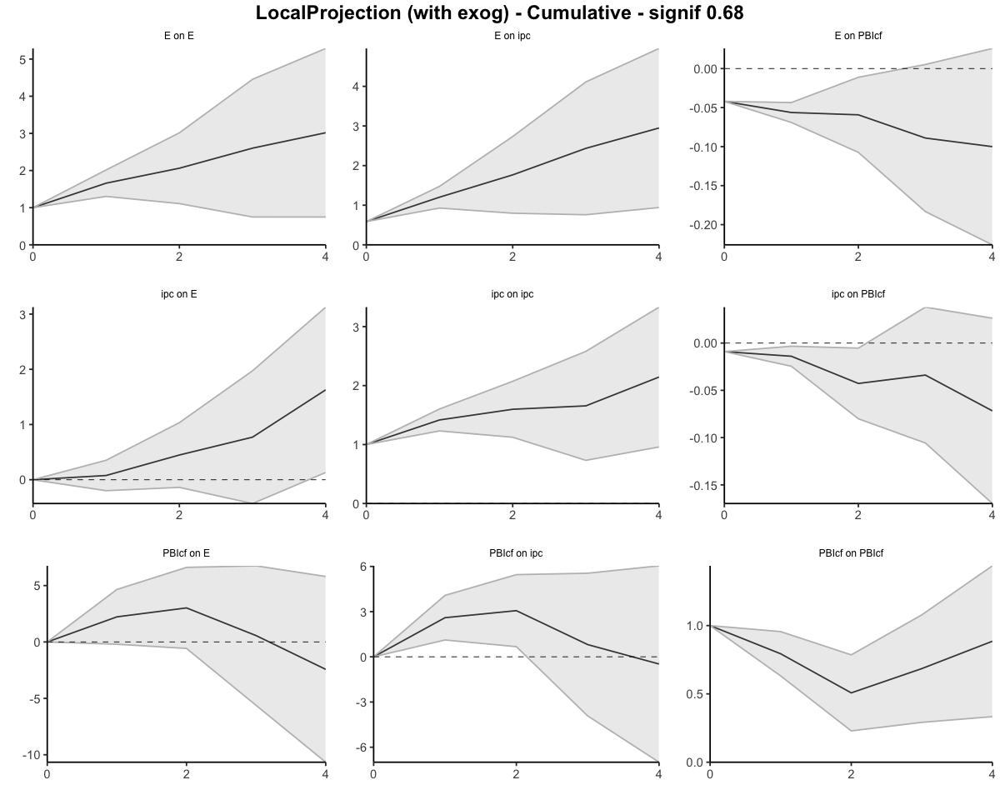

In [85]:
res <- run_lp_model(df_ERPT_Arg_1935_1987, endog=c("E", "ipc", "PBIcf"), exog=c("impp_usa"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

#### impp_usa exógena y el resto endógenas - 1 lag

Bootstrap por bloques circular: 500 réplicas, bloques de 10 años...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 1 rezagos, exógenas: impp_usa )

Lineal
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.5862         0.5862       1.0000
         1              1.2023         0.7242       1.6602
         2              1.7656         0.8561       2.0623
         3              2.4354         0.9358       2.6024
         4              2.9491         0.9773       3.0175
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.5862             0.5862
                  0.6160             0.1379
                  0.5633             0.1319
                  0.6698             0.0797
                  0.5137             0.0415


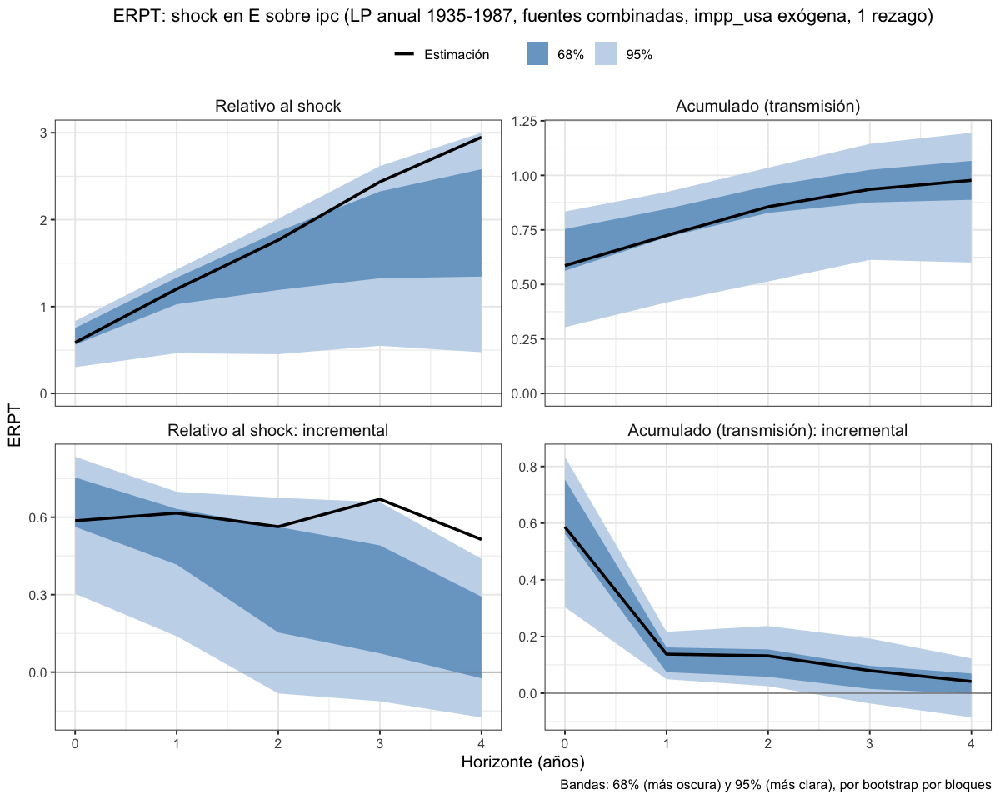

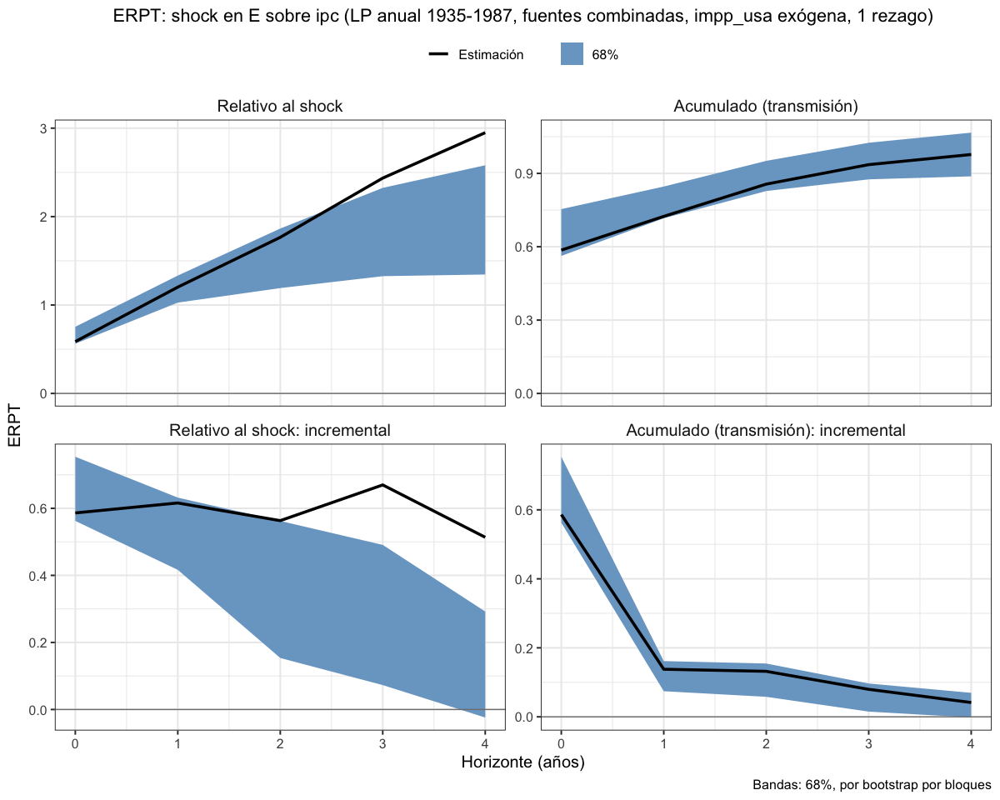

In [86]:
# Anual 1935–1987, fuentes combinadas. impp_usa exógena y el resto endógenas, 1 rezago
lp_erpt_anual_comb_35_87_exog_p1 <- erpt_lp(df_ERPT_Arg_1935_1987, endog = c("E", "ipc", "PBIcf"), exog = c("impp_usa"),
                                            fixed_lags = 1, horizons = 4, reps = 500, unidad = "años")
saveRDS(lp_erpt_anual_comb_35_87_exog_p1, "lp_erpt_anual_comb_35_87_exog_p1.rds")
titulo_comb_35_87_exog <- "ERPT: shock en E sobre ipc (LP anual 1935-1987, fuentes combinadas, impp_usa exógena, 1 rezago)"
graficar_erpt_lp(lp_erpt_anual_comb_35_87_exog_p1, titulo = titulo_comb_35_87_exog,
                 archivo = "lp_erpt_anual_comb_35_87_exog_p1")
graficar_erpt_lp(lp_erpt_anual_comb_35_87_exog_p1, titulo = titulo_comb_35_87_exog, niveles = 0.68,
                 archivo = "lp_erpt_anual_comb_35_87_exog_p1_68")

### 1935-1990. Todas endógenas - Selected orders: 1 lag

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"impp_usa, E, ipc, PBIcf",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-0.9037995,-0.9037995,-0.9037995
2,impp_usa,E,1,0.7787009,-0.3787446,1.9361465
3,impp_usa,E,2,2.0828685,1.2448598,2.9208772
4,impp_usa,E,3,0.7879352,-0.3356742,1.9115445
5,impp_usa,E,4,0.5831436,-0.2940113,1.4602986


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.00000000,0.0000000
37,ipc,E,1,0.09044492,-0.15422870,0.3351185
38,ipc,E,2,0.46124414,0.09621966,0.8262686
39,ipc,E,3,0.64304726,0.00443263,1.2816619
40,ipc,E,4,1.27415232,0.99740956,1.5508951


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.00000000,0.0000000,0.0000000
52,PBIcf,E,1,1.89912660,-0.4458051,4.2440584
53,PBIcf,E,2,2.04910620,0.4876915,3.6105209
54,PBIcf,E,3,0.07737643,-3.2555813,3.4103342
55,PBIcf,E,4,-2.95526116,-5.4128759,-0.4976464


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
56,PBIcf,ipc,0,0.0000000,0.0000000,0.000000
57,PBIcf,ipc,1,2.4237750,0.9685301,3.879020
58,PBIcf,ipc,2,1.5458925,0.2710475,2.820737
59,PBIcf,ipc,3,0.3339236,-2.2890320,2.956879
60,PBIcf,ipc,4,-0.6493261,-2.7652936,1.466641


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,E,PBIcf,0,-0.03430580,-0.03430580,-0.034305804
27,E,PBIcf,1,-0.01623614,-0.03120039,-0.001271883
28,E,PBIcf,2,-0.01188158,-0.05095799,0.027194843
29,E,PBIcf,3,-0.02579885,-0.07548697,0.023889279
30,E,PBIcf,4,-0.01786109,-0.05017482,0.014452640


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,impp_usa,PBIcf,0,0.136962393,0.13696239,0.13696239
12,impp_usa,PBIcf,1,-0.088737864,-0.15655800,-0.02091773
13,impp_usa,PBIcf,2,-0.105983185,-0.13679105,-0.07517532
14,impp_usa,PBIcf,3,-0.007822053,-0.04244571,0.02680160
15,impp_usa,PBIcf,4,-0.005076483,-0.06340230,0.05324933


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
41,ipc,PBIcf,0,-0.0101569700,-0.01015697,-0.010156970
42,ipc,PBIcf,1,-0.0041160426,-0.01476107,0.006528986
43,ipc,PBIcf,2,-0.0304598462,-0.05679612,-0.004123569
44,ipc,PBIcf,3,-0.0005486967,-0.03421141,0.033114013
45,ipc,PBIcf,4,-0.0476458312,-0.06929901,-0.025992647


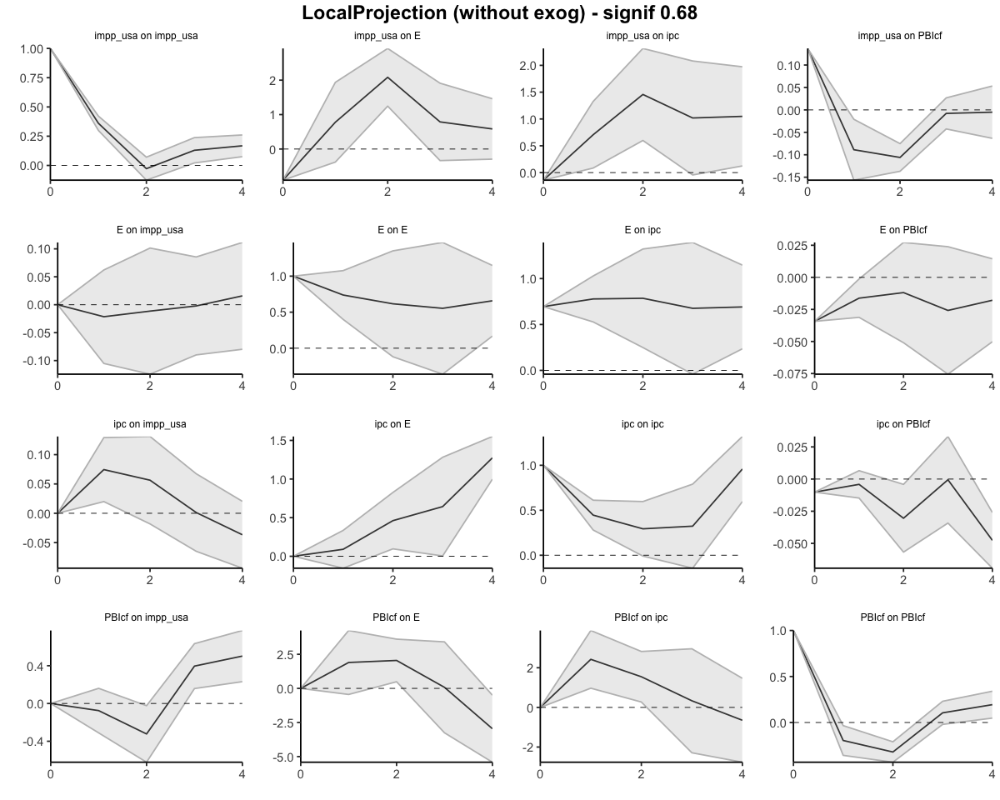

In [87]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("impp_usa", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"impp_usa, E, ipc, PBIcf",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-0.9037995,-0.90379947,-0.9037995
2,impp_usa,E,1,-0.1250985,-1.28254411,1.0323471
3,impp_usa,E,2,1.9577700,-0.03768429,3.9532243
4,impp_usa,E,3,2.7457051,-0.37335852,5.8647688
5,impp_usa,E,4,3.3288488,-0.66736985,7.3250674


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.00000000,0.0000000
37,ipc,E,1,0.09044492,-0.15422870,0.3351185
38,ipc,E,2,0.55168906,-0.05800905,1.1613872
39,ipc,E,3,1.19473632,-0.05357642,2.4430491
40,ipc,E,4,2.46888864,0.94383314,3.9939441


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.000000,0.00000000,0.000000
52,PBIcf,E,1,1.899127,-0.44580514,4.244058
53,PBIcf,E,2,3.948233,0.04188637,7.854579
54,PBIcf,E,3,4.025609,-3.21369493,11.264913
55,PBIcf,E,4,1.070348,-8.62657083,10.767267


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
56,PBIcf,ipc,0,0.000000,0.0000000,0.000000
57,PBIcf,ipc,1,2.423775,0.9685301,3.879020
58,PBIcf,ipc,2,3.969667,1.2395776,6.699757
59,PBIcf,ipc,3,4.303591,-1.0494544,9.656637
60,PBIcf,ipc,4,3.654265,-3.8147479,11.123278


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,E,PBIcf,0,-0.03430580,-0.03430580,-0.034305804
27,E,PBIcf,1,-0.05054194,-0.06550619,-0.035577687
28,E,PBIcf,2,-0.06242352,-0.11646419,-0.008382844
29,E,PBIcf,3,-0.08822236,-0.19195116,0.015506435
30,E,PBIcf,4,-0.10608345,-0.24212598,0.029959075


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,impp_usa,PBIcf,0,0.13696239,0.1369624,0.13696239
12,impp_usa,PBIcf,1,0.04822453,-0.0195956,0.11604466
13,impp_usa,PBIcf,2,-0.05775866,-0.1563867,0.04086934
14,impp_usa,PBIcf,3,-0.06558071,-0.1988324,0.06767095
15,impp_usa,PBIcf,4,-0.07065719,-0.2622347,0.12092028


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
41,ipc,PBIcf,0,-0.01015697,-0.01015697,-0.0101569700
42,ipc,PBIcf,1,-0.01427301,-0.02491804,-0.0036279844
43,ipc,PBIcf,2,-0.04473286,-0.08171416,-0.0077515533
44,ipc,PBIcf,3,-0.04528156,-0.11592557,0.0253624595
45,ipc,PBIcf,4,-0.09292739,-0.18522459,-0.0006301879


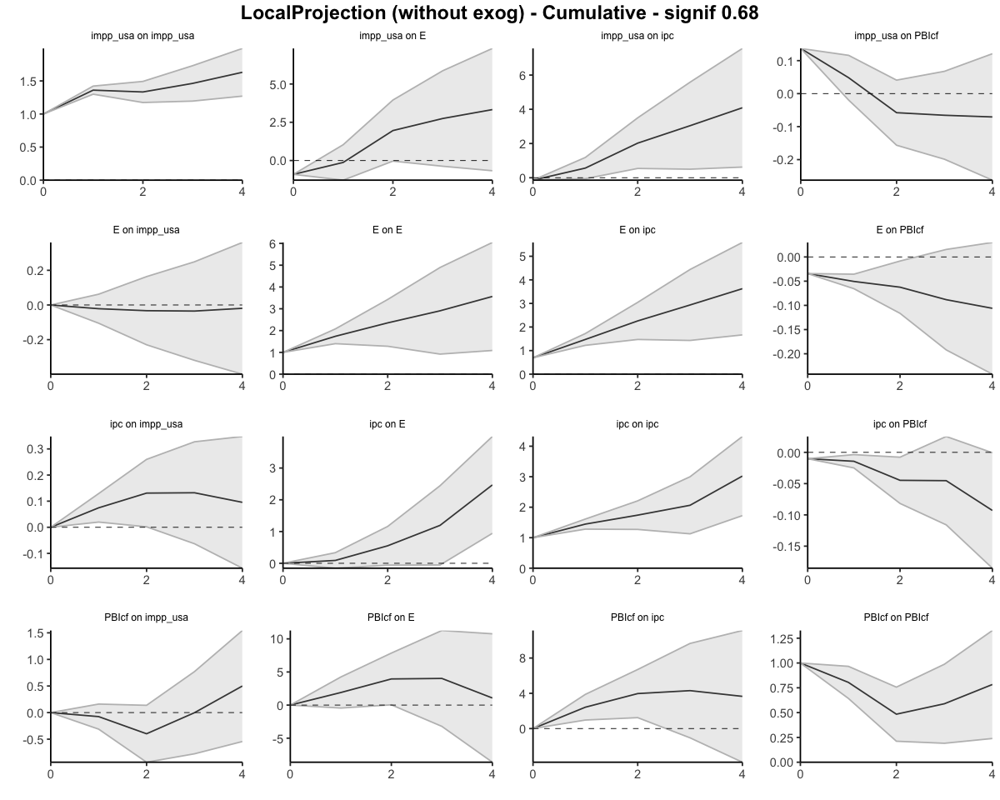

In [88]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("impp_usa", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

#### Todas endógenas - 1 lag

Bootstrap por bloques circular: 500 réplicas, bloques de 10 años...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 1 rezagos )

Lineal
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.6948         0.6948       1.0000
         1              1.4729         0.8475       1.7379
         2              2.2584         0.9594       2.3540
         3              2.9345         1.0093       2.9074
         4              3.6255         1.0169       3.5654
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.6948             0.6948
                  0.7781             0.1527
                  0.7855             0.1119
                  0.6761             0.0499
                  0.6910             0.0075


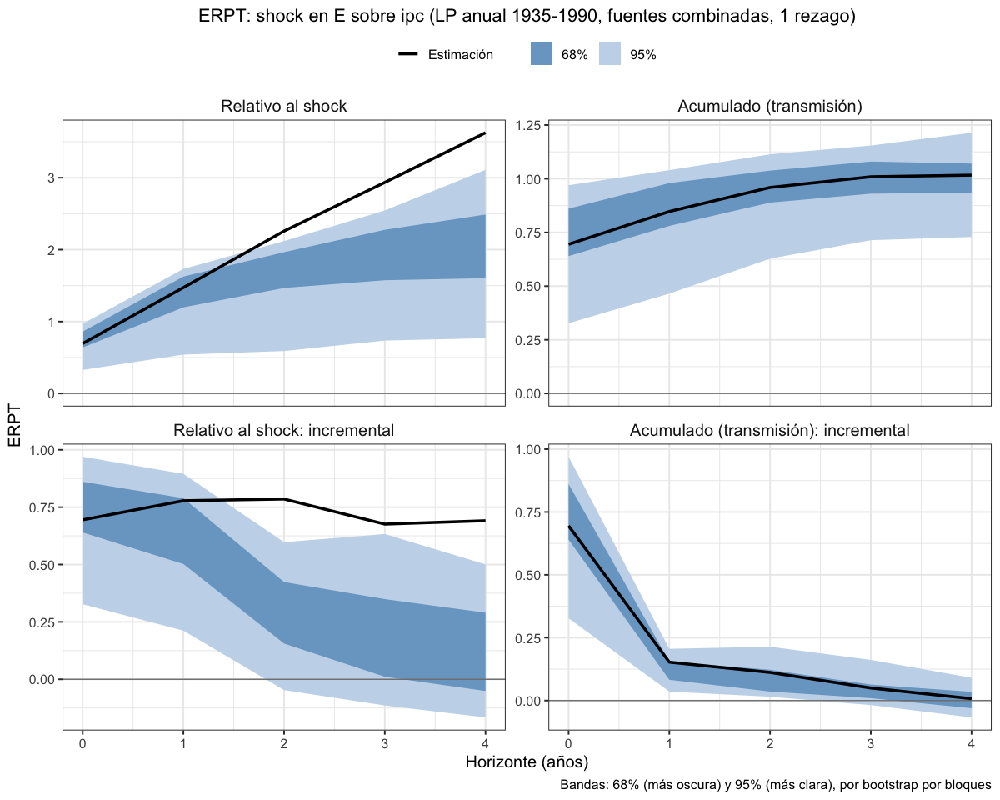

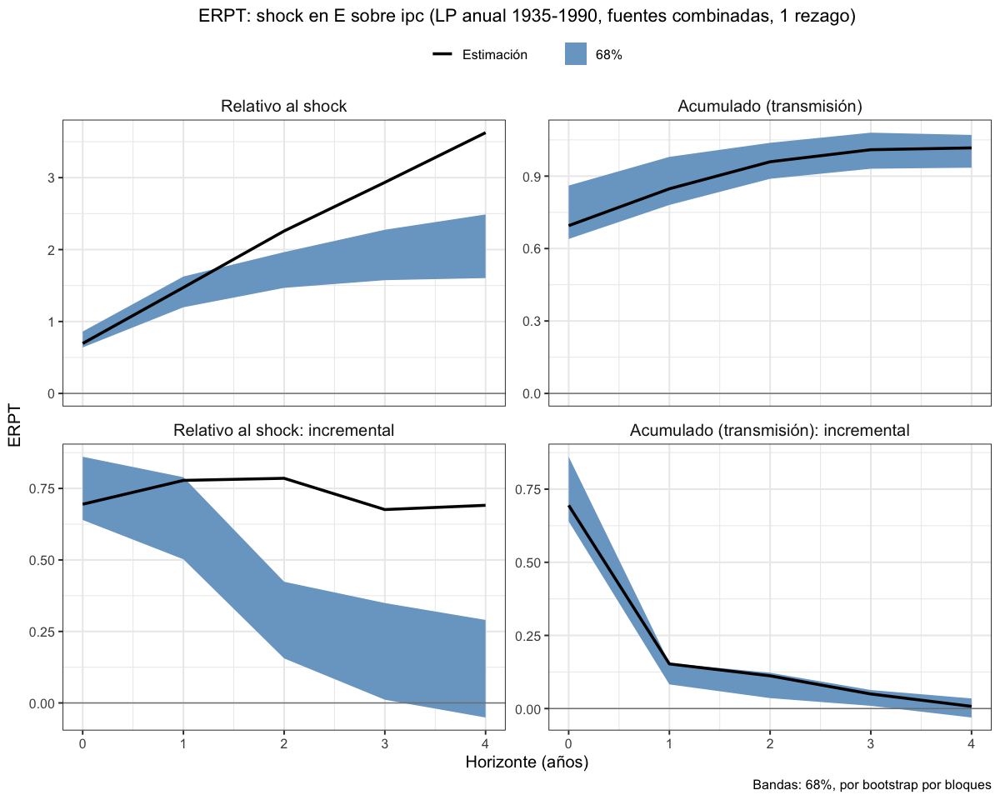

In [89]:
# Anual 1935–1990, fuentes combinadas. Todas endógenas, 1 rezago
lp_erpt_anual_comb_35_90_endog_p1 <- erpt_lp(df_ERPT_Arg_1935_1990, endog = c("impp_usa", "E", "ipc", "PBIcf"),
                                             fixed_lags = 1, horizons = 4, reps = 500, unidad = "años")
saveRDS(lp_erpt_anual_comb_35_90_endog_p1, "lp_erpt_anual_comb_35_90_endog_p1.rds")
titulo_comb_35_90 <- "ERPT: shock en E sobre ipc (LP anual 1935-1990, fuentes combinadas, 1 rezago)"
graficar_erpt_lp(lp_erpt_anual_comb_35_90_endog_p1, titulo = titulo_comb_35_90,
                 archivo = "lp_erpt_anual_comb_35_90_endog_p1")
graficar_erpt_lp(lp_erpt_anual_comb_35_90_endog_p1, titulo = titulo_comb_35_90, niveles = 0.68,
                 archivo = "lp_erpt_anual_comb_35_90_endog_p1_68")

### 1935-1990. 1 exógena y el resto endógenas - Selected orders: 1 y 4 lags

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.0000000
12,ipc,E,1,0.1153319,-0.16007074,0.3907346
13,ipc,E,2,0.4880966,0.10261059,0.8735825
14,ipc,E,3,0.6440612,-0.03822999,1.3263525
15,ipc,E,4,1.2354252,0.92647677,1.5443737


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.00000000,0.0000000,0.0000000
22,PBIcf,E,1,1.89912660,-0.4458051,4.2440584
23,PBIcf,E,2,2.04910620,0.4876915,3.6105209
24,PBIcf,E,3,0.07737643,-3.2555813,3.4103342
25,PBIcf,E,4,-2.95526116,-5.4128759,-0.4976464


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6851324,0.68513240,0.6851324
2,E,ipc,1,0.7684516,0.52298986,1.0139133
3,E,ipc,2,0.7792280,0.24837205,1.3100840
4,E,ipc,3,0.6722562,-0.03476903,1.3792814
5,E,ipc,4,0.6831522,0.23558196,1.1307225


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.0000000,0.0000000,0.000000
27,PBIcf,ipc,1,2.4237750,0.9685301,3.879020
28,PBIcf,ipc,2,1.5458925,0.2710475,2.820737
29,PBIcf,ipc,3,0.3339236,-2.2890320,2.956879
30,PBIcf,ipc,4,-0.6493261,-2.7652936,1.466641


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.03641225,-0.03641225,-0.03641225
7,E,PBIcf,1,-0.01576576,-0.03027037,-0.00126115
8,E,PBIcf,2,-0.01087955,-0.04945629,0.02769719
9,E,PBIcf,3,-0.02602532,-0.07511014,0.02305951
10,E,PBIcf,4,-0.01782748,-0.04960966,0.01395470


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,0.0029474859,0.002947486,0.002947486
17,ipc,PBIcf,1,-0.0066747513,-0.019438775,0.006089272
18,ipc,PBIcf,2,-0.0346616227,-0.062451372,-0.006871874
19,ipc,PBIcf,3,0.0008289252,-0.034481300,0.036139150
20,ipc,PBIcf,4,-0.0451023131,-0.068668038,-0.021536589


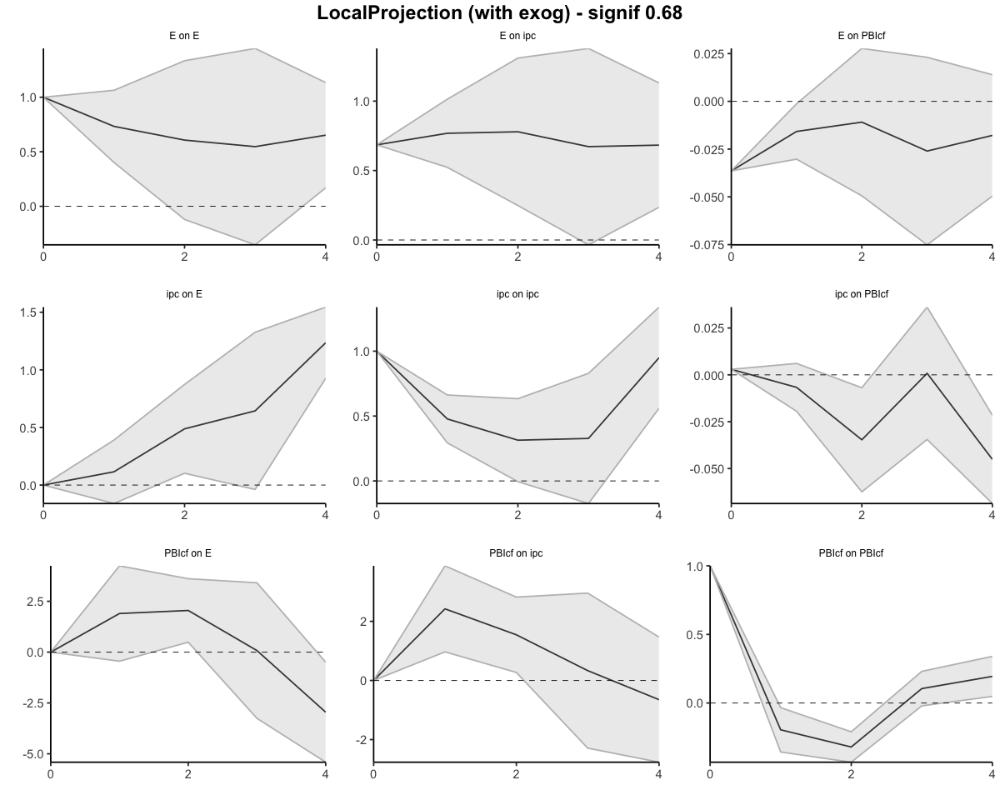

In [90]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIcf"), exog=c("impp_usa"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.0000000
12,ipc,E,1,0.1153319,-0.16007074,0.3907346
13,ipc,E,2,0.6034285,-0.05746015,1.2643172
14,ipc,E,3,1.2474897,-0.09569014,2.5906696
15,ipc,E,4,2.4829150,0.83078663,4.1350433


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.000000,0.00000000,0.000000
22,PBIcf,E,1,1.899127,-0.44580514,4.244058
23,PBIcf,E,2,3.948233,0.04188637,7.854579
24,PBIcf,E,3,4.025609,-3.21369493,11.264913
25,PBIcf,E,4,1.070348,-8.62657083,10.767267


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6851324,0.6851324,0.6851324
2,E,ipc,1,1.4535840,1.2081223,1.6990457
3,E,ipc,2,2.2328120,1.4564943,3.0091297
4,E,ipc,3,2.9050682,1.4217253,4.3884110
5,E,ipc,4,3.5882204,1.6573072,5.5191336


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.0000000,0.000000
27,PBIcf,ipc,1,2.423775,0.9685301,3.879020
28,PBIcf,ipc,2,3.969667,1.2395776,6.699757
29,PBIcf,ipc,3,4.303591,-1.0494544,9.656637
30,PBIcf,ipc,4,3.654265,-3.8147479,11.123278


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.03641225,-0.03641225,-0.036412246
7,E,PBIcf,1,-0.05217800,-0.06668261,-0.037673396
8,E,PBIcf,2,-0.06305755,-0.11613890,-0.009976202
9,E,PBIcf,3,-0.08908287,-0.19124905,0.013083308
10,E,PBIcf,4,-0.10691035,-0.24085871,0.027038012


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,0.002947486,0.002947486,0.002947486
17,ipc,PBIcf,1,-0.003727265,-0.016491289,0.009036758
18,ipc,PBIcf,2,-0.038388888,-0.078942661,0.002164885
19,ipc,PBIcf,3,-0.037559963,-0.113423961,0.038304035
20,ipc,PBIcf,4,-0.082662276,-0.182091998,0.016767446


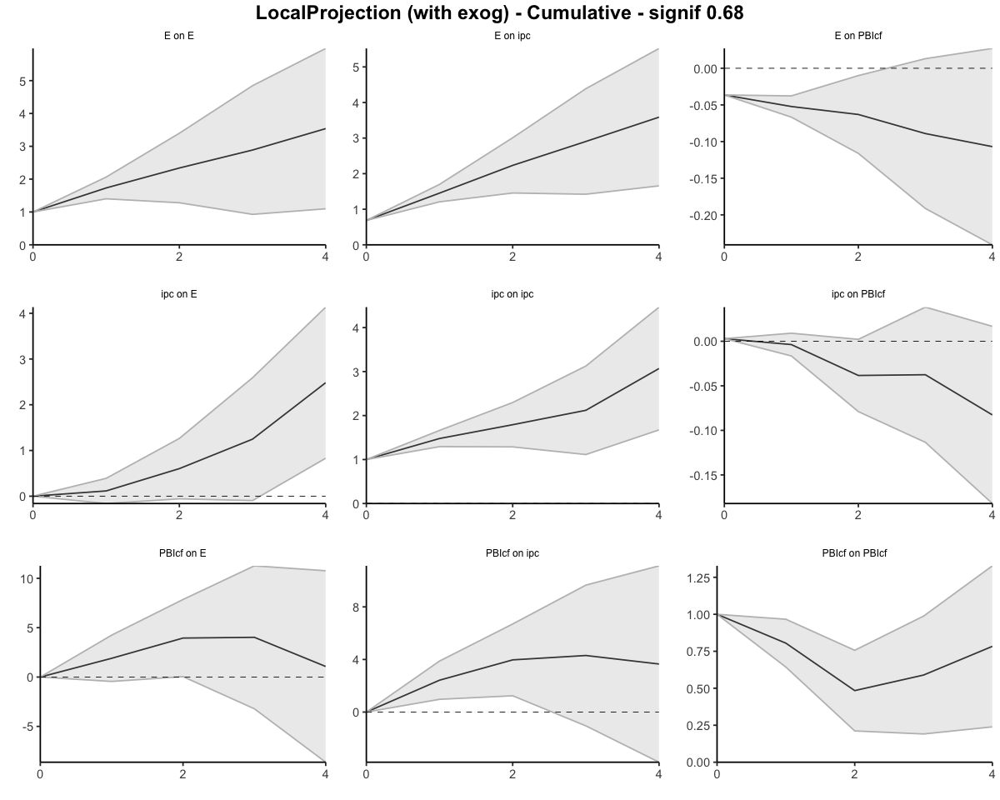

In [91]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIcf"), exog=c("impp_usa"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

#### impp_usa exógena y el resto endógenas - 1 lag

Bootstrap por bloques circular: 500 réplicas, bloques de 10 años...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 1 rezagos, exógenas: impp_usa )

Lineal
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.6851         0.6851       1.0000
         1              1.4536         0.8388       1.7328
         2              2.2328         0.9542       2.3399
         3              2.9051         1.0063       2.8870
         4              3.5882         1.0139       3.5391
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.6851             0.6851
                  0.7685             0.1537
                  0.7792             0.1154
                  0.6723             0.0520
                  0.6832             0.0076


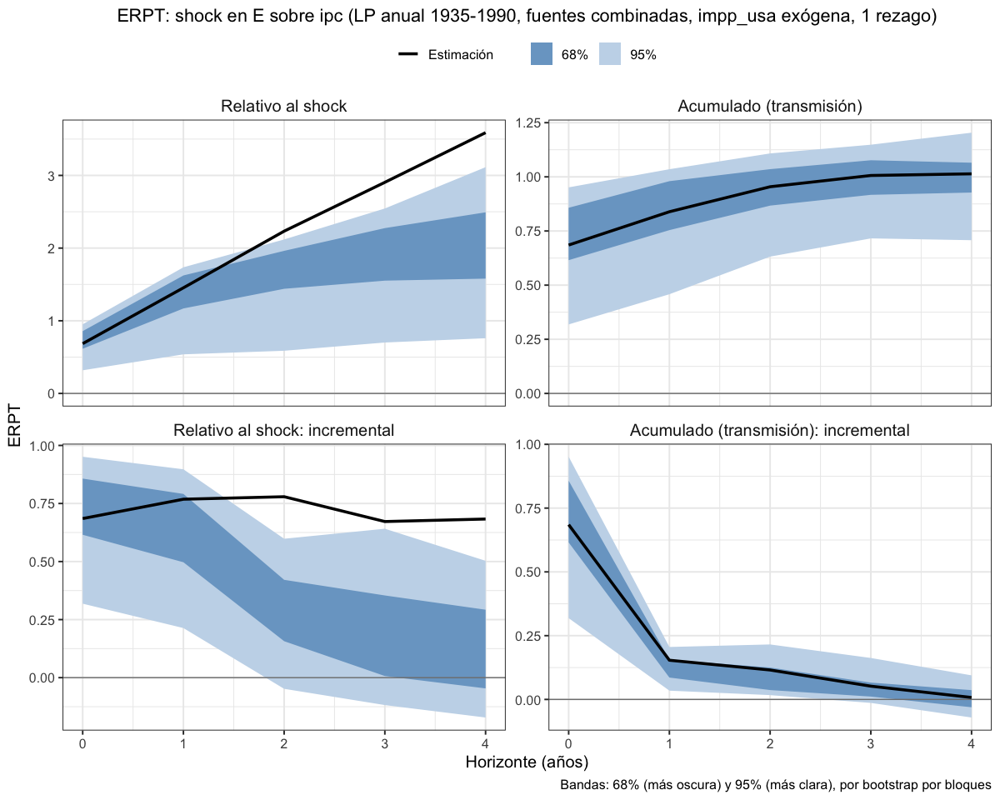

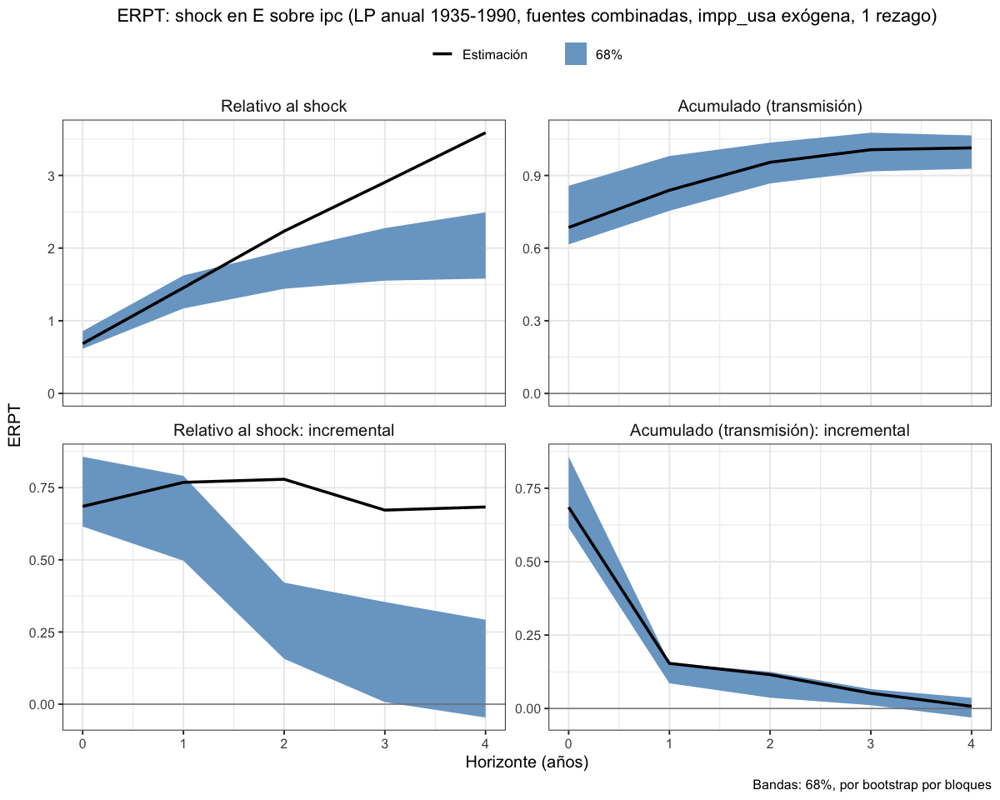

In [92]:
# Anual 1935–1990, fuentes combinadas. impp_usa exógena y el resto endógenas, 1 rezago
lp_erpt_anual_comb_35_90_exog_p1 <- erpt_lp(df_ERPT_Arg_1935_1990, endog = c("E", "ipc", "PBIcf"), exog = c("impp_usa"),
                                            fixed_lags = 1, horizons = 4, reps = 500, unidad = "años")
saveRDS(lp_erpt_anual_comb_35_90_exog_p1, "lp_erpt_anual_comb_35_90_exog_p1.rds")
titulo_comb_35_90_exog_p1 <- "ERPT: shock en E sobre ipc (LP anual 1935-1990, fuentes combinadas, impp_usa exógena, 1 rezago)"
graficar_erpt_lp(lp_erpt_anual_comb_35_90_exog_p1, titulo = titulo_comb_35_90_exog_p1,
                 archivo = "lp_erpt_anual_comb_35_90_exog_p1")
graficar_erpt_lp(lp_erpt_anual_comb_35_90_exog_p1, titulo = titulo_comb_35_90_exog_p1, niveles = 0.68,
                 archivo = "lp_erpt_anual_comb_35_90_exog_p1_68")

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.0000000
12,ipc,E,1,-0.02904107,-0.3651833,0.3071012
13,ipc,E,2,-0.07993566,-0.4416461,0.2817748
14,ipc,E,3,-1.16346916,-1.7466460,-0.5802924
15,ipc,E,4,-0.39804353,-0.6935303,-0.1025567


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.000000,0.0000000,0.0000000
22,PBIcf,E,1,2.817655,0.7702677,4.8650416
23,PBIcf,E,2,1.193198,-0.3206097,2.7070051
24,PBIcf,E,3,-1.898363,-3.7185504,-0.0781761
25,PBIcf,E,4,-3.763225,-5.0361974,-2.4902529


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.70690694,0.7069069,0.7069069
2,E,ipc,1,0.79173358,0.5258006,1.0576666
3,E,ipc,2,0.66847094,0.1584879,1.1784540
4,E,ipc,3,0.06651939,-0.6812019,0.8142407
5,E,ipc,4,0.09529023,-0.5587805,0.7493610


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.0000000,0.0000000,0.00000000
27,PBIcf,ipc,1,2.8142744,1.2831640,4.34538470
28,PBIcf,ipc,2,0.7684694,-0.3871283,1.92406701
29,PBIcf,ipc,3,-1.3002106,-2.6228340,0.02241272
30,PBIcf,ipc,4,-1.6200771,-3.0126837,-0.22747061


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.033550958,-0.03355096,-0.03355096
7,E,PBIcf,1,-0.010222644,-0.03770730,0.01726201
8,E,PBIcf,2,-0.005918005,-0.04243948,0.03060347
9,E,PBIcf,3,-0.012427415,-0.07242207,0.04756724
10,E,PBIcf,4,-0.005762694,-0.04125619,0.02973081


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.025574734,-0.025574734,-0.025574734
17,ipc,PBIcf,1,0.027808423,0.007470456,0.048146391
18,ipc,PBIcf,2,-0.015849305,-0.038842768,0.007144158
19,ipc,PBIcf,3,0.048890296,0.006383464,0.091397127
20,ipc,PBIcf,4,0.007109956,-0.018835147,0.033055060


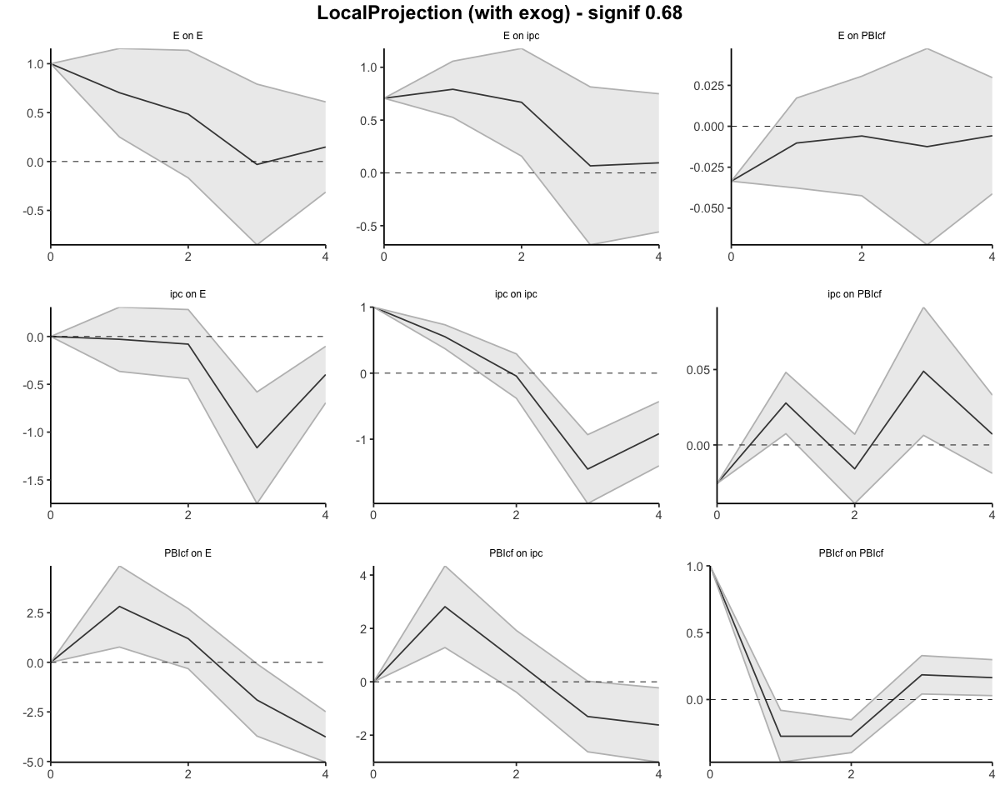

In [93]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIcf"), exog=c("impp_usa"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.000000000
12,ipc,E,1,-0.02904107,-0.3651833,0.307101161
13,ipc,E,2,-0.10897674,-0.8068294,0.588875917
14,ipc,E,3,-1.27244590,-2.5534754,0.008583564
15,ipc,E,4,-1.67048943,-3.2470057,-0.093973150


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.000000,0.0000000,0.000000
22,PBIcf,E,1,2.817655,0.7702677,4.865042
23,PBIcf,E,2,4.010852,0.4496580,7.572047
24,PBIcf,E,3,2.112489,-3.2688925,7.493871
25,PBIcf,E,4,-1.650736,-8.3050899,5.003618


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.7069069,0.7069069,0.7069069
2,E,ipc,1,1.4986405,1.2327075,1.7645735
3,E,ipc,2,2.1671115,1.3911954,2.9430275
4,E,ipc,3,2.2336308,0.7099935,3.7572682
5,E,ipc,4,2.3289211,0.1512129,4.5066292


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.0000000,0.0000000,0.000000
27,PBIcf,ipc,1,2.8142744,1.2831640,4.345385
28,PBIcf,ipc,2,3.5827437,0.8960357,6.269452
29,PBIcf,ipc,3,2.2825331,-1.7267983,6.291864
30,PBIcf,ipc,4,0.6624559,-4.7394819,6.064394


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.03355096,-0.03355096,-0.03355096
7,E,PBIcf,1,-0.04377360,-0.07125826,-0.01628895
8,E,PBIcf,2,-0.04969161,-0.11369773,0.01431452
9,E,PBIcf,3,-0.06211902,-0.18611980,0.06188176
10,E,PBIcf,4,-0.06788172,-0.22737599,0.09161256


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.025574734,-0.02557473,-0.02557473
17,ipc,PBIcf,1,0.002233689,-0.01810428,0.02257166
18,ipc,PBIcf,2,-0.013615616,-0.05694705,0.02971581
19,ipc,PBIcf,3,0.035274679,-0.05056358,0.12111294
20,ipc,PBIcf,4,0.042384636,-0.06939873,0.15416800


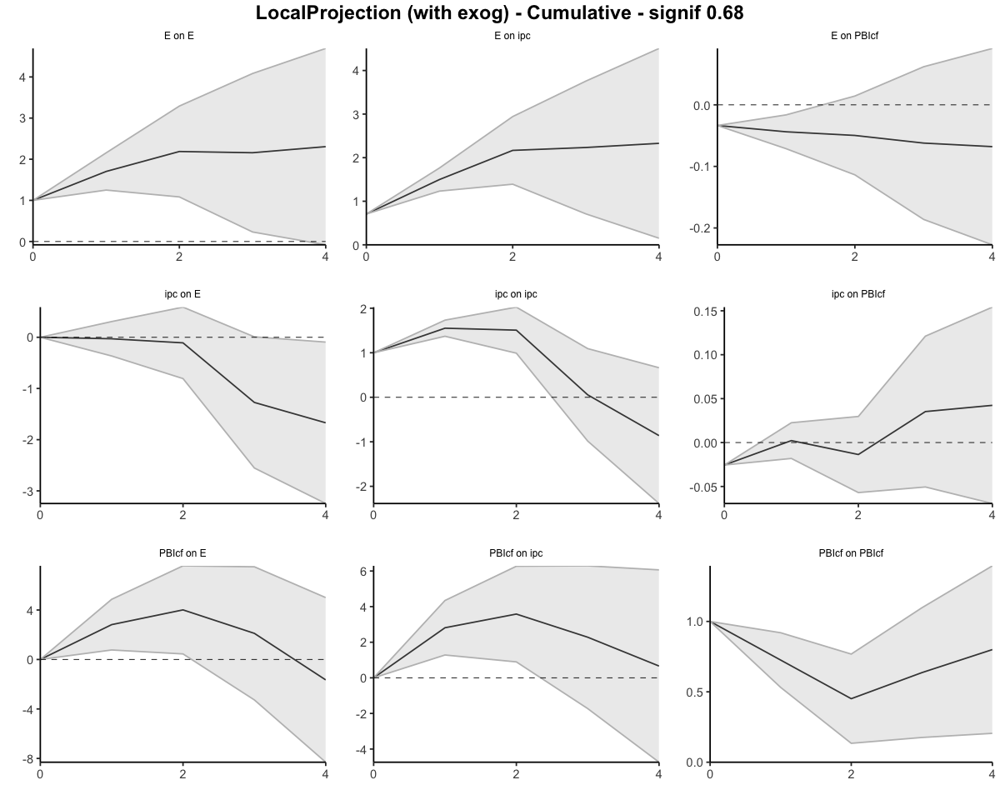

In [94]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIcf"), exog=c("impp_usa"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

#### impp_usa exógena y el resto endógenas - 2 lags

Bootstrap por bloques circular: 500 réplicas, bloques de 12 años...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 2 rezagos, exógenas: impp_usa )

Lineal
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.7069         0.7069       1.0000
         1              1.4986         0.8799       1.7032
         2              2.1671         0.9905       2.1880
         3              2.2336         1.0351       2.1578
         4              2.3289         1.0099       2.3062
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.7069             0.7069
                  0.7917             0.1730
                  0.6685             0.1106
                  0.0665             0.0447
                  0.0953            -0.0253


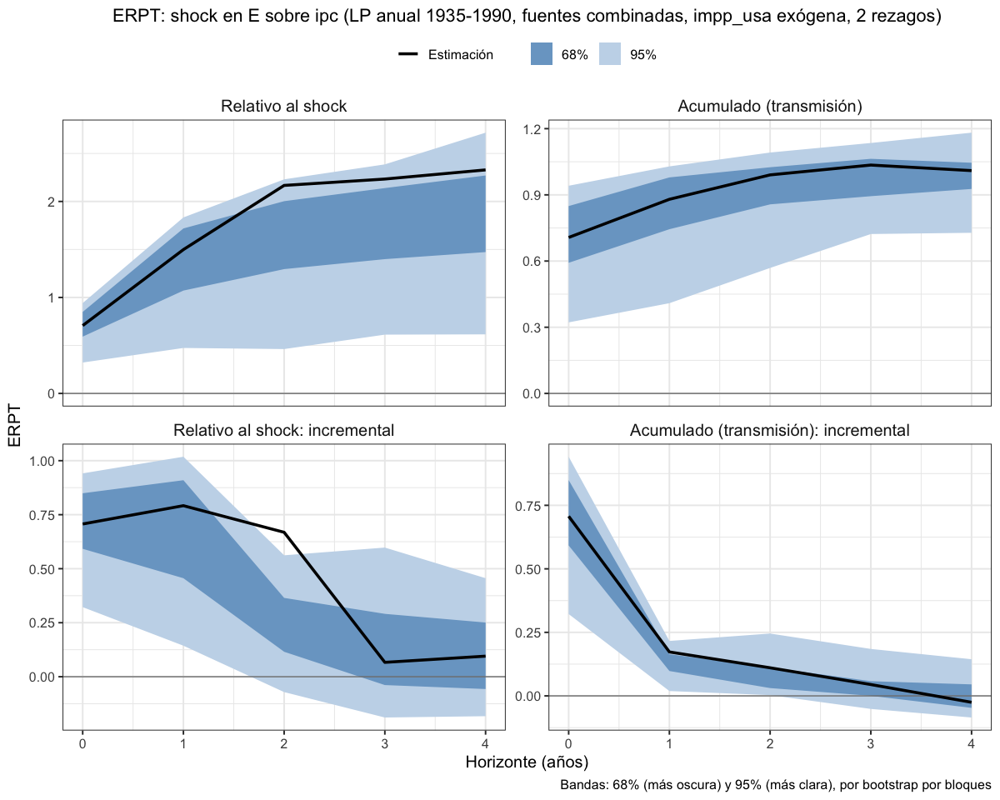

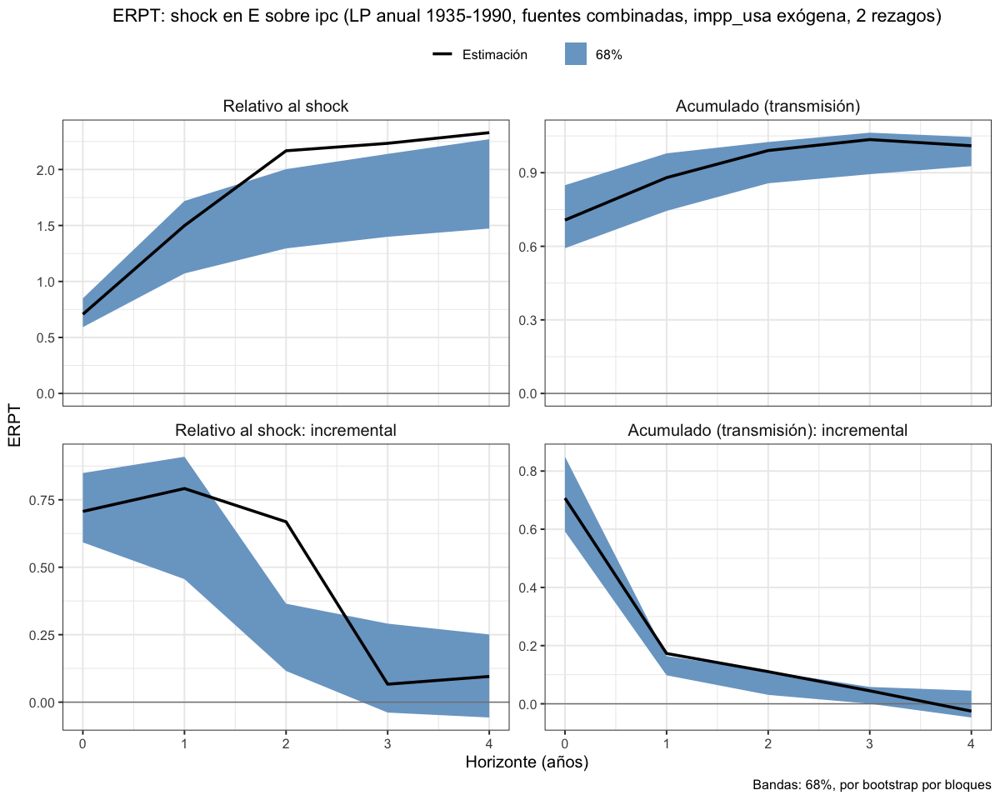

In [95]:
# Anual 1935–1990, fuentes combinadas. impp_usa exógena y el resto endógenas, 2 rezagos
lp_erpt_anual_comb_35_90_exog_p2 <- erpt_lp(df_ERPT_Arg_1935_1990, endog = c("E", "ipc", "PBIcf"), exog = c("impp_usa"),
                                            fixed_lags = 2, horizons = 4, reps = 500, unidad = "años")
saveRDS(lp_erpt_anual_comb_35_90_exog_p2, "lp_erpt_anual_comb_35_90_exog_p2.rds")
titulo_comb_35_90_exog_p2 <- "ERPT: shock en E sobre ipc (LP anual 1935-1990, fuentes combinadas, impp_usa exógena, 2 rezagos)"
graficar_erpt_lp(lp_erpt_anual_comb_35_90_exog_p2, titulo = titulo_comb_35_90_exog_p2,
                 archivo = "lp_erpt_anual_comb_35_90_exog_p2")
graficar_erpt_lp(lp_erpt_anual_comb_35_90_exog_p2, titulo = titulo_comb_35_90_exog_p2, niveles = 0.68,
                 archivo = "lp_erpt_anual_comb_35_90_exog_p2_68")

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
4,NA,NaN,NA,4,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.00000000
12,ipc,E,1,-0.38626179,-0.8293919,0.05686829
13,ipc,E,2,-0.14973232,-0.6076839,0.30821928
14,ipc,E,3,-0.84634472,-1.4914977,-0.20119169
15,ipc,E,4,-0.03158824,-0.3984050,0.33522855


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.000000,0.0000000,0.0000000
22,PBIcf,E,1,2.718900,0.8353852,4.6024157
23,PBIcf,E,2,1.023579,-0.5789715,2.6261287
24,PBIcf,E,3,-1.067046,-2.6968092,0.5627166
25,PBIcf,E,4,-3.265342,-4.6164958,-1.9141886


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6395003152,0.6395003,0.6395003
2,E,ipc,1,0.7184346694,0.2327062,1.2041631
3,E,ipc,2,0.3336656370,-0.5281074,1.1954387
4,E,ipc,3,0.0003981135,-0.8163321,0.8171283
5,E,ipc,4,0.1947256586,-5.7828008,6.1722521


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.0000000,0.0000000,0.0000000
27,PBIcf,ipc,1,3.1174873,1.5038328,4.7311419
28,PBIcf,ipc,2,1.1770265,-0.6359852,2.9900381
29,PBIcf,ipc,3,-0.5985611,-1.9694508,0.7723285
30,PBIcf,ipc,4,-1.0635313,-3.7123771,1.5853145


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.026777436,-0.02677744,-0.02677744
7,E,PBIcf,1,-0.009510906,-0.04173948,0.02271767
8,E,PBIcf,2,-0.004259188,-0.04982386,0.04130549
9,E,PBIcf,3,-0.012119881,-0.08348188,0.05924212
10,E,PBIcf,4,-0.016050000,-0.05695376,0.02485376


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.02901287,-0.02901287,-0.02901287
17,ipc,PBIcf,1,0.05572540,0.03276930,0.07868149
18,ipc,PBIcf,2,-0.05768277,-0.09068376,-0.02468177
19,ipc,PBIcf,3,0.03959569,-0.01122802,0.09041940
20,ipc,PBIcf,4,-0.01565021,-0.04795164,0.01665122


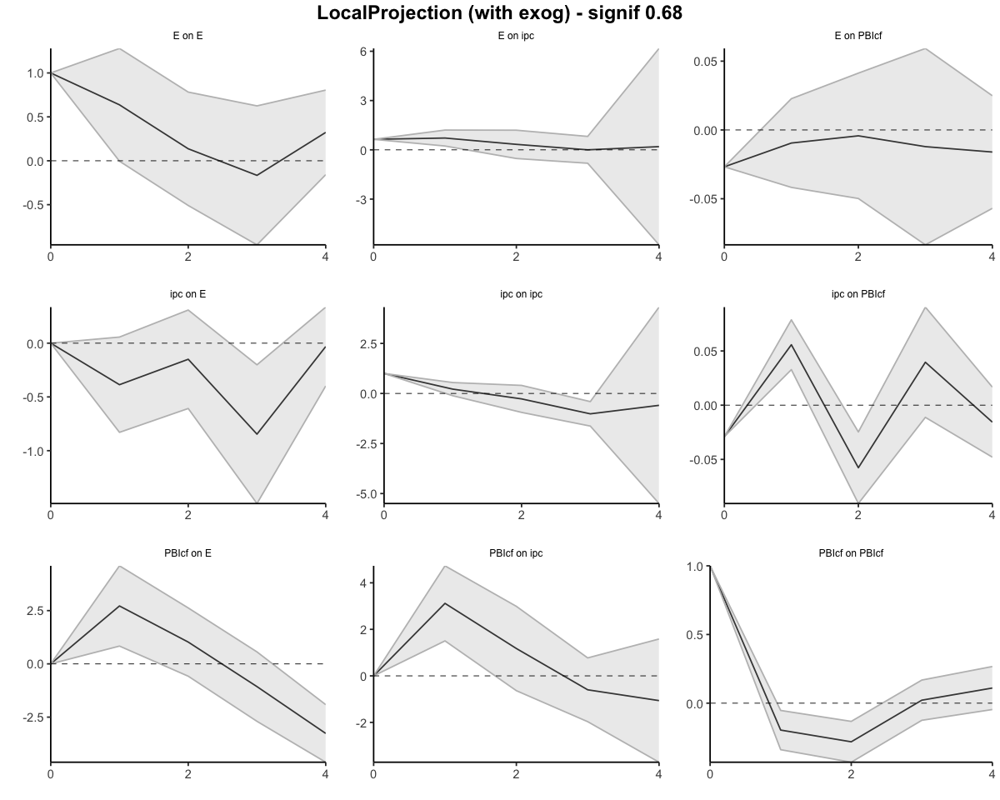

In [96]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIcf"), exog=c("impp_usa"), fixed_lags = 4, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
4,NA,NaN,NA,4,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.00000000
12,ipc,E,1,-0.3862618,-0.8293919,0.05686829
13,ipc,E,2,-0.5359941,-1.4370758,0.36508757
14,ipc,E,3,-1.3823388,-2.9285735,0.16389589
15,ipc,E,4,-1.4139271,-3.3269786,0.49912444


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.0000000,0.000000
22,PBIcf,E,1,2.7189004,0.8353852,4.602416
23,PBIcf,E,2,3.7424791,0.2564137,7.228544
24,PBIcf,E,3,2.6754328,-2.4403955,7.791261
25,PBIcf,E,4,-0.5899094,-7.0568913,5.877072


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6395003,0.6395003,0.6395003
2,E,ipc,1,1.3579350,0.8722065,1.8436635
3,E,ipc,2,1.6916006,0.3440991,3.0391021
4,E,ipc,3,1.6919987,-0.4722330,3.8562304
5,E,ipc,4,1.8867244,-6.2550338,10.0284826


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.0000000,0.000000
27,PBIcf,ipc,1,3.117487,1.5038328,4.731142
28,PBIcf,ipc,2,4.294514,0.8678476,7.721180
29,PBIcf,ipc,3,3.695953,-1.1016032,8.493509
30,PBIcf,ipc,4,2.632421,-4.8139803,10.078823


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.02677744,-0.02677744,-0.026777436
7,E,PBIcf,1,-0.03628834,-0.06851691,-0.004059771
8,E,PBIcf,2,-0.04054753,-0.11834078,0.037245716
9,E,PBIcf,3,-0.05266741,-0.20182266,0.096487834
10,E,PBIcf,4,-0.06871741,-0.25877641,0.121341593


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.029012870,-0.029012870,-0.02901287
17,ipc,PBIcf,1,0.026712528,0.003756434,0.04966862
18,ipc,PBIcf,2,-0.030970238,-0.086927326,0.02498685
19,ipc,PBIcf,3,0.008625452,-0.098155347,0.11540625
20,ipc,PBIcf,4,-0.007024757,-0.146106988,0.13205747


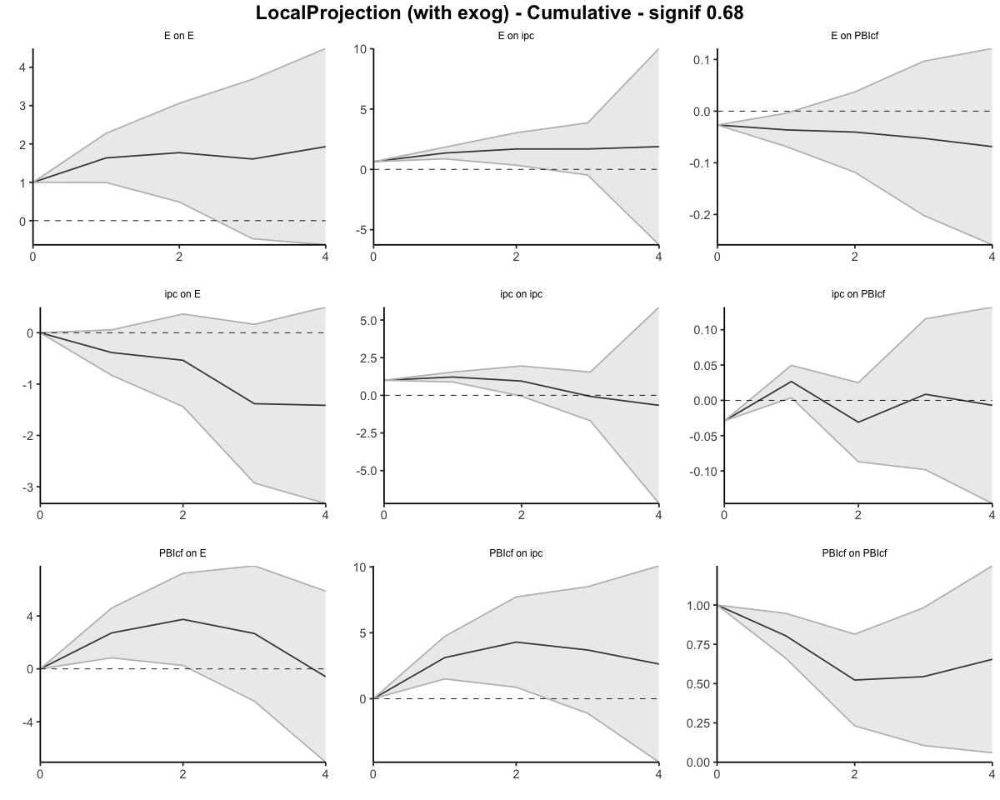

In [97]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIcf"), exog=c("impp_usa"), fixed_lags = 4, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

#### impp_usa exógena y el resto endógenas - 4 lags

Bootstrap por bloques circular: 500 réplicas, bloques de 16 años...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 4 rezagos, exógenas: impp_usa )

Lineal
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.6395         0.6395       1.0000
         1              1.3579         0.8295       1.6371
         2              1.6916         0.9537       1.7736
         3              1.6920         1.0525       1.6076
         4              1.8867         0.9772       1.9307
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.6395             0.6395
                  0.7184             0.1900
                  0.3337             0.1243
                  0.0004             0.0988
                  0.1947            -0.0753


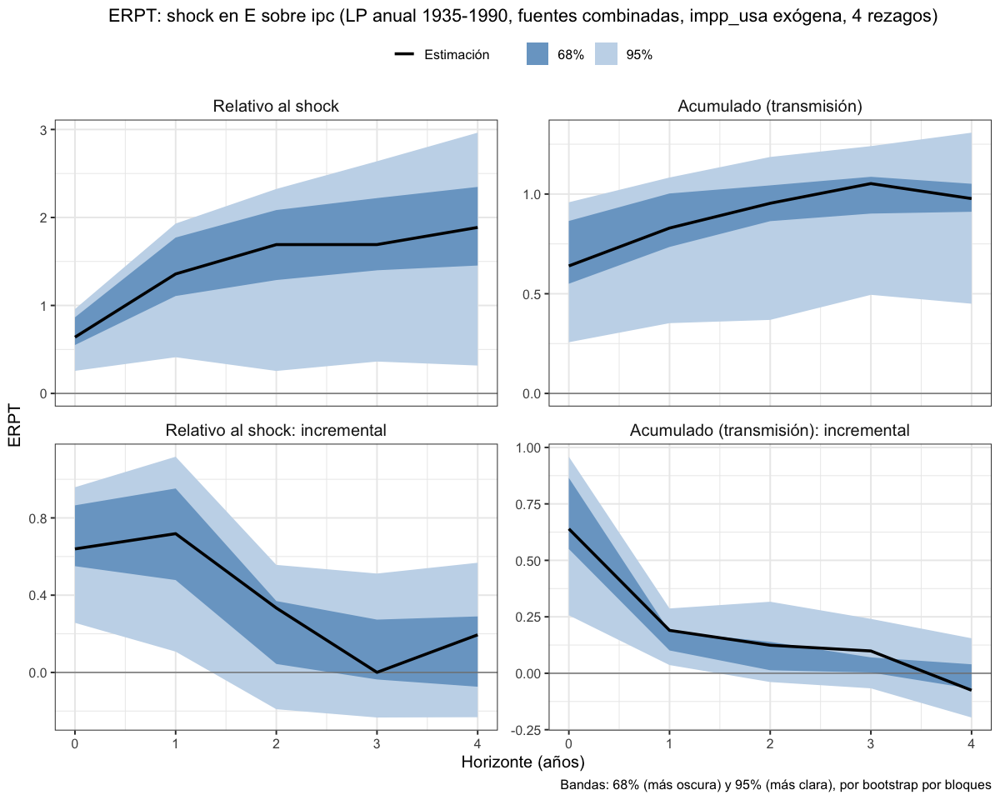

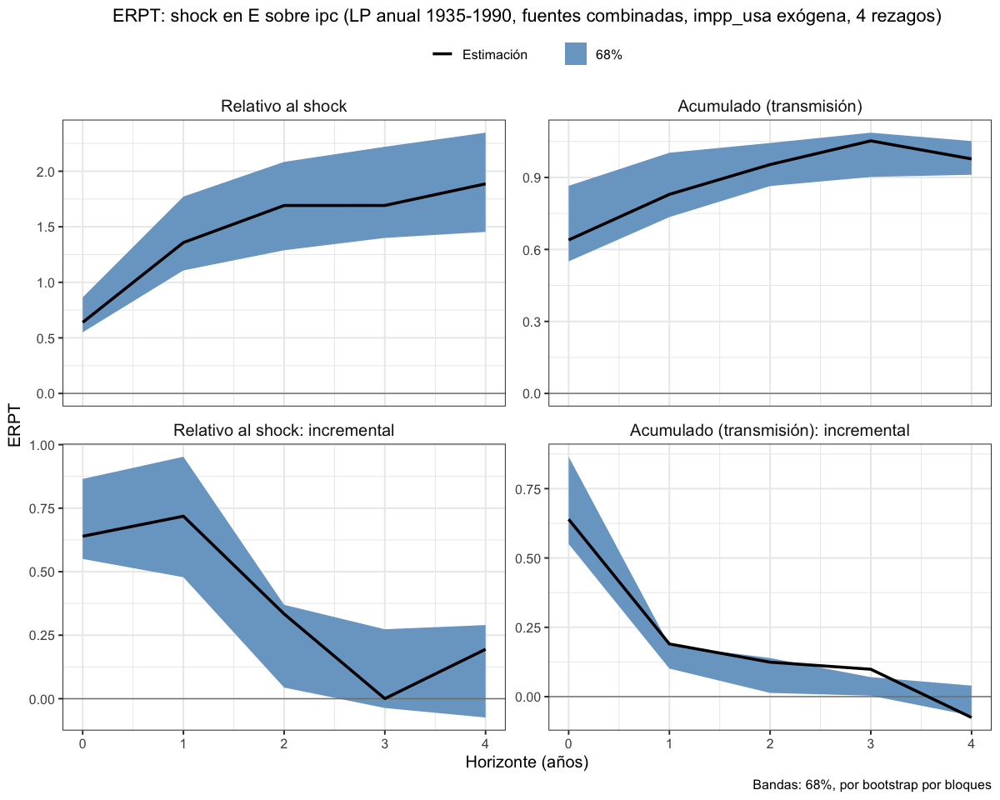

In [98]:
# Anual 1935–1990, fuentes combinadas. impp_usa exógena y el resto endógenas, 4 rezagos
lp_erpt_anual_comb_35_90_exog_p4 <- erpt_lp(df_ERPT_Arg_1935_1990, endog = c("E", "ipc", "PBIcf"), exog = c("impp_usa"),
                                            fixed_lags = 4, horizons = 4, reps = 500, unidad = "años")
saveRDS(lp_erpt_anual_comb_35_90_exog_p4, "lp_erpt_anual_comb_35_90_exog_p4.rds")
titulo_comb_35_90_exog_p4 <- "ERPT: shock en E sobre ipc (LP anual 1935-1990, fuentes combinadas, impp_usa exógena, 4 rezagos)"
graficar_erpt_lp(lp_erpt_anual_comb_35_90_exog_p4, titulo = titulo_comb_35_90_exog_p4,
                 archivo = "lp_erpt_anual_comb_35_90_exog_p4")
graficar_erpt_lp(lp_erpt_anual_comb_35_90_exog_p4, titulo = titulo_comb_35_90_exog_p4, niveles = 0.68,
                 archivo = "lp_erpt_anual_comb_35_90_exog_p4_68")